# Chest X-ray Pneumonia Classification and Model Explainability

## Project Overview

This project investigates a CNN-based approach for classifying chest X-ray images into NORMAL and PNEUMONIA categories.

Beyond classification performance, the project explores model explainability and sensitivity to image regions, including:

- Grad-CAM visual explanations
- Padding and border sensitivity
- Marker-region sensitivity
- Controlled image perturbation experiments
- Corner-suppression fine-tuning

## Project Objectives

1. Develop and evaluate a CNN image-classification model.
2. Investigate which image regions influence model predictions.
3. Examine sensitivity to markers, padding, and image corners.
4. Compare baseline and border-suppression fine-tuned models.
5. Document experimental findings and limitations.

**Important:** This is an educational research prototype, not a clinically validated diagnostic system.



## 1. Dataset Preparation and Exploration

This section covers dataset organization, image paths, class labels, and the initial exploration of the chest X-ray dataset.

In [73]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd() / "data" / "raw" / "chest_xray" / "chest_xray"

# If notebook is running from notebooks/, go one level up
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data" / "raw" / "chest_xray" / "chest_xray"

print("Dataset path:", DATA_DIR)
print("Path exists:", DATA_DIR.exists())

normal_images = list((DATA_DIR / "train" / "NORMAL").glob("*.jpeg"))
pneumonia_images = list((DATA_DIR / "train" / "PNEUMONIA").glob("*.jpeg"))

print("Normal images:", len(normal_images))
print("Pneumonia images:", len(pneumonia_images))

Dataset path: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray
Path exists: True
Normal images: 1341
Pneumonia images: 3875


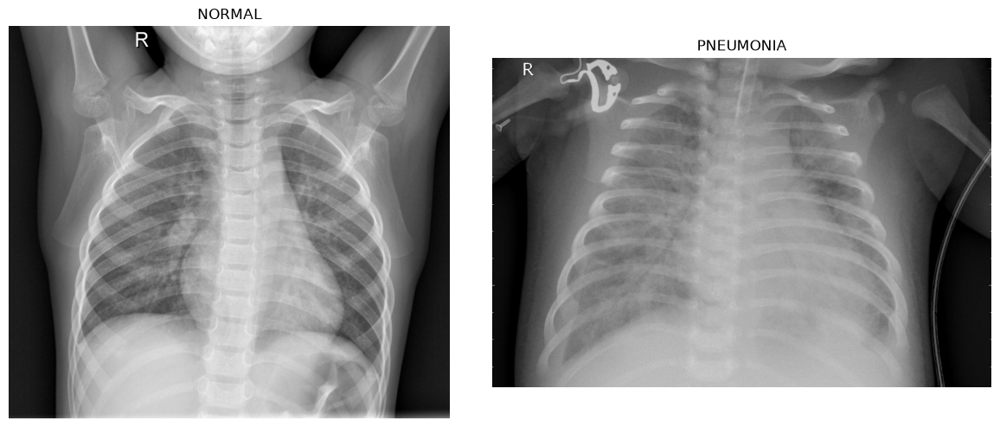

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

normal_img = Image.open(normal_images[0])
pneumonia_img = Image.open(pneumonia_images[0])

axes[0].imshow(normal_img, cmap="gray")
axes[0].set_title("NORMAL")
axes[0].axis("off")

axes[1].imshow(pneumonia_img, cmap="gray")
axes[1].set_title("PNEUMONIA")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path.cwd() / "data" / "raw" / "chest_xray" / "chest_xray"

if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data" / "raw" / "chest_xray" / "chest_xray"

normal_images = list((DATA_DIR / "train" / "NORMAL").glob("*.jpeg"))
pneumonia_images = list((DATA_DIR / "train" / "PNEUMONIA").glob("*.jpeg"))

print("Dataset:", DATA_DIR)
print("NORMAL:", len(normal_images))
print("PNEUMONIA:", len(pneumonia_images))

Dataset: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray
NORMAL: 1341
PNEUMONIA: 3875


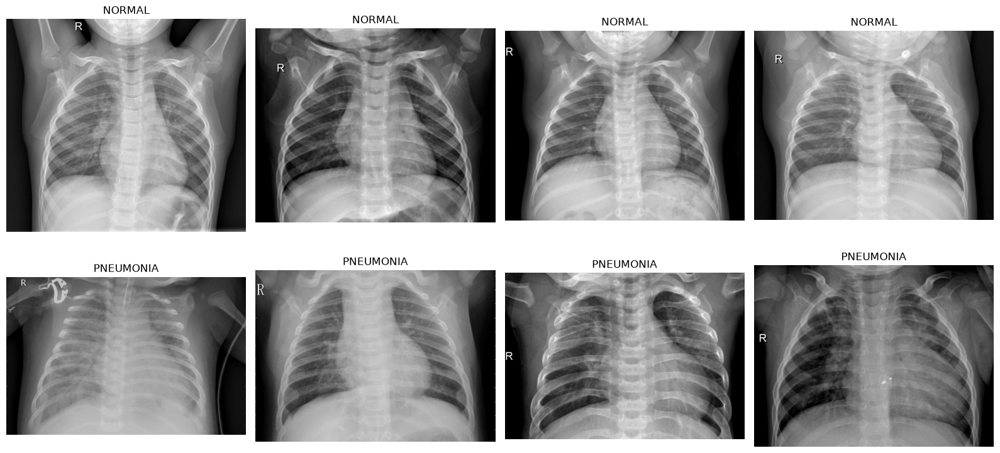

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    img = Image.open(normal_images[i])
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("NORMAL")
    axes[0, i].axis("off")

for i in range(4):
    img = Image.open(pneumonia_images[i])
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("PNEUMONIA")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

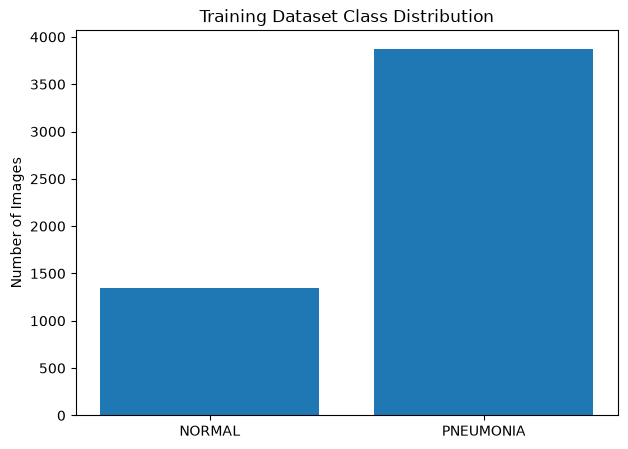

In [8]:
labels = ["NORMAL", "PNEUMONIA"]
counts = [len(normal_images), len(pneumonia_images)]

plt.figure(figsize=(7, 5))
plt.bar(labels, counts)
plt.title("Training Dataset Class Distribution")
plt.ylabel("Number of Images")
plt.show()

In [9]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

In [10]:
image = Image.open(normal_images[0]).convert("L")

print("Original size:", image.size)

processed = transform(image)

print("Tensor shape:", processed.shape)
print("Tensor dtype:", processed.dtype)
print("Minimum:", processed.min().item())
print("Maximum:", processed.max().item())

Original size: (2090, 1858)
Tensor shape: torch.Size([1, 224, 224])
Tensor dtype: torch.float32
Minimum: 0.0
Maximum: 0.9725490212440491


In [11]:
from src.dataset import ChestXrayDataset

In [12]:
image_paths = []
labels = []

for image_path in normal_images:
    image_paths.append(image_path)
    labels.append(0)

for image_path in pneumonia_images:
    image_paths.append(image_path)
    labels.append(1)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

Total images: 5216
Total labels: 5216


In [13]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [14]:
dataset = ChestXrayDataset(
    image_paths,
    labels,
    transform=transform
)

print("Dataset size:", len(dataset))

Dataset size: 5216


In [15]:
image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([1, 224, 224])
Label: 0


In [16]:
image, label = dataset[2000]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([1, 224, 224])
Label: 1


In [17]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [18]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 1, 224, 224])
Labels shape: torch.Size([32])


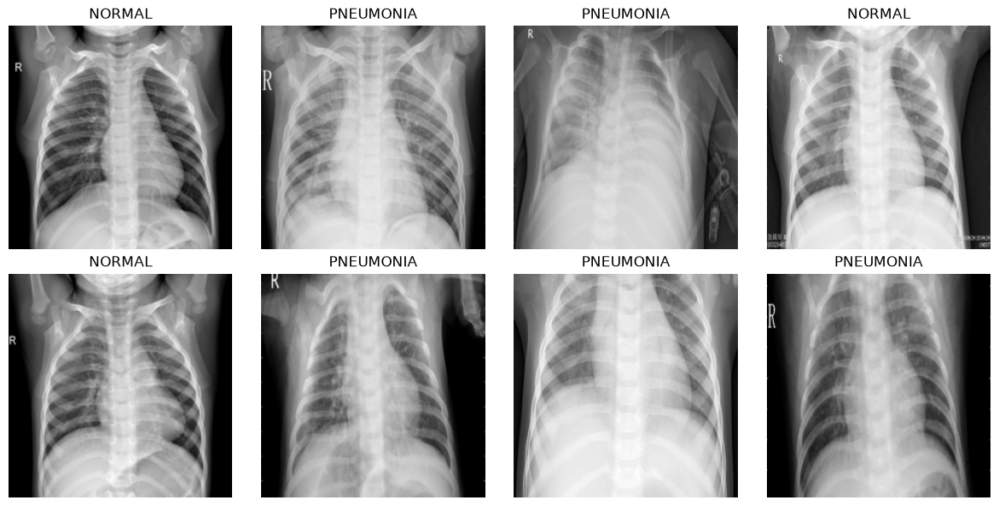

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    label_name = "PNEUMONIA" if labels[i].item() == 1 else "NORMAL"
    ax.set_title(label_name)

    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 1, 224, 224])
Labels shape: torch.Size([32])


In [21]:
from src.model import ChestXrayCNN

model = ChestXrayCNN()

print(model)

ChestXrayCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=1, bias=True)
  )
)


In [22]:
output = model(images)

print("Input:", images.shape)
print("Output:", output.shape)

Input: torch.Size([32, 1, 224, 224])
Output: torch.Size([32, 1])


In [23]:
import torch
import torch.nn as nn

In [24]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [25]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


In [26]:
images, labels = next(iter(train_loader))

labels = labels.float().unsqueeze(1)

In [27]:
print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([32, 1, 224, 224])
Labels: torch.Size([32, 1])


In [28]:
outputs = model(images)

print("Outputs:", outputs.shape)
print(outputs[:5])

Outputs: torch.Size([32, 1])
tensor([[ 0.0138],
        [-0.0054],
        [-0.0087],
        [-0.0058],
        [-0.0014]], grad_fn=<SliceBackward0>)


In [29]:
loss = criterion(outputs, labels)

print("Loss:", loss.item())

Loss: 0.6942610740661621


In [30]:
images, labels = next(iter(train_loader))

labels = labels.float().unsqueeze(1)

optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

optimizer.step()

print("Training step completed!")
print("Loss:", loss.item())

Training step completed!
Loss: 0.6934788227081299


### 1.1 Dataset Labels and Class Distribution

Reconstruct the dataset labels and verify the number of NORMAL and PNEUMONIA images before preparing the training and validation datasets.

In [31]:
# Recreate the complete labels list

all_labels = []

for image_path in normal_images:
    all_labels.append(0)

for image_path in pneumonia_images:
    all_labels.append(1)

print("Images:", len(image_paths))
print("Labels:", len(all_labels))

Images: 5216
Labels: 5216


In [ ]:
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))

In [ ]:
train_dataset = ChestXrayDataset(
    train_paths,
    train_labels,
    transform=transform
)

val_dataset = ChestXrayDataset(
    val_paths,
    val_labels,
    transform=transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders ready!")

In [35]:
from src.model import ChestXrayCNN
import torch
import torch.nn as nn

In [36]:
model = ChestXrayCNN()

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Fresh model ready!")

Fresh model ready!


In [37]:
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from src.dataset import ChestXrayDataset
from src.model import ChestXrayCNN

In [38]:
images, batch_labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", batch_labels.shape)

Images: torch.Size([32, 1, 224, 224])
Labels: torch.Size([32])


In [39]:
model.train()

running_loss = 0.0

for images, batch_labels in train_loader:

    batch_labels = batch_labels.float().unsqueeze(1)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, batch_labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item()

average_loss = running_loss / len(train_loader)

print("Training loss:", average_loss)

Training loss: 0.34881246166716096


In [40]:
model.eval()

val_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, batch_labels in val_loader:

        batch_labels = batch_labels.float().unsqueeze(1)

        outputs = model(images)

        loss = criterion(outputs, batch_labels)

        val_loss += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

average_val_loss = val_loss / len(val_loader)
val_accuracy = correct / total

print("Validation loss:", average_val_loss)
print("Validation accuracy:", val_accuracy)

Validation loss: 0.28186988175818417
Validation accuracy: 0.882183908045977


In [41]:
num_epochs = 5

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

In [42]:
for epoch in range(num_epochs):

    
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, batch_labels in train_loader:

        batch_labels = batch_labels.float().unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, batch_labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, batch_labels in val_loader:

            batch_labels = batch_labels.float().unsqueeze(1)

            outputs = model(images)

            loss = criterion(outputs, batch_labels)

            val_running_loss += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = val_correct / val_total

    # Store results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 1/5 | Train Loss: 0.1152 | Train Acc: 0.9554 | Val Loss: 0.0868 | Val Acc: 0.9636
Epoch 2/5 | Train Loss: 0.0750 | Train Acc: 0.9744 | Val Loss: 0.0840 | Val Acc: 0.9674
Epoch 3/5 | Train Loss: 0.0659 | Train Acc: 0.9760 | Val Loss: 0.0691 | Val Acc: 0.9713
Epoch 4/5 | Train Loss: 0.0525 | Train Acc: 0.9827 | Val Loss: 0.0907 | Val Acc: 0.9713
Epoch 5/5 | Train Loss: 0.0487 | Train Acc: 0.9830 | Val Loss: 0.0688 | Val Acc: 0.9780


In [43]:
import torch

model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():

    for images, batch_labels in val_loader:

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        all_predictions.extend(predictions.squeeze(1).tolist())
        all_true_labels.extend(batch_labels.tolist())

print("Predictions:", len(all_predictions))
print("True labels:", len(all_true_labels))

Predictions: 1044
True labels: 1044


In [44]:
from sklearn.metrics import classification_report, confusion_matrix

cm = confusion_matrix(
    all_true_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        all_true_labels,
        all_predictions,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

Confusion Matrix:
[[255  13]
 [ 10 766]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.96      0.95      0.96       268
   PNEUMONIA       0.98      0.99      0.99       776

    accuracy                           0.98      1044
   macro avg       0.97      0.97      0.97      1044
weighted avg       0.98      0.98      0.98      1044



In [45]:
torch.save(model.state_dict(), "models/chest_xray_cnn_epoch5.pth")

print("Model saved!")

Model saved!


In [46]:
model = ChestXrayCNN()
model.load_state_dict(
    torch.load("models/chest_xray_cnn_epoch5.pth")
)

<All keys matched successfully>

In [47]:
import torch
import torch.nn as nn

model = ChestXrayCNN()

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 5

best_val_loss = float("inf")

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

In [48]:
for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, batch_labels in train_loader:

        batch_labels = batch_labels.float().unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, batch_labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = correct / total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, batch_labels in val_loader:

            batch_labels = batch_labels.float().unsqueeze(1)

            outputs = model(images)

            loss = criterion(outputs, batch_labels)

            val_running_loss += loss.item()

            predictions = (torch.sigmoid(outputs) >= 0.5).float()

            val_correct += (predictions == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "models/best_chest_xray_cnn.pth"
        )

        print("  ✓ Best model saved!")

Epoch 1/5 | Train Loss: 0.2644 | Train Acc: 0.8785 | Val Loss: 0.0996 | Val Acc: 0.9579
  ✓ Best model saved!
Epoch 2/5 | Train Loss: 0.0834 | Train Acc: 0.9700 | Val Loss: 0.0758 | Val Acc: 0.9684
  ✓ Best model saved!
Epoch 3/5 | Train Loss: 0.0712 | Train Acc: 0.9753 | Val Loss: 0.0699 | Val Acc: 0.9732
  ✓ Best model saved!
Epoch 4/5 | Train Loss: 0.0596 | Train Acc: 0.9779 | Val Loss: 0.0624 | Val Acc: 0.9770
  ✓ Best model saved!
Epoch 5/5 | Train Loss: 0.0457 | Train Acc: 0.9839 | Val Loss: 0.0664 | Val Acc: 0.9732


In [49]:
model.load_state_dict(
    torch.load("models/best_chest_xray_cnn.pth")
)

model.eval()

print("Best model loaded!")

Best model loaded!


In [50]:
test_dir = Path("data/raw/chest_xray/chest_xray/test")

test_normal = list((test_dir / "NORMAL").glob("*.jpeg"))
test_pneumonia = list((test_dir / "PNEUMONIA").glob("*.jpeg"))

test_paths = test_normal + test_pneumonia

test_labels = (
    [0] * len(test_normal) +
    [1] * len(test_pneumonia)
)

print("Test images:", len(test_paths))
print("Test labels:", len(test_labels))

Test images: 624
Test labels: 624


In [51]:
test_dataset = ChestXrayDataset(
    test_paths,
    test_labels,
    transform=transform
)

print("Test dataset:", len(test_dataset))

Test dataset: 624


In [52]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test DataLoader ready!")

Test DataLoader ready!


In [53]:
model.load_state_dict(
    torch.load("models/best_chest_xray_cnn.pth")
)

model.eval()

print("Best model loaded!")

Best model loaded!


In [54]:
import torch

all_test_predictions = []
all_test_labels = []

with torch.no_grad():

    for images, batch_labels in test_loader:

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        all_test_predictions.extend(
            predictions.squeeze(1).tolist()
        )

        all_test_labels.extend(
            batch_labels.tolist()
        )

print("Test predictions:", len(all_test_predictions))
print("Test labels:", len(all_test_labels))

Test predictions: 624
Test labels: 624


In [55]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

test_cm = confusion_matrix(
    all_test_labels,
    all_test_predictions
)

print("Test Accuracy:", test_accuracy)

print("\nConfusion Matrix:")
print(test_cm)

print("\nClassification Report:")
print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

Test Accuracy: 0.7323717948717948

Confusion Matrix:
[[ 68 166]
 [  1 389]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.99      0.29      0.45       234
   PNEUMONIA       0.70      1.00      0.82       390

    accuracy                           0.73       624
   macro avg       0.84      0.64      0.64       624
weighted avg       0.81      0.73      0.68       624



In [56]:
from collections import Counter
from PIL import Image

print("Test class distribution:")
print(Counter(test_labels))

print("\nTest NORMAL:", len(test_normal))
print("Test PNEUMONIA:", len(test_pneumonia))

Test class distribution:
Counter({1: 390, 0: 234})

Test NORMAL: 234
Test PNEUMONIA: 390


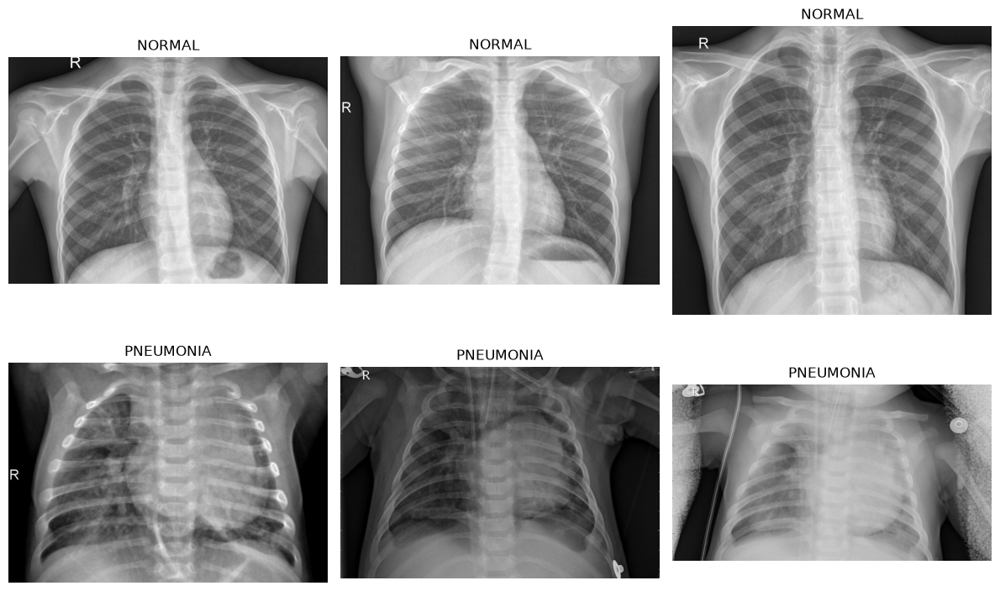

In [57]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i in range(3):
    img = Image.open(test_normal[i])
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title("NORMAL")
    axes[0, i].axis("off")

for i in range(3):
    img = Image.open(test_pneumonia[i])
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].set_title("PNEUMONIA")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


In [58]:
model.eval()

wrong_normal = []

with torch.no_grad():

    for images, batch_labels in test_loader:

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        for i in range(len(batch_labels)):

            actual = batch_labels[i].item()
            probability = probabilities[i].item()
            prediction = 1 if probability >= 0.5 else 0

            if actual == 0 and prediction == 1:
                wrong_normal.append(probability)

print("Wrong NORMAL predictions:", len(wrong_normal))
print("First 20 probabilities:")
print(wrong_normal[:20])

print("\nAverage probability:")
print(sum(wrong_normal) / len(wrong_normal))

print("\nMinimum probability:")
print(min(wrong_normal))

print("\nMaximum probability:")
print(max(wrong_normal))

Wrong NORMAL predictions: 166
First 20 probabilities:
[0.5137261152267456, 0.987326443195343, 0.9847095608711243, 0.9901199340820312, 0.9200338125228882, 0.9938628673553467, 0.9867115020751953, 0.9898803234100342, 0.9150221347808838, 0.9995916485786438, 0.9526613354682922, 0.7574127912521362, 0.9980738162994385, 0.9632224440574646, 0.9864292144775391, 0.8750330805778503, 0.9082427620887756, 0.9982563853263855, 0.968675971031189, 0.8741245865821838]

Average probability:
0.9068493904119515

Minimum probability:
0.5137261152267456

Maximum probability:
0.999996542930603


In [59]:
import numpy as np
from PIL import Image

def get_image_stats(paths, n=200):
    means = []
    stds = []

    for path in paths[:n]:
        img = Image.open(path).convert("L")
        arr = np.array(img)

        means.append(arr.mean())
        stds.append(arr.std())

    return np.mean(means), np.mean(stds)


train_normal_mean, train_normal_std = get_image_stats(normal_images)

test_normal_mean, test_normal_std = get_image_stats(test_normal)

print("TRAIN NORMAL")
print("Average pixel mean:", train_normal_mean)
print("Average pixel std:", train_normal_std)

print("\nTEST NORMAL")
print("Average pixel mean:", test_normal_mean)
print("Average pixel std:", test_normal_std)

TRAIN NORMAL
Average pixel mean: 120.0786554334868
Average pixel std: 61.67704804053568

TEST NORMAL
Average pixel mean: 125.50197301342176
Average pixel std: 60.31066969872873


In [60]:
test_pneumonia_mean, test_pneumonia_std = get_image_stats(test_pneumonia)

train_pneumonia_mean, train_pneumonia_std = get_image_stats(pneumonia_images)

print("TRAIN PNEUMONIA")
print("Average pixel mean:", train_pneumonia_mean)
print("Average pixel std:", train_pneumonia_std)

print("\nTEST PNEUMONIA")
print("Average pixel mean:", test_pneumonia_mean)
print("Average pixel std:", test_pneumonia_std)

TRAIN PNEUMONIA
Average pixel mean: 123.83559626354315
Average pixel std: 57.104209908259655

TEST PNEUMONIA
Average pixel mean: 117.9001736537859
Average pixel std: 54.16817058788505


In [61]:
from collections import Counter
from PIL import Image

def get_dimensions(paths, n=None):
    dimensions = []

    selected_paths = paths if n is None else paths[:n]

    for path in selected_paths:
        with Image.open(path) as img:
            dimensions.append(img.size)

    return dimensions


train_normal_dims = get_dimensions(normal_images)
test_normal_dims = get_dimensions(test_normal)

train_pneumonia_dims = get_dimensions(pneumonia_images)
test_pneumonia_dims = get_dimensions(test_pneumonia)

print("Train NORMAL examples:")
print(Counter(train_normal_dims).most_common(5))

print("\nTest NORMAL examples:")
print(Counter(test_normal_dims).most_common(5))

print("\nTrain PNEUMONIA examples:")
print(Counter(train_pneumonia_dims).most_common(5))

print("\nTest PNEUMONIA examples:")
print(Counter(test_pneumonia_dims).most_common(5))

Train NORMAL examples:
[((1472, 1171), 2), ((1480, 1228), 2), ((1364, 1148), 2), ((1616, 1318), 2), ((1284, 1013), 2)]

Test NORMAL examples:
[((2517, 1979), 2), ((1304, 952), 2), ((1168, 824), 2), ((1857, 1317), 1), ((2111, 1509), 1)]

Train PNEUMONIA examples:
[((1072, 648), 7), ((1080, 728), 6), ((1008, 680), 5), ((976, 672), 5), ((1216, 872), 5)]

Test PNEUMONIA examples:
[((1112, 736), 3), ((952, 624), 2), ((952, 640), 2), ((1088, 576), 2), ((1112, 600), 2)]


In [62]:
def get_aspect_ratios(paths):
    ratios = []

    for path in paths:
        with Image.open(path) as img:
            width, height = img.size
            ratios.append(width / height)

    return ratios


train_normal_ratios = get_aspect_ratios(normal_images)
test_normal_ratios = get_aspect_ratios(test_normal)

train_pneumonia_ratios = get_aspect_ratios(pneumonia_images)
test_pneumonia_ratios = get_aspect_ratios(test_pneumonia)


print("TRAIN NORMAL")
print("Average:", sum(train_normal_ratios) / len(train_normal_ratios))
print("Min:", min(train_normal_ratios))
print("Max:", max(train_normal_ratios))

print("\nTEST NORMAL")
print("Average:", sum(test_normal_ratios) / len(test_normal_ratios))
print("Min:", min(test_normal_ratios))
print("Max:", max(test_normal_ratios))

print("\nTRAIN PNEUMONIA")
print("Average:", sum(train_pneumonia_ratios) / len(train_pneumonia_ratios))
print("Min:", min(train_pneumonia_ratios))
print("Max:", max(train_pneumonia_ratios))

print("\nTEST PNEUMONIA")
print("Average:", sum(test_pneumonia_ratios) / len(test_pneumonia_ratios))
print("Min:", min(test_pneumonia_ratios))
print("Max:", max(test_pneumonia_ratios))

TRAIN NORMAL
Average: 1.2277920511462639
Min: 0.8772204806687566
Max: 1.8079231692677071

TEST NORMAL
Average: 1.3680920437801325
Min: 0.9277552524880206
Max: 2.106969205834684

TRAIN PNEUMONIA
Average: 1.513755093072343
Min: 0.8353909465020576
Max: 3.378787878787879

TEST PNEUMONIA
Average: 1.527349057020796
Min: 1.0
Max: 2.5813953488372094


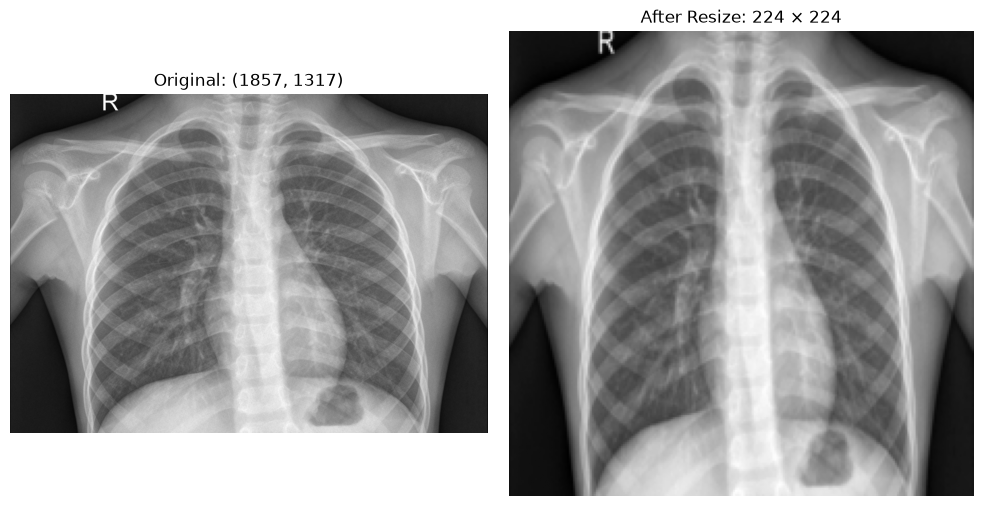

In [63]:
sample_path = test_normal[0]

original = Image.open(sample_path).convert("L")

resized = transform(original)

resized_image = resized.squeeze(0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original, cmap="gray")
axes[0].set_title(f"Original: {original.size}")
axes[0].axis("off")

axes[1].imshow(resized_image, cmap="gray")
axes[1].set_title("After Resize: 224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [64]:
from PIL import Image, ImageOps
from torchvision import transforms

class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=self.fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))

        return canvas

transform_padded = transforms.Compose([
    ResizeWithPadding(224),
    transforms.ToTensor()
])

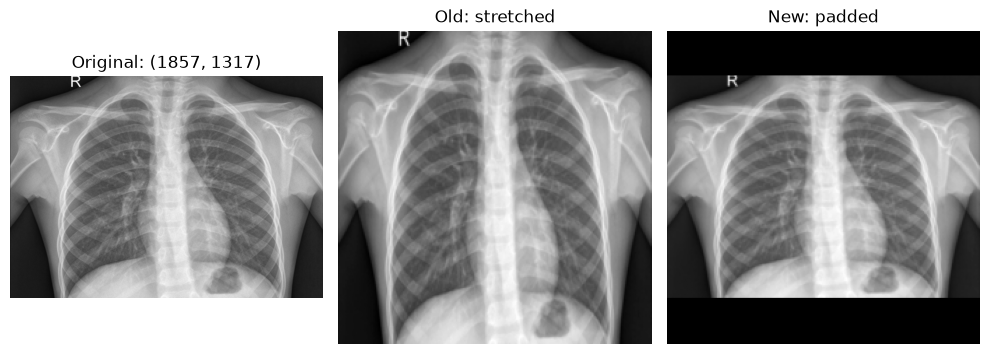

In [65]:
import matplotlib.pyplot as plt
from PIL import Image

# Use a NORMAL X-ray from the original test dataset
sample_path = test_paths[0]

# Load image in grayscale
img = Image.open(sample_path).convert("L")

# Apply old and new preprocessing
old_img = transforms.Resize((224, 224))(img)
new_img = transform_padded(img)

# Plot the comparison
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title(f"Original: {img.size}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(old_img, cmap="gray")
plt.title("Old: stretched")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(new_img.squeeze(), cmap="gray")
plt.title("New: padded")
plt.axis("off")

plt.tight_layout()
plt.show()

In [66]:
print("Transform defined:", "transform_padded" in globals())
print("Sample image loaded:", "img" in globals())
print("Original dataset class available:", "ChestXrayDataset" in globals())

Transform defined: True
Sample image loaded: True
Original dataset class available: True


In [67]:
from pathlib import Path
from PIL import Image, ImageOps
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

# Aspect-ratio-preserving resize with padding
class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = ImageOps.contain(
            img.convert("L"),
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=self.fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))

        return canvas

transform_padded = transforms.Compose([
    ResizeWithPadding(224),
    transforms.ToTensor()
])

print("New preprocessing transform restored!")

New preprocessing transform restored!


In [68]:
project_dir = Path.cwd()

normal_dirs = [
    p for p in project_dir.rglob("test/NORMAL")
    if p.is_dir()
]

if not normal_dirs:
    raise FileNotFoundError(
        "Test/NORMAL folder not found. "
        "Please check the notebook's working directory."
    )

normal_images = [
    p for p in normal_dirs[0].iterdir()
    if p.suffix.lower() in {".jpeg", ".jpg", ".png"}
]

if not normal_images:
    raise FileNotFoundError("No NORMAL images found.")

sample_path = normal_images[0]
img = Image.open(sample_path).convert("L")

print("Sample:", sample_path.name)
print("Original dimensions:", img.size)

Sample: IM-0001-0001.jpeg
Original dimensions: (1857, 1317)


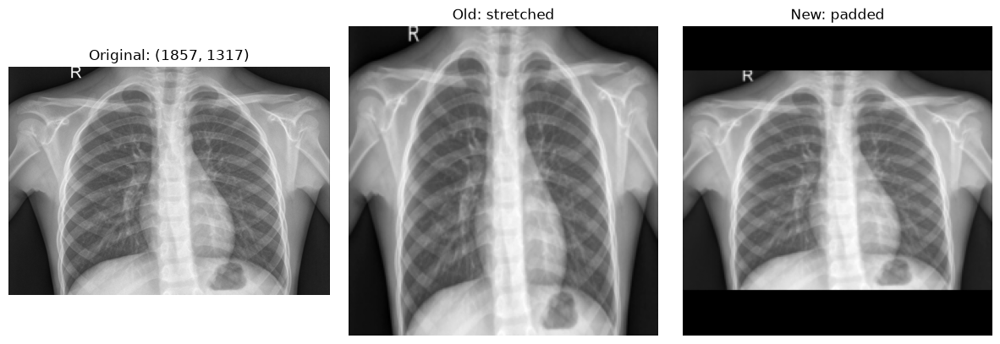

New tensor shape: torch.Size([1, 224, 224])


In [69]:
old_img = transforms.Resize((224, 224))(img)
new_img = transform_padded(img)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title(f"Original: {img.size}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(old_img, cmap="gray")
plt.title("Old: stretched")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(new_img.squeeze(), cmap="gray")
plt.title("New: padded")
plt.axis("off")

plt.tight_layout()
plt.show()

print("New tensor shape:", new_img.shape)

In [70]:
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torch

# Find the dataset's training directory
train_dirs = [
    p for p in project_dir.rglob("train")
    if p.is_dir()
    and (p / "NORMAL").is_dir()
    and (p / "PNEUMONIA").is_dir()
]

if not train_dirs:
    raise FileNotFoundError("Could not find the train dataset directory.")

train_dir = train_dirs[0]

# Collect training image paths and labels
image_paths = []
labels = []

for class_name, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    class_dir = train_dir / class_name

    for path in class_dir.iterdir():
        if path.suffix.lower() in {".jpeg", ".jpg", ".png"}:
            image_paths.append(path)
            labels.append(label)

print("Total training images:", len(image_paths))
print("NORMAL:", labels.count(0))
print("PNEUMONIA:", labels.count(1))

Total training images: 5216
NORMAL: 1341
PNEUMONIA: 3875


In [71]:
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

class ChestXrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("L")
        image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, label

padded_train_dataset = ChestXrayDataset(
    train_paths, train_labels, transform_padded
)

padded_val_dataset = ChestXrayDataset(
    val_paths, val_labels, transform_padded
)

padded_train_loader = DataLoader(
    padded_train_dataset, batch_size=32, shuffle=True
)

padded_val_loader = DataLoader(
    padded_val_dataset, batch_size=32, shuffle=False
)

print("Training images:", len(padded_train_dataset))
print("Validation images:", len(padded_val_dataset))

Training images: 4172
Validation images: 1044


In [72]:
images, labels = next(iter(padded_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Pixel range: 0.0 0.9960784316062927


In [73]:
print(ChestXrayCNN)

<class 'src.model.ChestXrayCNN'>


In [74]:
from pathlib import Path

print("Notebook working directory:", Path.cwd())

model_file = Path("src/model.py")

print("Model file exists:", model_file.exists())

if model_file.exists():
    print(model_file.read_text())

Notebook working directory: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai
Model file exists: True
import torch.nn as nn


class ChestXrayCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 56 * 56, 1)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


In [75]:
import sys
from pathlib import Path

project_dir = Path.cwd()

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.model import ChestXrayCNN

model = ChestXrayCNN()

print(model)

ChestXrayCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=1, bias=True)
  )
)


In [76]:
import torch

sample_batch, sample_labels = next(iter(padded_train_loader))

model.eval()

with torch.no_grad():
    output = model(sample_batch)

print("Input shape:", sample_batch.shape)
print("Output shape:", output.shape)
print("Labels shape:", sample_labels.shape)

Input shape: torch.Size([32, 1, 224, 224])
Output shape: torch.Size([32, 1])
Labels shape: torch.Size([32])


In [77]:
import torch
import torch.nn as nn
from torch.optim import Adam
from pathlib import Path

# Select GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Fresh model: do not load the old checkpoint
padded_model = ChestXrayCNN().to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = Adam(padded_model.parameters(), lr=0.001)

# Save this experiment separately
checkpoint_path = Path("models/best_chest_xray_cnn_padded.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

print("Model ready for training.")
print("Checkpoint:", checkpoint_path)

Device: cpu
Model ready for training.
Checkpoint: models\best_chest_xray_cnn_padded.pth


### 1.2 Training and Validation Split

Split the available dataset into training and validation subsets using stratified sampling to preserve the class distribution.

In [78]:
num_epochs = 5
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(num_epochs):
    # Training phase
    padded_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in padded_train_loader:
        images = images.to(device)
        labels = labels.to(device).view(-1, 1)

        optimizer.zero_grad()

        logits = padded_model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation phase
    padded_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in padded_val_loader:
            images = images.to(device)
            labels = labels.to(device).view(-1, 1)

            logits = padded_model(images)
            loss = criterion(logits, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(padded_model.state_dict(), checkpoint_path)
        print("Best padded model saved!")

Epoch 1/5 | Train Loss: 0.2979 | Train Acc: 0.8722 | Val Loss: 0.1561 | Val Acc: 0.9473
Best padded model saved!
Epoch 2/5 | Train Loss: 0.1386 | Train Acc: 0.9473 | Val Loss: 0.1110 | Val Acc: 0.9588
Best padded model saved!
Epoch 3/5 | Train Loss: 0.1031 | Train Acc: 0.9640 | Val Loss: 0.1143 | Val Acc: 0.9579
Epoch 4/5 | Train Loss: 0.0914 | Train Acc: 0.9645 | Val Loss: 0.1186 | Val Acc: 0.9550
Epoch 5/5 | Train Loss: 0.0798 | Train Acc: 0.9686 | Val Loss: 0.1000 | Val Acc: 0.9636
Best padded model saved!


In [79]:
from pathlib import Path
import torch
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from src.model import ChestXrayCNN
from torch.utils.data import DataLoader

# Find the original test folder
normal_dirs = [
    p for p in Path.cwd().rglob("test/NORMAL")
    if p.is_dir()
]

if not normal_dirs:
    raise FileNotFoundError("Could not find the original test/NORMAL folder.")

test_dir = normal_dirs[0].parent

# Collect test images and labels
test_paths = []
test_labels = []

for class_name, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    for path in sorted((test_dir / class_name).iterdir()):
        if path.suffix.lower() in {".jpeg", ".jpg", ".png"}:
            test_paths.append(path)
            test_labels.append(label)

# Use our new preprocessing transform
padded_test_dataset = ChestXrayDataset(
    test_paths, test_labels, transform_padded
)

padded_test_loader = DataLoader(
    padded_test_dataset,
    batch_size=32,
    shuffle=False
)

# Load the best saved padded model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

padded_model = ChestXrayCNN().to(device)
padded_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)
padded_model.eval()

# Evaluate
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in padded_test_loader:
        images = images.to(device)

        logits = padded_model(images)
        predictions = (torch.sigmoid(logits) >= 0.5).int().cpu().view(-1)

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.int().tolist())

print("Test images:", len(all_labels))
print("Test accuracy:", round(
    accuracy_score(all_labels, all_predictions), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

Test images: 624
Test accuracy: 0.7788

Confusion matrix:
[[100 134]
 [  4 386]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9615    0.4274    0.5917       234
   PNEUMONIA     0.7423    0.9897    0.8484       390

    accuracy                         0.7788       624
   macro avg     0.8519    0.7085    0.7200       624
weighted avg     0.8245    0.7788    0.7521       624



In [80]:
# Show the model's prediction probabilities
# for the test images.

import torch
import pandas as pd

padded_model.eval()
results = []

with torch.no_grad():
    for images, labels in padded_test_loader:
        images = images.to(device)

        logits = padded_model(images)
        probabilities = torch.sigmoid(logits).cpu().view(-1)

        for label, probability in zip(labels, probabilities):
            actual = int(label.item())
            prob = float(probability.item())
            predicted = int(prob >= 0.5)

            results.append({
                "actual": actual,
                "predicted": predicted,
                "pneumonia_probability": prob
            })

results_df = pd.DataFrame(results)

# Keep only normal images incorrectly predicted as pneumonia.
wrong_normal = results_df[
    (results_df["actual"] == 0) &
    (results_df["predicted"] == 1)
]

print("Incorrect normal predictions:", len(wrong_normal))
print(
    "Average pneumonia probability:",
    round(wrong_normal["pneumonia_probability"].mean(), 4)
)
print(
    wrong_normal["pneumonia_probability"].describe()
)

Incorrect normal predictions: 134
Average pneumonia probability: 0.8201
count    134.000000
mean       0.820064
std        0.154299
min        0.508021
25%        0.686597
50%        0.866801
75%        0.960715
max        0.999265
Name: pneumonia_probability, dtype: float64


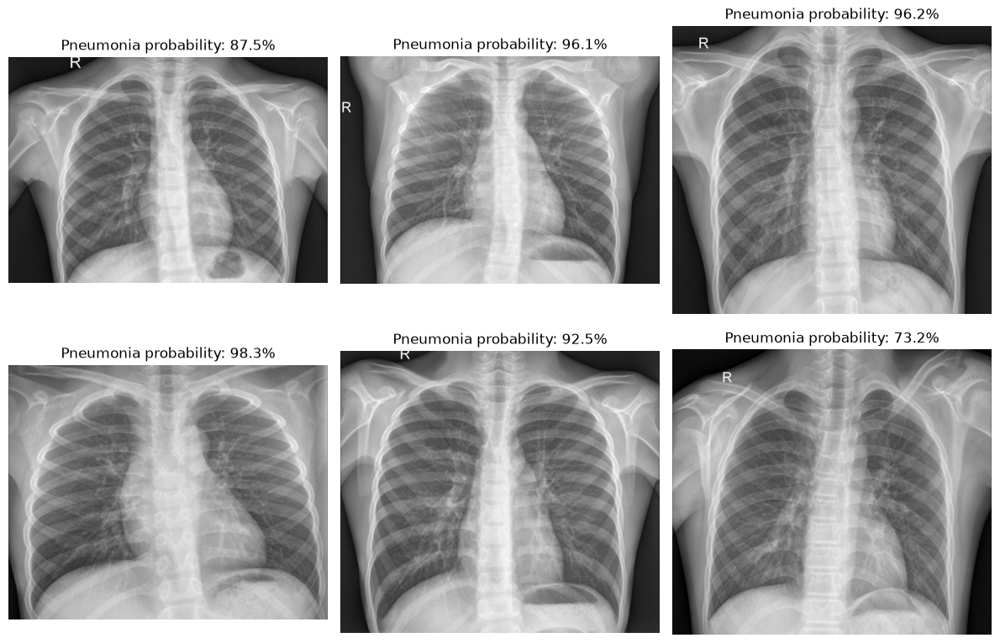

In [81]:

import matplotlib.pyplot as plt
from PIL import Image

# Select 6 normal images the model incorrectly flagged.
samples = wrong_normal.head(6)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = test_paths[
        results_df.index.get_loc(row.name)
    ]

    image = Image.open(image_path).convert("L")

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Pneumonia probability: "
        f"{row['pneumonia_probability']:.1%}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [82]:

# Select the first normal image that was
# incorrectly predicted as pneumonia.

sample_index = int(wrong_normal.index[0])
image_path = test_paths[sample_index]

print("Image:", image_path)
print("Actual class: NORMAL")
print(
    "Predicted pneumonia probability:",
    round(
        wrong_normal.iloc[0]["pneumonia_probability"],
        4
    )
)


Image: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\test\NORMAL\IM-0001-0001.jpeg
Actual class: NORMAL
Predicted pneumonia probability: 0.875


In [83]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load the selected image and apply the SAME
# preprocessing used to train the padded model.
original_image = Image.open(image_path).convert("L")
input_tensor = transform_padded(original_image)
input_tensor = input_tensor.unsqueeze(0).to(device)

# Store the information Grad-CAM needs.
saved = {}

def save_features(module, inputs, output):
    saved["features"] = output
    output.register_hook(
        lambda grad: saved.update({"gradients": grad})
    )

# Watch the second convolutional layer.
layer = padded_model.features[3]
handle = layer.register_forward_hook(save_features)

# Make a prediction.
padded_model.eval()
padded_model.zero_grad()

logit = padded_model(input_tensor)

# Our model's output represents the pneumonia score.
score = logit[0, 0]

# Calculate gradients of that score.
score.backward()

# Remove the hook after collecting the information.
handle.remove()

print("Logit:", round(score.item(), 4))
print("Feature maps:", saved["features"].shape)
print("Gradients:", saved["gradients"].shape)


Logit: 1.9461
Feature maps: torch.Size([1, 32, 112, 112])
Gradients: torch.Size([1, 32, 112, 112])


In [84]:

# Get saved feature maps and gradients.
features = saved["features"]
gradients = saved["gradients"]

# Give each feature map an importance weight.
weights = gradients.mean(
    dim=(2, 3),
    keepdim=True
)

# Combine the feature maps using their weights.
cam = (weights * features).sum(dim=1, keepdim=True)

# Keep positive contributions to the pneumonia score.
cam = torch.relu(cam)

# Resize the heatmap to match the input image.
cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Convert it into values between 0 and 1.
cam = cam[0, 0].detach().cpu()
cam = cam / (cam.max() + 1e-8)

heatmap = cam.numpy()

print("Heatmap shape:", heatmap.shape)
print("Minimum:", heatmap.min())
print("Maximum:", heatmap.max())


Heatmap shape: (224, 224)
Minimum: 0.0
Maximum: 0.9999762


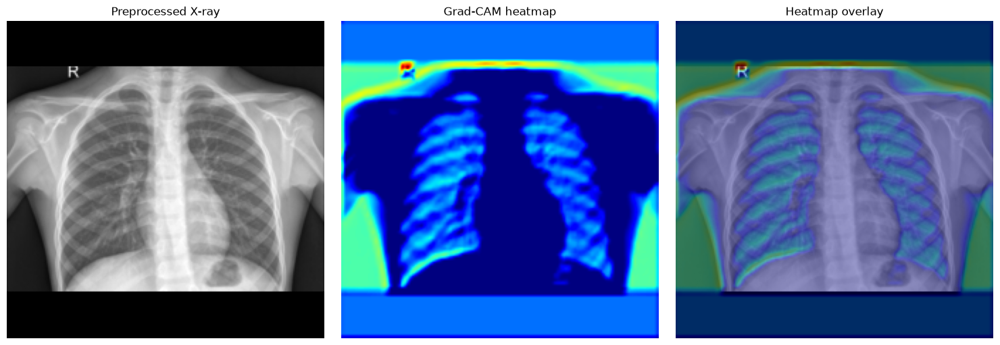

In [85]:

# Convert the preprocessed X-ray to a displayable image.
xray = input_tensor[0, 0].detach().cpu().numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(xray, cmap="gray")
plt.title("Preprocessed X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(xray, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Heatmap overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


In [86]:

# Grad-CAM activation in the padded top and bottom bands

band_size = 30

top_activation = heatmap[:band_size, :].mean()
bottom_activation = heatmap[-band_size:, :].mean()
middle_activation = heatmap[band_size:-band_size, :].mean()

print("Top band activation:", round(float(top_activation), 4))
print("Bottom band activation:", round(float(bottom_activation), 4))
print("Middle region activation:", round(float(middle_activation), 4))


Top band activation: 0.2464
Bottom band activation: 0.2222
Middle region activation: 0.14


Original image size: (1857, 1317)
Preprocessed image size: torch.Size([1, 1, 224, 224])


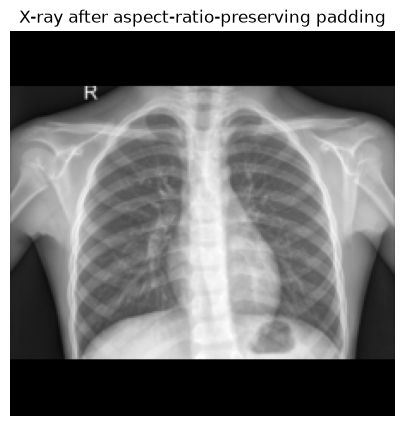

In [87]:
# Inspect the dimensions of the padded image.
print("Original image size:", original_image.size)
print("Preprocessed image size:", input_tensor.shape)

# Display the preprocessed image clearly.
plt.figure(figsize=(5, 5))
plt.imshow(input_tensor[0, 0].detach().cpu(), cmap="gray")
plt.title("X-ray after aspect-ratio-preserving padding")
plt.axis("off")
plt.show()

In [88]:

# Get the original image dimensions.
original_width, original_height = original_image.size

# Find the size after preserving the aspect ratio.
scale = min(224 / original_width, 224 / original_height)

resized_width = round(original_width * scale)
resized_height = round(original_height * scale)

# Calculate how much padding was added.
left = (224 - resized_width) // 2
top = (224 - resized_height) // 2

right = left + resized_width
bottom = top + resized_height

print("Original image size:", original_image.size)
print("Resized image size:", (resized_width, resized_height))
print("Padding boundaries:")
print("Left:", left, "| Top:", top)
print("Right:", right, "| Bottom:", bottom)


Original image size: (1857, 1317)
Resized image size: (224, 159)
Padding boundaries:
Left: 0 | Top: 32
Right: 224 | Bottom: 191


In [89]:

# Grad-CAM activation inside the original image area.
image_area = heatmap[top:bottom, left:right]

# Grad-CAM activation outside that area (the padding).
padding_mask = np.ones((224, 224), dtype=bool)
padding_mask[top:bottom, left:right] = False

padding_area = heatmap[padding_mask]

print(
    "Original image area activation:",
    round(float(image_area.mean()), 4)
)
print(
    "Padding area activation:",
    round(float(padding_area.mean()), 4)
)


Original image area activation: 0.1367
Padding area activation: 0.235


In [90]:

# Copy the already-preprocessed image.
modified_tensor = input_tensor.clone()

# Replace padding pixels with the average intensity
# of the original image area.
image_pixels = modified_tensor[
    0, 0, top:bottom, left:right
]
gray_value = image_pixels.mean()

# Change only the padding area.
padding_tensor = torch.ones(
    (224, 224), dtype=torch.bool, device=device
)
padding_tensor[top:bottom, left:right] = False

modified_tensor[0, 0][padding_tensor] = gray_value

# Compare the original and modified predictions.
padded_model.eval()

with torch.no_grad():
    original_logit = padded_model(input_tensor)
    modified_logit = padded_model(modified_tensor)

    original_prob = torch.sigmoid(original_logit).item()
    modified_prob = torch.sigmoid(modified_logit).item()

print("Original pneumonia probability:",
      round(original_prob, 4))
print("Modified pneumonia probability:",
      round(modified_prob, 4))
print("Change in probability:",
      round(modified_prob - original_prob, 4))


Original pneumonia probability: 0.875
Modified pneumonia probability: 0.7348
Change in probability: -0.1402


In [91]:

import torch
import pandas as pd

padded_model.eval()
comparison = []

# Examine 20 incorrectly classified normal images.
for idx in wrong_normal.index[:20]:
    image_path = test_paths[idx]

    image = Image.open(image_path).convert("L")
    tensor = transform_padded(image).unsqueeze(0).to(device)

    # Calculate the image's padding boundaries.
    w, h = image.size
    scale = min(224 / w, 224 / h)
    rw, rh = round(w * scale), round(h * scale)

    left = (224 - rw) // 2
    top = (224 - rh) // 2
    right, bottom = left + rw, top + rh

    modified = tensor.clone()

    # Replace padding with the mean intensity
    # of the resized image area.
    mean_intensity = tensor[
        0, 0, top:bottom, left:right
    ].mean()

    mask = torch.ones(
        (224, 224), dtype=torch.bool, device=device
    )
    mask[top:bottom, left:right] = False
    modified[0, 0][mask] = mean_intensity

    with torch.no_grad():
        p_original = torch.sigmoid(
            padded_model(tensor)
        ).item()
        p_modified = torch.sigmoid(
            padded_model(modified)
        ).item()

    comparison.append({
        "original_probability": p_original,
        "modified_probability": p_modified,
        "change": p_modified - p_original
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))
print("\nAverage probability change:",
      round(comparison_df["change"].mean(), 4))
print("Images with lower probability after modification:",
      int((comparison_df["change"] < 0).sum()),
      "out of", len(comparison_df))


 original_probability  modified_probability  change
               0.8750                0.7348 -0.1402
               0.9610                0.7192 -0.2417
               0.9625                0.9529 -0.0096
               0.9833                0.9606 -0.0227
               0.9246                0.8581 -0.0665
               0.7320                0.7156 -0.0164
               0.8795                0.8770 -0.0025
               0.7471                0.7898  0.0427
               0.5218                0.3936 -0.1282
               0.9929                0.9732 -0.0197
               0.8101                0.8358  0.0256
               0.9599                0.9657  0.0058
               0.7329                0.2563 -0.4767
               0.9954                0.9329 -0.0625
               0.8738                0.7507 -0.1231
               0.7807                0.8875  0.1068
               0.8811                0.8392 -0.0419
               0.6640                0.6216 -0.0424
            

In [92]:
canvas = Image.new("L", (224, 224), color=0)

In [93]:
import random
from PIL import Image, ImageOps

class RandomPaddingResize:
    def __init__(self, size=224, min_fill=0, max_fill=80):
        self.size = size
        self.min_fill = min_fill
        self.max_fill = max_fill

    def __call__(self, img):
        # Convert the X-ray to grayscale
        img = img.convert("L")

        # Resize while preserving the original aspect ratio
        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        # Choose a random grayscale value for the padding
        fill = random.randint(self.min_fill, self.max_fill)

        # Create the square background
        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=fill
        )

        # Center the unchanged X-ray on the background
        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))

        return canvas

In [94]:
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from src.model import ChestXrayCNN

print("Imports loaded successfully!")

Imports loaded successfully!


In [95]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
print("Current folder:", PROJECT_DIR)
print("Model file exists:", (PROJECT_DIR / "src" / "model.py").exists())
print("Padded checkpoint exists:",
      (PROJECT_DIR / "models" / "best_chest_xray_cnn_padded.pth").exists())

Current folder: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai
Model file exists: True
Padded checkpoint exists: True


In [96]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

padded_model = ChestXrayCNN().to(device)

checkpoint = torch.load(
    PROJECT_DIR / "models" / "best_chest_xray_cnn_padded.pth",
    map_location=device,
    weights_only=True
)

padded_model.load_state_dict(checkpoint)
padded_model.eval()

print("Padded model restored successfully!")
print("Device:", device)

Padded model restored successfully!
Device: cpu


In [97]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

for path in PROJECT_DIR.rglob("*"):
    if path.is_dir() and path.name.lower() in ["train", "test", "val"]:
        print(path)

C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\test
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\train
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\val
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray\test
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray\train
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray\val
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\__MACOSX\chest_xray\test
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\__MACOSX\chest_xray\train
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\__MACOSX\chest_xray\val
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\venv\Lib\site-packages\joblib\test
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\venv\Lib\site-packages\tornado\test
C:\Users\ANUBHAV 

In [98]:
from pathlib import Path
from sklearn.model_selection import train_test_split

# Use the main dataset directory
DATA_DIR = PROJECT_DIR / "data" / "raw" / "chest_xray"

TRAIN_DIR = DATA_DIR / "train"

# Collect image paths and labels
image_paths = []
labels = []

class_names = {
    "NORMAL": 0,
    "PNEUMONIA": 1
}

for class_name, label in class_names.items():
    class_dir = TRAIN_DIR / class_name

    for image_path in class_dir.glob("*"):
        if image_path.suffix.lower() in [".jpeg", ".jpg", ".png"]:
            image_paths.append(image_path)
            labels.append(label)

# Create the same reproducible 80/20 split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Total images:", len(image_paths))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Training NORMAL:", train_labels.count(0))
print("Training PNEUMONIA:", train_labels.count(1))
print("Validation NORMAL:", val_labels.count(0))
print("Validation PNEUMONIA:", val_labels.count(1))

Total images: 5216
Training images: 4172
Validation images: 1044
Training NORMAL: 1073
Training PNEUMONIA: 3099
Validation NORMAL: 268
Validation PNEUMONIA: 776


## 2. Image Preprocessing and Padding

This section prepares chest X-ray images for CNN input by resizing them to a consistent resolution while preserving their original aspect ratio.

It also explores padding strategies and their potential influence on model predictions.

In [99]:
from PIL import Image, ImageOps

class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = img.convert("L")

        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=self.fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2

        canvas.paste(img, (left, top))

        return canvas

print("ResizeWithPadding is ready!")

ResizeWithPadding is ready!


In [100]:
import random
from PIL import Image, ImageOps
from torchvision import transforms

class RandomPaddingResize:
    def __init__(self, size=224, min_fill=0, max_fill=80):
        self.size = size
        self.min_fill = min_fill
        self.max_fill = max_fill

    def __call__(self, img):
        img = img.convert("L")

        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        fill = random.randint(self.min_fill, self.max_fill)

        canvas = Image.new(
            "L", (self.size, self.size), color=fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))

        return canvas


# Random padding for training
train_transform = transforms.Compose([
    RandomPaddingResize(size=224, min_fill=0, max_fill=80),
    transforms.ToTensor()
])

# Fixed black padding for validation
val_transform = transforms.Compose([
    ResizeWithPadding(size=224, fill=0),
    transforms.ToTensor()
])

print("Training and validation transforms created!")

Training and validation transforms created!


In [101]:
from torch.utils.data import Dataset, DataLoader
import torch

class ChestXrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("L")
        image = self.transform(image)

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.float32
        )

        return image, label


train_dataset = ChestXrayDataset(
    train_paths, train_labels, train_transform
)

val_dataset = ChestXrayDataset(
    val_paths, val_labels, val_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 131
Validation batches: 33


In [102]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Create a fresh CNN
random_padding_model = ChestXrayCNN().to(device)

# Loss function for binary classification
criterion = nn.BCEWithLogitsLoss()

# Optimizer updates the model's weights during training
optimizer = optim.Adam(
    random_padding_model.parameters(),
    lr=0.001
)

# Save the best model based on validation loss
best_val_loss = float("inf")
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODEL_DIR / "best_chest_xray_cnn_random_padding.pth"

print("Model created successfully!")
print("Checkpoint path:", checkpoint_path)

Using device: cpu


In [ ]:

num_epochs = 5

for epoch in range(num_epochs):
    # ----- TRAINING -----
    random_padding_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).view(-1, 1)

        # Clear gradients left over from the previous batch
        optimizer.zero_grad()

        # Make predictions
        logits = random_padding_model(images)

        # Calculate prediction error
        loss = criterion(logits, labels)

        # Calculate gradients and update model weights
        loss.backward()
        optimizer.step()

        # Accumulate loss and accuracy statistics
        batch_size = images.size(0)
        train_loss += loss.item() * batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # ----- VALIDATION -----
    random_padding_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).view(-1, 1)

            logits = random_padding_model(images)
            loss = criterion(logits, labels)

            batch_size = images.size(0)
            val_loss += loss.item() * batch_size

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # Save only when validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            random_padding_model.state_dict(),
            checkpoint_path
        )

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

print("\nTraining complete!")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best checkpoint saved at: {checkpoint_path}")


In [11]:

# Load the best checkpoint saved during training
random_padding_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

random_padding_model = random_padding_model.to(device)
random_padding_model.eval()

print("Best random-padding model loaded successfully!")


Best random-padding model loaded successfully!


In [106]:

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from PIL import Image
import torch

# Official test folder
TEST_DIR = DATA_DIR / "test"

# Collect test image paths and labels
test_paths = []
test_labels = []

class_names = {
    "NORMAL": 0,
    "PNEUMONIA": 1
}

for class_name, label in class_names.items():
    class_dir = TEST_DIR / class_name

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() in [".jpeg", ".jpg", ".png"]:
            test_paths.append(image_path)
            test_labels.append(label)

print("Total test images:", len(test_paths))
print("NORMAL:", test_labels.count(0))
print("PNEUMONIA:", test_labels.count(1))


Total test images: 624
NORMAL: 234
PNEUMONIA: 390


In [107]:

# Fixed padding makes test preprocessing reproducible
test_transform = transforms.Compose([
    ResizeWithPadding(size=224, fill=0),
    transforms.ToTensor()
])

test_dataset = ChestXrayDataset(
    test_paths,
    test_labels,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Verify the first batch
images, labels = next(iter(test_loader))

print("Test image batch shape:", images.shape)
print("Test label batch shape:", labels.shape)


Test image batch shape: torch.Size([32, 1, 224, 224])
Test label batch shape: torch.Size([32])


In [108]:

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import numpy as np

random_padding_model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        # Get raw model outputs
        logits = random_padding_model(images)

        # Convert logits into pneumonia probabilities
        probabilities = torch.sigmoid(logits).squeeze(1)

        # Probability >= 0.5 means PNEUMONIA (class 1)
        predictions = (probabilities >= 0.5).long()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Calculate evaluation metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
cm = confusion_matrix(all_labels, all_predictions)
report = classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4,
    zero_division=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)


Test Accuracy: 0.7692

Confusion Matrix:
[[ 95 139]
 [  5 385]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9500    0.4060    0.5689       234
   PNEUMONIA     0.7347    0.9872    0.8425       390

    accuracy                         0.7692       624
   macro avg     0.8424    0.6966    0.7057       624
weighted avg     0.8155    0.7692    0.7399       624



False positives: 139


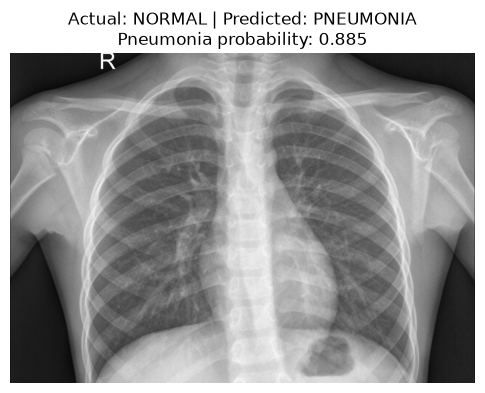

Image path: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\test\NORMAL\IM-0001-0001.jpeg


In [109]:

# Find NORMAL images incorrectly predicted as PNEUMONIA
false_positive_indices = [
    i for i, (true_label, pred_label) in enumerate(
        zip(all_labels, all_predictions)
    )
    if true_label == 0 and pred_label == 1
]

print("False positives:", len(false_positive_indices))

# Select the first false positive
idx = false_positive_indices[0]

# Load the original X-ray
image_path = test_paths[idx]
original_image = Image.open(image_path).convert("L")

# Probability assigned to PNEUMONIA
probability = all_probabilities[idx]

plt.figure(figsize=(6, 6))
plt.imshow(original_image, cmap="gray")
plt.title(
    f"Actual: NORMAL | Predicted: PNEUMONIA\n"
    f"Pneumonia probability: {probability:.3f}"
)
plt.axis("off")
plt.show()

print("Image path:", image_path)


In [110]:

# Prepare the selected false-positive image
idx = false_positive_indices[0]

image_path = test_paths[idx]
original_image = Image.open(image_path).convert("L")

input_tensor = test_transform(original_image).unsqueeze(0).to(device)

# Confirm the model input shape
print("Input shape:", input_tensor.shape)

# Check the prediction again
random_padding_model.eval()

with torch.no_grad():
    logit = random_padding_model(input_tensor)
    probability = torch.sigmoid(logit).item()

print(f"Pneumonia probability: {probability:.4f}")


Input shape: torch.Size([1, 1, 224, 224])
Pneumonia probability: 0.8850


In [111]:

# Save feature maps and their gradients
saved = {}

def save_features(module, inputs, output):
    saved["features"] = output
    output.register_hook(
        lambda grad: saved.update({"gradients": grad})
    )

layer = random_padding_model.features[3]

handle = layer.register_forward_hook(save_features)

random_padding_model.zero_grad()

# Forward pass
logit = random_padding_model(input_tensor)

# Explain the pneumonia score
score = logit[0, 0]
score.backward()

# Remove the hook after collecting the information
handle.remove()

print("Feature map shape:", saved["features"].shape)
print("Gradient shape:", saved["gradients"].shape)


Feature map shape: torch.Size([1, 32, 112, 112])
Gradient shape: torch.Size([1, 32, 112, 112])


In [112]:

# Get saved feature maps and gradients
features = saved["features"]
gradients = saved["gradients"]

# Give more weight to features with stronger average gradients
weights = gradients.mean(dim=(2, 3), keepdim=True)

# Combine the 32 feature maps into one heatmap
cam = (weights * features).sum(dim=1, keepdim=True)

# Keep positive contributions to the selected score
cam = torch.relu(cam)

# Resize the heatmap to the input image dimensions
cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Convert to a NumPy array and normalize it
heatmap = cam[0, 0].detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())


Heatmap shape: (224, 224)
Heatmap range: 0.0 to 0.99998075


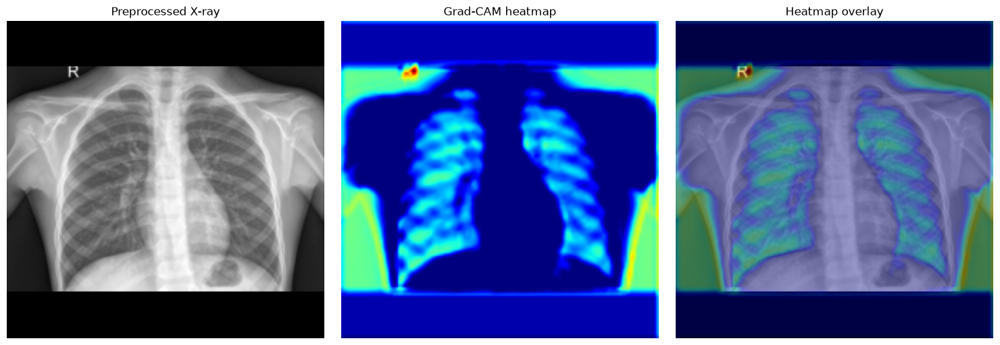

In [113]:

# Display the X-ray, Grad-CAM heatmap, and overlay
original_array = test_transform(original_image).numpy().squeeze()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_array, cmap="gray")
plt.title("Preprocessed X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_array, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
plt.title("Heatmap overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


Original probability: 0.8850
Modified probability: 0.8118
Probability change: -0.0732


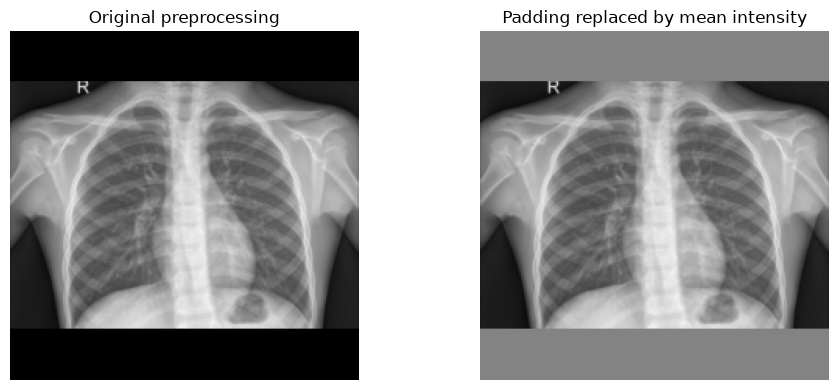

In [114]:

import numpy as np
import matplotlib.pyplot as plt
import torch

# Convert the preprocessed image to a NumPy array
image_array = test_transform(original_image).numpy().squeeze()

# Find the image area: pixels above zero are not black padding
image_area = image_array > 0

# Estimate the mean intensity of the image area
mean_intensity = image_array[image_area].mean()

# Copy the image so the original remains unchanged
modified_array = image_array.copy()

# Replace black padding with the image area's mean intensity
modified_array[~image_area] = mean_intensity

# Convert both images to model inputs
original_tensor = torch.tensor(
    image_array, dtype=torch.float32
).unsqueeze(0).unsqueeze(0).to(device)

modified_tensor = torch.tensor(
    modified_array, dtype=torch.float32
).unsqueeze(0).unsqueeze(0).to(device)

# Compare pneumonia probabilities
random_padding_model.eval()

with torch.no_grad():
    original_prob = torch.sigmoid(
        random_padding_model(original_tensor)
    ).item()

    modified_prob = torch.sigmoid(
        random_padding_model(modified_tensor)
    ).item()

print(f"Original probability: {original_prob:.4f}")
print(f"Modified probability: {modified_prob:.4f}")
print(f"Probability change: {modified_prob - original_prob:+.4f}")

# Visualize the intervention
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray", vmin=0, vmax=1)
plt.title("Original preprocessing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(modified_array, cmap="gray", vmin=0, vmax=1)
plt.title("Padding replaced by mean intensity")
plt.axis("off")

plt.tight_layout()
plt.show()


In [115]:

results = []

random_padding_model.eval()

for idx in false_positive_indices[:20]:
    image_path = test_paths[idx]

    # Apply the same preprocessing used during testing
    img = Image.open(image_path).convert("L")
    image_array = test_transform(img).numpy().squeeze()

    # Preliminary mask for black padding
    image_area = image_array > 0
    mean_intensity = image_array[image_area].mean()

    modified_array = image_array.copy()
    modified_array[~image_area] = mean_intensity

    # Convert to tensors with batch and channel dimensions
    original_tensor = torch.tensor(
        image_array, dtype=torch.float32
    )[None, None].to(device)

    modified_tensor = torch.tensor(
        modified_array, dtype=torch.float32
    )[None, None].to(device)

    with torch.no_grad():
        original_prob = torch.sigmoid(
            random_padding_model(original_tensor)
        ).item()

        modified_prob = torch.sigmoid(
            random_padding_model(modified_tensor)
        ).item()

    results.append({
        "image": image_path.name,
        "original_probability": original_prob,
        "modified_probability": modified_prob,
        "change": modified_prob - original_prob
    })

changes = [row["change"] for row in results]

print("Images tested:", len(results))
print(f"Average original probability: {np.mean([r['original_probability'] for r in results]):.4f}")
print(f"Average modified probability: {np.mean([r['modified_probability'] for r in results]):.4f}")
print(f"Average probability change: {np.mean(changes):+.4f}")
print("Images with lower probability after modification:",
      sum(change < 0 for change in changes), "out of", len(changes))


Images tested: 20
Average original probability: 0.8795
Average modified probability: 0.7881
Average probability change: -0.0914
Images with lower probability after modification: 17 out of 20


Total padding pixels: 14560
Total image-content pixels: 35616


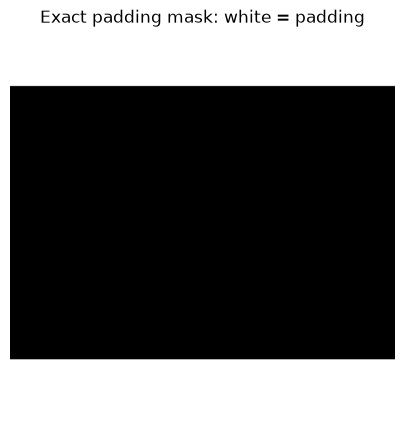

In [116]:

def get_padding_mask(original_img, size=224):
    # Calculate the resized image dimensions without stretching
    contained = ImageOps.contain(
        original_img.convert("L"),
        (size, size),
        method=Image.Resampling.BILINEAR
    )

    # Find where the resized image sits on the square canvas
    left = (size - contained.width) // 2
    top = (size - contained.height) // 2

    # True means actual padding; False means X-ray content
    padding_mask = np.ones((size, size), dtype=bool)

    padding_mask[
        top:top + contained.height,
        left:left + contained.width
    ] = False

    return padding_mask


# Check the mask on our selected false-positive image
padding_mask = get_padding_mask(original_image)

print("Total padding pixels:", padding_mask.sum())
print("Total image-content pixels:", (~padding_mask).sum())

plt.figure(figsize=(5, 5))
plt.imshow(padding_mask, cmap="gray")
plt.title("Exact padding mask: white = padding")
plt.axis("off")
plt.show()


In [117]:

exact_mask_results = []

random_padding_model.eval()

for idx in false_positive_indices[:20]:
    img = Image.open(test_paths[idx]).convert("L")

    # Apply the model's normal test preprocessing
    image_array = test_transform(img).numpy().squeeze()

    # Identify the true padding region from image dimensions
    padding_mask = get_padding_mask(img, size=224)

    # Calculate mean intensity using only actual X-ray content
    mean_intensity = image_array[~padding_mask].mean()

    # Change padding only; preserve the X-ray content
    modified_array = image_array.copy()
    modified_array[padding_mask] = mean_intensity

    original_tensor = torch.tensor(
        image_array, dtype=torch.float32
    )[None, None].to(device)

    modified_tensor = torch.tensor(
        modified_array, dtype=torch.float32
    )[None, None].to(device)

    with torch.no_grad():
        original_prob = torch.sigmoid(
            random_padding_model(original_tensor)
        ).item()

        modified_prob = torch.sigmoid(
            random_padding_model(modified_tensor)
        ).item()

    exact_mask_results.append({
        "image": test_paths[idx].name,
        "original_probability": original_prob,
        "modified_probability": modified_prob,
        "change": modified_prob - original_prob
    })

changes = [r["change"] for r in exact_mask_results]

print("Images tested:", len(exact_mask_results))
print(
    f"Average original probability: "
    f"{np.mean([r['original_probability'] for r in exact_mask_results]):.4f}"
)
print(
    f"Average modified probability: "
    f"{np.mean([r['modified_probability'] for r in exact_mask_results]):.4f}"
)
print(f"Average probability change: {np.mean(changes):+.4f}")
print(
    "Images with lower probability:",
    sum(change < 0 for change in changes),
    "out of",
    len(changes)
)


Images tested: 20
Average original probability: 0.8795
Average modified probability: 0.8107
Average probability change: -0.0687
Images with lower probability: 15 out of 20


In [118]:

import pandas as pd

experiment_summary = pd.DataFrame([
    {
        "Experiment": "Brightness-based mask",
        "Images tested": 20,
        "Mean original probability": 0.8795,
        "Mean modified probability": 0.7881,
        "Mean probability change": -0.0914,
        "Images decreased": "17/20"
    },
    {
        "Experiment": "Geometric padding mask",
        "Images tested": 20,
        "Mean original probability": 0.8795,
        "Mean modified probability": 0.8107,
        "Mean probability change": -0.0687,
        "Images decreased": "15/20"
    }
])

display(experiment_summary)

# Save the experimental record
experiment_summary.to_csv(
    PROJECT_DIR / "padding_sensitivity_results.csv",
    index=False
)

print("Saved padding_sensitivity_results.csv")


,Experiment,Images tested,Mean original probability,Mean modified probability,Mean probability change,Images decreased
0,Brightness-based mask,20,0.8795,0.7881,-0.0914,17/20
1,Geometric padding mask,20,0.8795,0.8107,-0.0687,15/20


Saved padding_sensitivity_results.csv


In [119]:

experiment_summary = pd.DataFrame([
    {
        "Experiment": "Brightness-based mask",
        "Images tested": 20,
        "Mean original probability": 0.8795,
        "Mean modified probability": 0.7881,
        "Mean probability change": -0.0914,
        "Images decreased": "17/20"
    },
    {
        "Experiment": "Geometric padding mask",
        "Images tested": 20,
        "Mean original probability": 0.8795,
        "Mean modified probability": 0.8107,
        "Mean probability change": -0.0687,
        "Images decreased": "15/20"
    }
])

display(experiment_summary)

experiment_summary.to_csv(
    PROJECT_DIR / "padding_sensitivity_results.csv",
    index=False
)

print("CSV corrected and saved!")


,Experiment,Images tested,Mean original probability,Mean modified probability,Mean probability change,Images decreased
0,Brightness-based mask,20,0.8795,0.7881,-0.0914,17/20
1,Geometric padding mask,20,0.8795,0.8107,-0.0687,15/20


CSV corrected and saved!


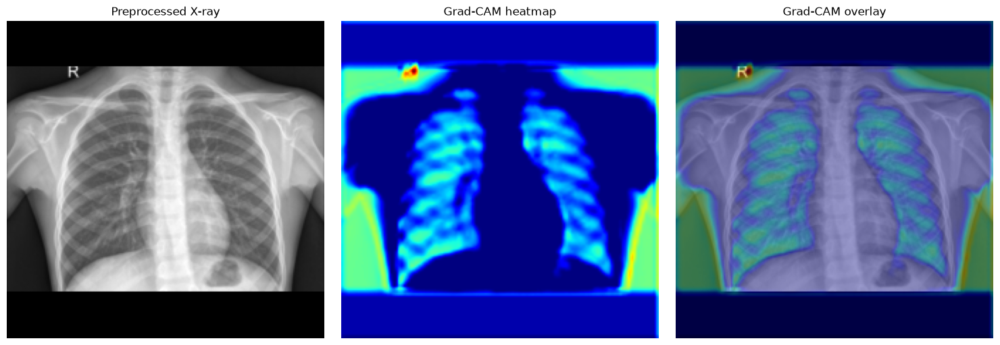

Grad-CAM figure saved to: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\figures\false_positive_gradcam.png


In [120]:

import matplotlib.pyplot as plt
import torch.nn.functional as F

# Calculate Grad-CAM from the captured feature maps and gradients
features = saved["features"]
gradients = saved["gradients"]

weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = torch.relu((weights * features).sum(dim=1, keepdim=True))

cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

heatmap = cam[0, 0].detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

# Prepare the preprocessed X-ray
image_array = test_transform(original_image).numpy().squeeze()

# Create the output folder
OUTPUT_DIR = PROJECT_DIR / "reports" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Plot the original, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_array, cmap="gray")
axes[0].set_title("Preprocessed X-ray")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM heatmap")

axes[2].imshow(image_array, cmap="gray")
axes[2].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
axes[2].set_title("Grad-CAM overlay")

for ax in axes:
    ax.axis("off")

fig.tight_layout()

figure_path = OUTPUT_DIR / "false_positive_gradcam.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Grad-CAM figure saved to:", figure_path)


In [121]:

exact_mask_df = pd.DataFrame(exact_mask_results)

results_path = PROJECT_DIR / "padding_sensitivity_per_image.csv"
exact_mask_df.to_csv(results_path, index=False)

print("Saved per-image results to:", results_path)
display(exact_mask_df.head())


Saved per-image results to: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\padding_sensitivity_per_image.csv


,image,original_probability,modified_probability,change
0,IM-0001-0001.jpeg,0.884961,0.811758,-0.073203
1,IM-0003-0001.jpeg,0.957143,0.571992,-0.385152
2,IM-0005-0001.jpeg,0.990608,0.988044,-0.002565
3,IM-0006-0001.jpeg,0.998437,0.993079,-0.005358
4,IM-0007-0001.jpeg,0.978273,0.967438,-0.010835


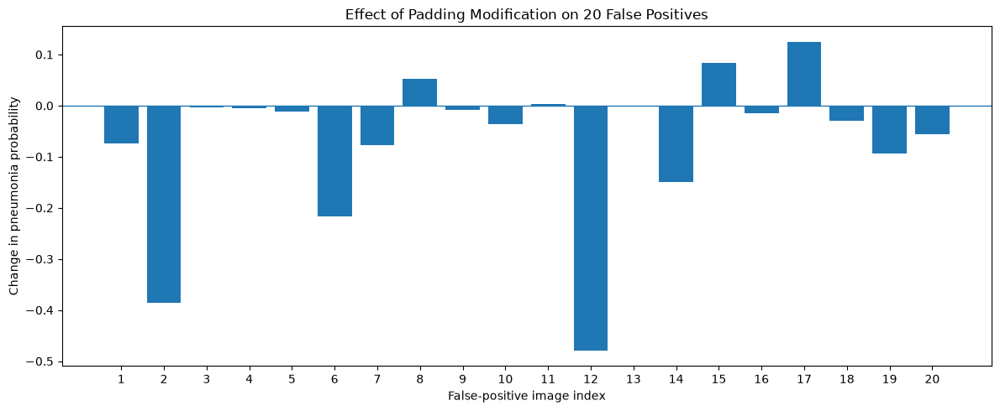

Chart saved to: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\figures\padding_sensitivity_changes.png
Images with lower probability: 15 out of 20


In [122]:

import matplotlib.pyplot as plt
import numpy as np

exact_mask_df = pd.DataFrame(exact_mask_results)

x = np.arange(len(exact_mask_df))

plt.figure(figsize=(12, 5))

plt.bar(
    x,
    exact_mask_df["change"],
)

plt.axhline(0, linewidth=1)
plt.xlabel("False-positive image index")
plt.ylabel("Change in pneumonia probability")
plt.title("Effect of Padding Modification on 20 False Positives")
plt.xticks(x, x + 1)
plt.tight_layout()

chart_path = OUTPUT_DIR / "padding_sensitivity_changes.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)
print(
    "Images with lower probability:",
    (exact_mask_df["change"] < 0).sum(),
    "out of",
    len(exact_mask_df)
)


In [123]:
print("Grad-CAM figure exists:", (OUTPUT_DIR / "false_positive_gradcam.png").exists())
print("Padding chart exists:", chart_path.exists())
print("Per-image CSV exists:", results_path.exists())

Grad-CAM figure exists: True
Padding chart exists: True
Per-image CSV exists: True


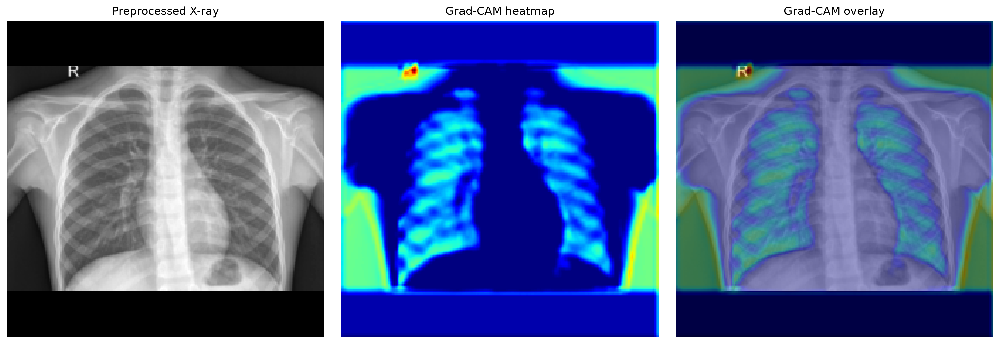

In [124]:
from IPython.display import Image, display

gradcam_path = OUTPUT_DIR / "false_positive_gradcam.png"

display(Image(filename=str(gradcam_path)))

In [125]:
import numpy as np
from PIL import Image

# Load the same image used for the Grad-CAM example
img = Image.open(
    test_paths[false_positive_indices[0]]
).convert("L")

# True = padding; False = actual image content
padding_mask = get_padding_mask(img, size=224)

# Make sure the heatmap and mask have matching dimensions
cam = np.asarray(heatmap, dtype=np.float32)

assert cam.shape == padding_mask.shape, (
    f"Heatmap shape {cam.shape} != mask shape {padding_mask.shape}"
)

# Calculate the fraction of total Grad-CAM activation in each region
total_activation = cam.sum() + 1e-8

padding_activation = cam[padding_mask].sum()
image_activation = cam[~padding_mask].sum()

padding_percent = 100 * padding_activation / total_activation
image_percent = 100 * image_activation / total_activation

print(f"Grad-CAM activation in padding: {padding_percent:.2f}%")
print(f"Grad-CAM activation in image:   {image_percent:.2f}%")
print(f"Total:                          {padding_percent + image_percent:.2f}%")

Grad-CAM activation in padding: 13.03%
Grad-CAM activation in image:   86.97%
Total:                          100.00%


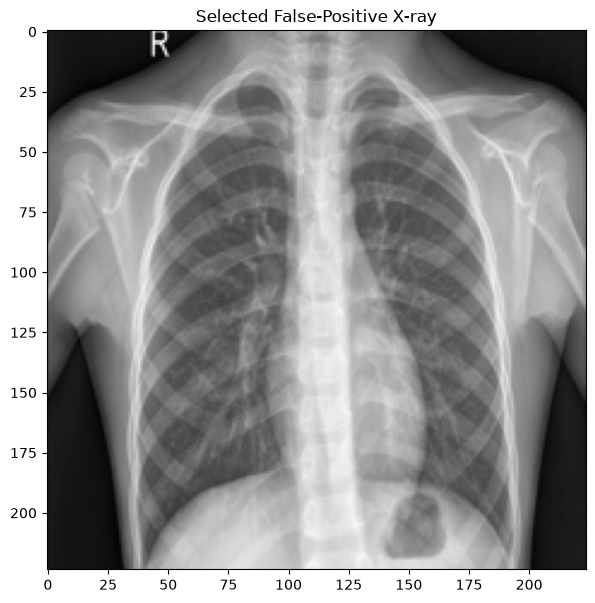

In [126]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load the same false-positive X-ray
img = Image.open(
    test_paths[false_positive_indices[0]]
).convert("L")

image_array = np.array(
    img.resize((224, 224))
)

plt.figure(figsize=(7, 7))
plt.imshow(image_array, cmap="gray")
plt.title("Selected False-Positive X-ray")
plt.axis("on")
plt.show()

Text(0.5, 1.0, 'Click around BOTH lung fields. Close each polygon by clicking its first point.')

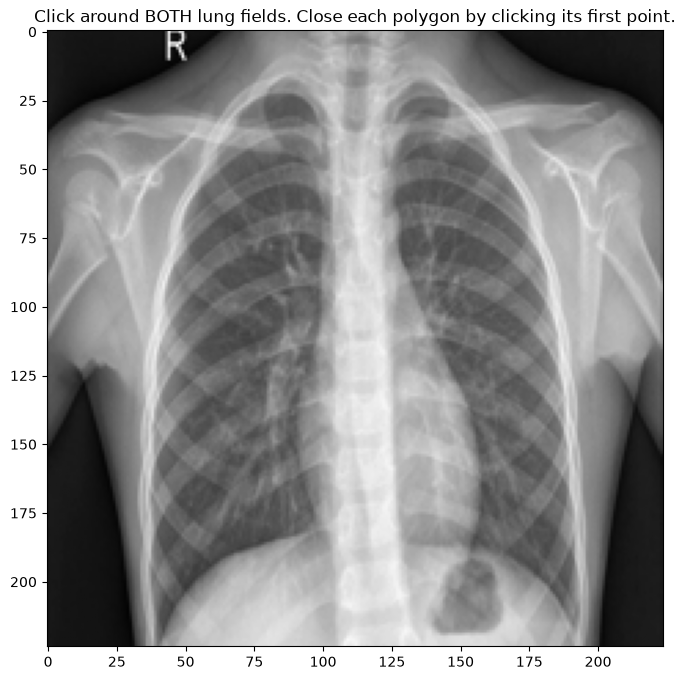

In [127]:
import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector
from matplotlib.path import Path

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image_array, cmap="gray")
ax.set_title(
    "Click around BOTH lung fields. Close each polygon by clicking its first point."
)

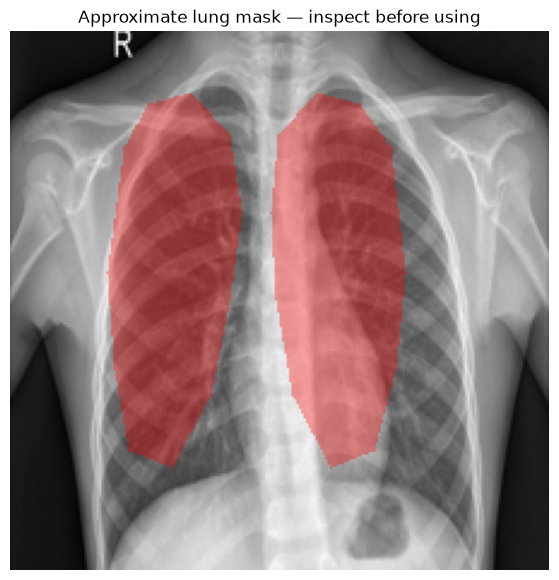

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path

# Approximate lung boundaries in (x, y) pixel coordinates.
# These are initial estimates; inspect the resulting mask carefully.
left_lung = np.array([
    [47, 48], [57, 30], [75, 25], [91, 43],
    [96, 75], [91, 111], [83, 151], [67, 181],
    [49, 174], [43, 140], [40, 100]
])

right_lung = np.array([
    [111, 43], [127, 25], [145, 30], [158, 48],
    [164, 100], [160, 140], [151, 174], [133, 181],
    [117, 151], [110, 111], [108, 75]
])

yy, xx = np.mgrid[0:224, 0:224]
points = np.column_stack([xx.ravel(), yy.ravel()])

lung_mask = (
    Path(left_lung).contains_points(points).reshape(224, 224)
    | Path(right_lung).contains_points(points).reshape(224, 224)
)

plt.figure(figsize=(7, 7))
plt.imshow(image_array, cmap="gray")
plt.imshow(
    np.ma.masked_where(~lung_mask, lung_mask),
    cmap="autumn",
    alpha=0.35
)
plt.title("Approximate lung mask — inspect before using")
plt.axis("off")
plt.show()

In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Recreate the geometric padding mask for this exact image
padding_mask = get_padding_mask(img, size=224)

# Convert Grad-CAM heatmap to a NumPy array
cam = np.asarray(heatmap, dtype=np.float32)

# Exclude padding from the lung and non-lung image regions
lung_region = lung_mask & ~padding_mask
other_image_region = ~lung_mask & ~padding_mask
padding_region = padding_mask

# Sum the activation in each region
total_activation = cam.sum() + 1e-8

results = {
    "Lung regions": cam[lung_region].sum(),
    "Other image content": cam[other_image_region].sum(),
    "Padding": cam[padding_region].sum(),
}

# Convert sums into percentages of total Grad-CAM activation
for region, activation in results.items():
    print(f"{region}: {100 * activation / total_activation:.2f}%")

print(
    "Total:",
    f"{100 * sum(results.values()) / total_activation:.2f}%"
)

Lung regions: 28.85%
Other image content: 58.12%
Padding: 13.03%
Total: 100.00%


In [133]:
from pathlib import Path
import pandas as pd

gradcam_results = pd.DataFrame({
    "region": [
        "Lung regions",
        "Other image content",
        "Padding",
    ],
    "activation_percent": [
        28.85,
        58.12,
        13.03,
    ],
    "sample_size": [1, 1, 1],
    "mask_type": [
        "Approximate manual polygon",
        "Outside manual polygon, excluding padding",
        "Geometric padding mask",
    ],
})

output_path = PROJECT_DIR / "gradcam_region_analysis.csv"
gradcam_results.to_csv(output_path, index=False)

print("Saved:", output_path)
print(gradcam_results)

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\gradcam_region_analysis.csv
                region  activation_percent  sample_size  \
0         Lung regions               28.85            1   
1  Other image content               58.12            1   
2              Padding               13.03            1   

                                   mask_type  
0                 Approximate manual polygon  
1  Outside manual polygon, excluding padding  
2                     Geometric padding mask  


In [134]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from matplotlib.path import Path

# Approximate lung polygons from our first image.
# Reuse only as a rough exploratory mask across images.
left_lung = np.array([
    [47, 48], [57, 30], [75, 25], [91, 43],
    [96, 75], [91, 111], [83, 151], [67, 181],
    [49, 174], [43, 140], [40, 100]
])

right_lung = np.array([
    [111, 43], [127, 25], [145, 30], [158, 48],
    [164, 100], [160, 140], [151, 174], [133, 181],
    [117, 151], [110, 111], [108, 75]
])

yy, xx = np.mgrid[0:224, 0:224]
points = np.column_stack([xx.ravel(), yy.ravel()])

lung_mask = (
    Path(left_lung).contains_points(points).reshape(224, 224)
    | Path(right_lung).contains_points(points).reshape(224, 224)
)

# Use the same CNN layer as our previous Grad-CAM experiment.
random_padding_model.eval()
device = next(random_padding_model.parameters()).device
target_layer = random_padding_model.features[3]

multi_image_results = []

for idx in false_positive_indices[:5]:
    img = Image.open(test_paths[idx]).convert("L")
    input_tensor = test_transform(img).unsqueeze(0).to(device)

    # Build a padding mask for this specific image.
    padding_mask = get_padding_mask(img, size=224)

    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(save_features)

    random_padding_model.zero_grad(set_to_none=True)
    logits = random_padding_model(input_tensor)
    logits[0, 0].backward()
    handle.remove()

    features = saved["features"]
    gradients = saved["gradients"]

    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * features).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()
    cam = cam / (cam.sum() + 1e-8)

    # Three non-overlapping regions
    lung_region = lung_mask & ~padding_mask
    other_region = ~lung_mask & ~padding_mask

    total = cam.sum() + 1e-8

    multi_image_results.append({
        "image": test_paths[idx].name,
        "lung_activation_pct": 100 * cam[lung_region].sum() / total,
        "other_image_activation_pct": 100 * cam[other_region].sum() / total,
        "padding_activation_pct": 100 * cam[padding_mask].sum() / total,
    })

multi_df = pd.DataFrame(multi_image_results)

print(multi_df.round(2).to_string(index=False))

            image  lung_activation_pct  other_image_activation_pct  padding_activation_pct
IM-0001-0001.jpeg            28.850000                   58.119999                   13.03
IM-0003-0001.jpeg            22.540001                   62.980000                   14.48
IM-0005-0001.jpeg            25.040001                   70.940002                    4.02
IM-0006-0001.jpeg            29.340000                   69.550003                    1.11
IM-0007-0001.jpeg            21.780001                   76.379997                    1.83


In [135]:
results_path = PROJECT_DIR / "gradcam_multi_image_analysis.csv"
multi_df.to_csv(results_path, index=False)

print("Saved:", results_path)
print("\nMean activation percentages:")
print(
    multi_df[
        [
            "lung_activation_pct",
            "other_image_activation_pct",
            "padding_activation_pct",
        ]
    ].mean().round(2)
)

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\gradcam_multi_image_analysis.csv

Mean activation percentages:
lung_activation_pct           25.510000
other_image_activation_pct    67.589996
padding_activation_pct         6.890000
dtype: float32


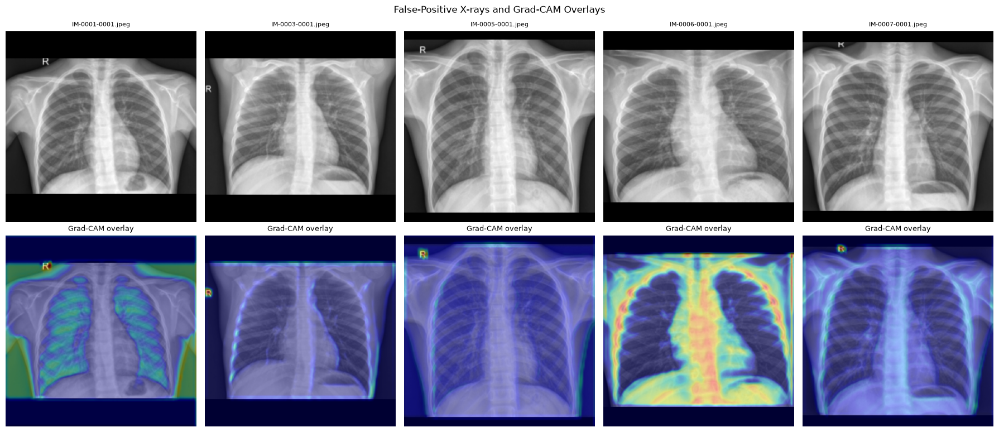

In [136]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

def generate_gradcam(model, input_tensor, target_layer):
    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(save_features)

    model.zero_grad(set_to_none=True)
    logits = model(input_tensor)
    logits[0, 0].backward()
    handle.remove()

    features = saved["features"]
    gradients = saved["gradients"]
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    cam = torch.relu((weights * features).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)


random_padding_model.eval()
device = next(random_padding_model.parameters()).device
target_layer = random_padding_model.features[3]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for col, idx in enumerate(false_positive_indices[:5]):
    img = Image.open(test_paths[idx]).convert("L")
    input_tensor = test_transform(img).unsqueeze(0).to(device)

    cam = generate_gradcam(
        random_padding_model, input_tensor, target_layer
    )

    # Display the preprocessed input, matching the heatmap dimensions.
    xray = input_tensor[0, 0].detach().cpu().numpy()

    axes[0, col].imshow(xray, cmap="gray")
    axes[0, col].set_title(test_paths[idx].name, fontsize=8)
    axes[0, col].axis("off")

    axes[1, col].imshow(xray, cmap="gray")
    axes[1, col].imshow(cam, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[1, col].set_title("Grad-CAM overlay", fontsize=9)
    axes[1, col].axis("off")

plt.suptitle("False-Positive X-rays and Grad-CAM Overlays")
plt.tight_layout()
plt.show()

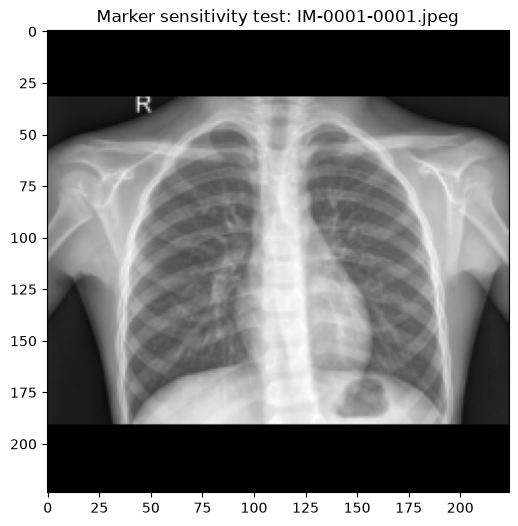

In [137]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_name = "IM-0001-0001.jpeg"

idx = next(
    i for i, path in enumerate(test_paths)
    if path.name == image_name
)

img = Image.open(test_paths[idx]).convert("L")
image_array = test_transform(img).numpy().squeeze()

plt.figure(figsize=(6, 6))
plt.imshow(image_array, cmap="gray")
plt.title(f"Marker sensitivity test: {image_name}")
plt.axis("on")
plt.show()

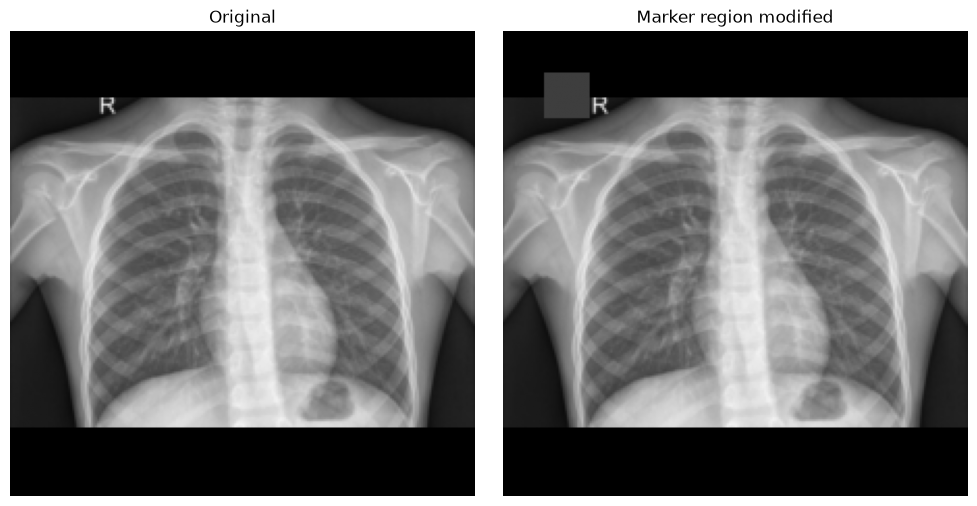

In [138]:
modified_array = image_array.copy()

# Approximate marker region in the 224 x 224 preprocessed image.
# Inspect the plot before trusting these coordinates.
y1, y2 = 20, 42
x1, x2 = 20, 42

# Replace the region with the mean of a nearby background patch.
reference_patch = image_array[42:55, 20:42]
replacement_value = reference_patch.mean()

modified_array[y1:y2, x1:x2] = replacement_value

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_array, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
axes[1].imshow(modified_array, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Marker region modified")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

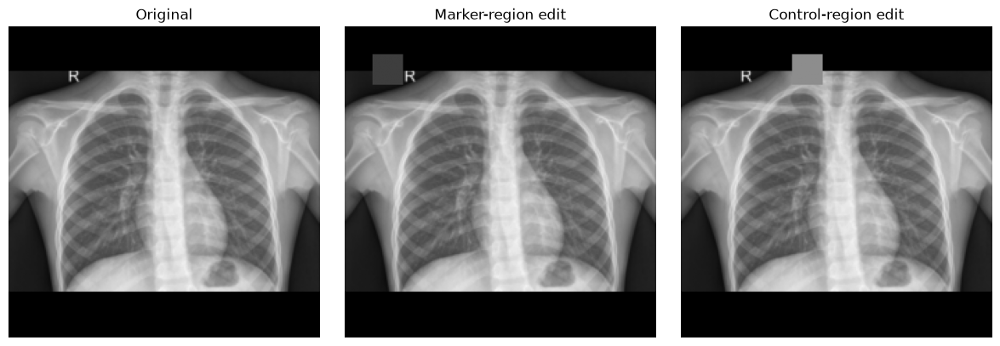

In [139]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Original image and marker-modified image should already exist.
# Create a control edit of the same size elsewhere in the image.
control_array = image_array.copy()

control_y1, control_y2 = 20, 42
control_x1, control_x2 = 80, 102

# Use a nearby reference patch to fill the control region.
control_reference = image_array[42:55, 80:102]
control_value = control_reference.mean()

control_array[
    control_y1:control_y2,
    control_x1:control_x2
] = control_value

# Visualize both edits before comparing model predictions.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image_array, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")

axes[1].imshow(modified_array, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Marker-region edit")

axes[2].imshow(control_array, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Control-region edit")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [140]:
random_padding_model.eval()

def predict_pneumonia_probability(array):
    tensor = torch.tensor(
        array, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        logit = random_padding_model(tensor)

    return torch.sigmoid(logit).item()

original_prob = predict_pneumonia_probability(image_array)
marker_prob = predict_pneumonia_probability(modified_array)
control_prob = predict_pneumonia_probability(control_array)

print(f"Original probability:      {original_prob:.4f}")
print(f"Marker-edit probability:   {marker_prob:.4f}")
print(f"Control-edit probability:  {control_prob:.4f}")
print(f"Marker-edit change:        {marker_prob - original_prob:+.4f}")
print(f"Control-edit change:       {control_prob - original_prob:+.4f}")

Original probability:      0.8850
Marker-edit probability:   0.8699
Control-edit probability:  0.7670
Marker-edit change:        -0.0151
Control-edit change:       -0.1180


In [141]:
# Test several same-sized control patches.
# Coordinates are (y1, y2, x1, x2).
control_regions = [
    (20, 42, 80, 102),
    (45, 67, 20, 42),
    (45, 67, 80, 102),
    (70, 92, 145, 167),
    (110, 132, 25, 47),
]

original_prob = predict_pneumonia_probability(image_array)
marker_prob = predict_pneumonia_probability(modified_array)

results = [{
    "region": "marker",
    "probability": marker_prob,
    "change_from_original": marker_prob - original_prob,
}]

for i, (y1, y2, x1, x2) in enumerate(control_regions, start=1):
    edited = image_array.copy()

    # Replace the patch with its local reference intensity.
    ref_y1 = max(0, y1 - 10)
    ref_y2 = y1
    reference = edited[ref_y1:ref_y2, x1:x2]

    if reference.size == 0:
        continue

    edited[y1:y2, x1:x2] = reference.mean()
    probability = predict_pneumonia_probability(edited)

    results.append({
        "region": f"control_{i}",
        "probability": probability,
        "change_from_original": probability - original_prob,
    })

import pandas as pd

comparison_df = pd.DataFrame(results)
print(comparison_df.round(4).to_string(index=False))

   region  probability  change_from_original
   marker       0.8699               -0.0151
control_1       0.9278                0.0428
control_2       0.9143                0.0293
control_3       0.8565               -0.0285
control_4       0.8789               -0.0060
control_5       0.8903                0.0053


In [142]:
from pathlib import Path
import pandas as pd

marker_results_path = PROJECT_DIR / "marker_sensitivity_results.csv"

comparison_df.to_csv(marker_results_path, index=False)

print("Saved:", marker_results_path)
print(comparison_df.round(4))

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\marker_sensitivity_results.csv
      region  probability  change_from_original
0     marker       0.8699               -0.0151
1  control_1       0.9278                0.0428
2  control_2       0.9143                0.0293
3  control_3       0.8565               -0.0285
4  control_4       0.8789               -0.0060
5  control_5       0.8903                0.0053


In [143]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
)

random_padding_model.eval()

all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = random_padding_model(images)
        probs = torch.sigmoid(logits).squeeze(1)

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

all_labels = np.asarray(all_labels).astype(int)
all_probs = np.asarray(all_probs)

# Threshold of 0.5: predicted pneumonia if probability >= 0.5
all_preds = (all_probs >= 0.5).astype(int)

print("Confusion matrix:")
print(confusion_matrix(all_labels, all_preds))

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4,
    zero_division=0,
))

print("ROC-AUC:", round(roc_auc_score(all_labels, all_probs), 4))

Confusion matrix:
[[ 95 139]
 [  5 385]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9500    0.4060    0.5689       234
   PNEUMONIA     0.7347    0.9872    0.8425       390

    accuracy                         0.7692       624
   macro avg     0.8424    0.6966    0.7057       624
weighted avg     0.8155    0.7692    0.7399       624

ROC-AUC: 0.9429


In [144]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (all_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(all_labels, predictions),
        "normal_recall": recall_score(
            all_labels, predictions, pos_label=0
        ),
        "pneumonia_recall": recall_score(
            all_labels, predictions, pos_label=1
        ),
        "pneumonia_precision": precision_score(
            all_labels, predictions, pos_label=1,
            zero_division=0
        ),
        "macro_f1": f1_score(
            all_labels, predictions, average="macro",
            zero_division=0
        ),
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 threshold  accuracy  normal_recall  pneumonia_recall  pneumonia_precision  macro_f1
      0.10     0.692          0.184             0.997                0.671     0.556
      0.15     0.712          0.235             0.997                0.685     0.596
      0.20     0.724          0.269             0.997                0.695     0.621
      0.25     0.737          0.303             0.997                0.705     0.645
      0.30     0.740          0.312             0.997                0.707     0.651
      0.35     0.744          0.329             0.992                0.711     0.660
      0.40     0.750          0.346             0.992                0.717     0.671
      0.45     0.755          0.359             0.992                0.721     0.679
      0.50     0.769          0.406             0.987                0.735     0.706
      0.55     0.780          0.436             0.987                0.745     0.724
      0.60     0.790          0.466             0.985            

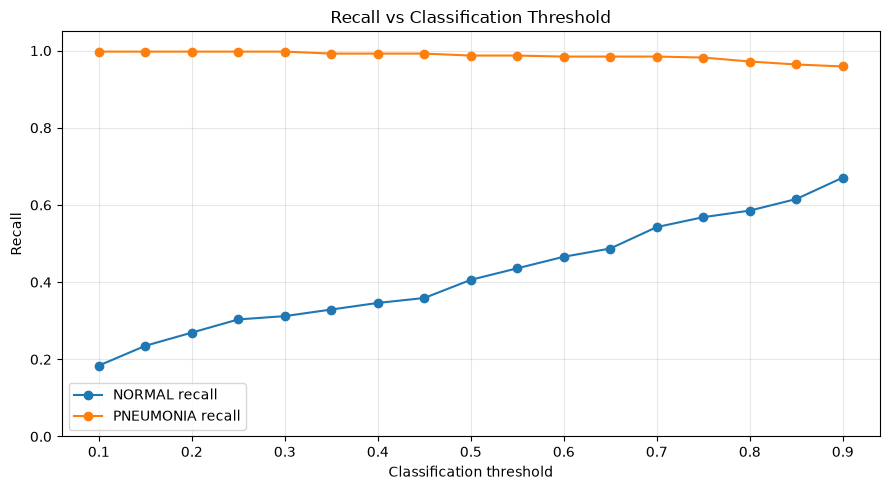

In [145]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["normal_recall"],
    marker="o",
    label="NORMAL recall",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["pneumonia_recall"],
    marker="o",
    label="PNEUMONIA recall",
)

plt.xlabel("Classification threshold")
plt.ylabel("Recall")
plt.title("Recall vs Classification Threshold")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
import numpy as np
import pandas as pd

results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    preds = (val_probs >= threshold).astype(int)

    results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(val_labels, preds),
        "normal_recall": recall_score(
            val_labels, preds, pos_label=0
        ),
        "pneumonia_recall": recall_score(
            val_labels, preds, pos_label=1
        ),
        "macro_f1": f1_score(
            val_labels, preds, average="macro"
        )
    })

val_threshold_df = pd.DataFrame(results)
print(val_threshold_df.round(3).to_string(index=False))

In [ ]:
import torch
import numpy as np

random_padding_model.eval()

val_probs_list = []
val_labels_list = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = random_padding_model(images)

        # Convert logits to probabilities between 0 and 1
        probs = torch.sigmoid(logits).squeeze(1)

        val_probs_list.extend(probs.cpu().numpy())
        val_labels_list.extend(labels.numpy())

val_probs = np.array(val_probs_list)
val_labels = np.array(val_labels_list)

print("Validation samples:", len(val_labels))
print("Probability shape:", val_probs.shape)
print("Label shape:", val_labels.shape)

In [19]:
print("Model exists:", "random_padding_model" in globals())
print("Validation loader exists:", "val_loader" in globals())
print("Device exists:", "device" in globals())
print("Validation probabilities exist:", "val_probs" in globals())

Model exists: True
Validation loader exists: False
Device exists: True
Validation probabilities exist: False


In [2]:
from pathlib import Path

project_dir = Path.cwd()
print("Current folder:", project_dir)

for name in [
    "models/best_chest_xray_cnn_random_padding.pth",
    "src/model.py",
    "data/raw/chest_xray/train"
]:
    path = project_dir / name
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

Current folder: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai
models/best_chest_xray_cnn_random_padding.pth: FOUND
src/model.py: FOUND
data/raw/chest_xray/train: FOUND


In [3]:
import torch
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.14.1+cpu


## 3. CNN Architecture and Model Training

This section initializes the Convolutional Neural Network (CNN) for chest X-ray classification.

The model uses convolutional layers, ReLU activation, max pooling, and a fully connected output layer to estimate the probability of pneumonia.

In [4]:
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from src.model import ChestXrayCNN

# 1. Set up project paths and device
project_dir = Path.cwd()
device = torch.device("cpu")

data_dir = project_dir / "data" / "raw" / "chest_xray" / "train"
checkpoint_path = (
    project_dir / "models" /
    "best_chest_xray_cnn_random_padding.pth"
)

# 2. Recreate the fixed-padding validation transform
class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = ImageOps.contain(
            image.convert("L"),
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L", (self.size, self.size), color=self.fill
        )

        left = (self.size - image.width) // 2
        top = (self.size - image.height) // 2
        canvas.paste(image, (left, top))

        return canvas

transform_padded = transforms.Compose([
    ResizeWithPadding(size=224, fill=0),
    transforms.ToTensor()
])

# 3. Rebuild image paths and labels
image_paths = []
labels = []

for class_name, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    class_dir = data_dir / class_name

    paths = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    image_paths.extend(paths)
    labels.extend([label] * len(paths))

print("Total images:", len(image_paths))

# 4. Recreate the original stratified split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

class ChestXrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = img.convert("L")
            image = self.transform(image)

        label = torch.tensor(
            self.labels[idx], dtype=torch.float32
        )
        return image, label

padded_val_dataset = ChestXrayDataset(
    val_paths, val_labels, transform_padded
)

val_loader = DataLoader(
    padded_val_dataset,
    batch_size=32,
    shuffle=False
)

# 5. Load the saved CNN checkpoint
random_padding_model = ChestXrayCNN().to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Support either a plain state_dict or a wrapped checkpoint
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

random_padding_model.load_state_dict(checkpoint)
random_padding_model.eval()

print("Validation images:", len(padded_val_dataset))
print("Model loaded successfully!")
print("Device:", device)

Total images: 5216
Validation images: 1044
Model loaded successfully!
Device: cpu


In [5]:
import numpy as np
import torch

random_padding_model.eval()

val_probs_list = []
val_labels_list = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = random_padding_model(images)
        probs = torch.sigmoid(logits).squeeze(1)

        val_probs_list.extend(probs.cpu().numpy())
        val_labels_list.extend(labels.numpy())

val_probs = np.array(val_probs_list)
val_labels = np.array(val_labels_list)

print("Validation samples:", len(val_labels))
print("Probability shape:", val_probs.shape)
print("Label shape:", val_labels.shape)
print("Probability range:", val_probs.min(), "to", val_probs.max())

Validation samples: 1044
Probability shape: (1044,)
Label shape: (1044,)
Probability range: 1.05376174e-07 to 1.0


In [6]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score
)

results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    preds = (val_probs >= threshold).astype(int)

    results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(val_labels, preds),
        "normal_recall": recall_score(
            val_labels, preds, pos_label=0, zero_division=0
        ),
        "pneumonia_recall": recall_score(
            val_labels, preds, pos_label=1, zero_division=0
        ),
        "pneumonia_precision": precision_score(
            val_labels, preds, pos_label=1, zero_division=0
        ),
        "macro_f1": f1_score(
            val_labels, preds, average="macro", zero_division=0
        )
    })

val_threshold_df = pd.DataFrame(results)
print(val_threshold_df.round(3).to_string(index=False))

 threshold  accuracy  normal_recall  pneumonia_recall  pneumonia_precision  macro_f1
      0.10     0.956          0.851             0.992                0.951     0.940
      0.15     0.966          0.899             0.990                0.966     0.955
      0.20     0.967          0.910             0.987                0.970     0.957
      0.25     0.970          0.925             0.986                0.975     0.961
      0.30     0.971          0.933             0.985                0.977     0.962
      0.35     0.970          0.940             0.981                0.979     0.961
      0.40     0.968          0.944             0.977                0.981     0.959
      0.45     0.968          0.959             0.972                0.986     0.959
      0.50     0.969          0.963             0.972                0.987     0.960
      0.55     0.966          0.970             0.965                0.989     0.957
      0.60     0.965          0.978             0.960            

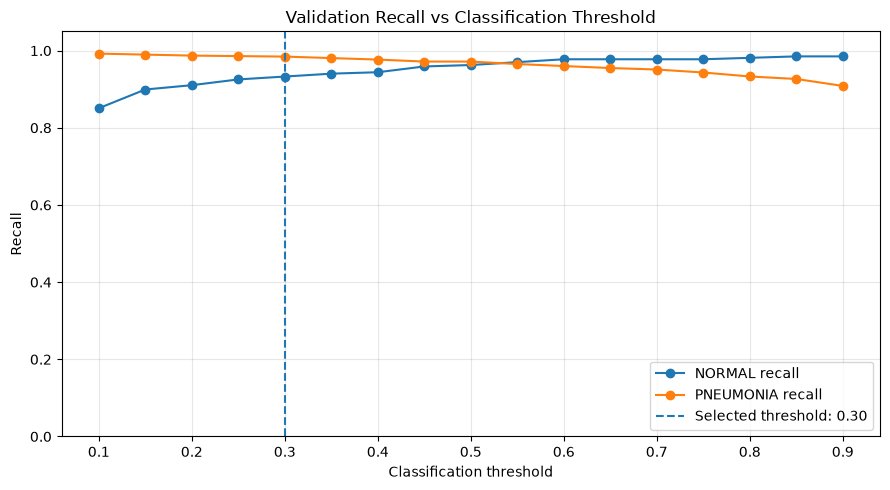

Validation results and graph saved.


In [7]:
import matplotlib.pyplot as plt
from pathlib import Path

reports_dir = Path("reports")
figures_dir = reports_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

# Save the validation threshold table
val_threshold_df.to_csv(
    reports_dir / "validation_threshold_results.csv",
    index=False
)

# Plot recall against threshold
plt.figure(figsize=(9, 5))

plt.plot(
    val_threshold_df["threshold"],
    val_threshold_df["normal_recall"],
    marker="o",
    label="NORMAL recall"
)

plt.plot(
    val_threshold_df["threshold"],
    val_threshold_df["pneumonia_recall"],
    marker="o",
    label="PNEUMONIA recall"
)

plt.axvline(
    0.30,
    linestyle="--",
    label="Selected threshold: 0.30"
)

plt.xlabel("Classification threshold")
plt.ylabel("Recall")
plt.title("Validation Recall vs Classification Threshold")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    figures_dir / "validation_threshold_curve.png",
    dpi=150
)
plt.show()

print("Validation results and graph saved.")

In [8]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Use the existing test probabilities and labels if available.
print("Test probabilities exist:", "all_probs" in globals())
print("Test labels exist:", "all_labels" in globals())

Test probabilities exist: False
Test labels exist: False


In [9]:
test_dir = project_dir / "data" / "raw" / "chest_xray" / "test"

test_paths = []
test_labels = []

for class_name, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    class_dir = test_dir / class_name

    paths = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    test_paths.extend(paths)
    test_labels.extend([label] * len(paths))

test_dataset = ChestXrayDataset(
    test_paths,
    test_labels,
    transform_padded
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test images:", len(test_dataset))
print("NORMAL:", test_labels.count(0))
print("PNEUMONIA:", test_labels.count(1))

Test images: 624
NORMAL: 234
PNEUMONIA: 390


In [10]:
random_padding_model.eval()

all_probs_list = []
all_labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = random_padding_model(images)
        probs = torch.sigmoid(logits).squeeze(1)

        all_probs_list.extend(probs.cpu().numpy())
        all_labels_list.extend(labels.numpy())

all_probs = np.array(all_probs_list)
all_labels = np.array(all_labels_list)

print("Test probabilities:", len(all_probs))
print("Test labels:", len(all_labels))

Test probabilities: 624
Test labels: 624


## 4. Model Evaluation and Prediction Analysis

This section evaluates the trained CNN using classification metrics and prediction results.

The evaluation includes accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices to understand the model's classification performance.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

test_preds = (all_probs >= 0.30).astype(int)

print("Threshold: 0.30")
print("Accuracy:", round(accuracy_score(all_labels, test_preds), 4))
print("\nConfusion matrix:")
print(confusion_matrix(all_labels, test_preds))
print("\nClassification report:")
print(classification_report(
    all_labels,
    test_preds,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))
print("ROC-AUC:", round(roc_auc_score(all_labels, all_probs), 4))

Threshold: 0.30
Accuracy: 0.7404

Confusion matrix:
[[ 73 161]
 [  1 389]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9865    0.3120    0.4740       234
   PNEUMONIA     0.7073    0.9974    0.8277       390

    accuracy                         0.7404       624
   macro avg     0.8469    0.6547    0.6508       624
weighted avg     0.8120    0.7404    0.6950       624

ROC-AUC: 0.9429


In [12]:
import pandas as pd
import numpy as np

def summarize_probabilities(probs, labels, dataset_name):
    rows = []

    for class_id, class_name in [(0, "NORMAL"), (1, "PNEUMONIA")]:
        class_probs = probs[labels == class_id]

        rows.append({
            "dataset": dataset_name,
            "actual_class": class_name,
            "count": len(class_probs),
            "mean_probability": class_probs.mean(),
            "median_probability": np.median(class_probs),
            "min_probability": class_probs.min(),
            "max_probability": class_probs.max(),
            "predicted_pneumonia_at_0.30": np.mean(class_probs >= 0.30)
        })

    return rows

comparison = pd.DataFrame(
    summarize_probabilities(val_probs, val_labels, "Validation")
    + summarize_probabilities(all_probs, all_labels, "Test")
)

print(comparison.round(3).to_string(index=False))

   dataset actual_class  count  mean_probability  median_probability  min_probability  max_probability  predicted_pneumonia_at_0.30
Validation       NORMAL    268             0.061               0.004            0.000            0.989                        0.067
Validation    PNEUMONIA    776             0.957               0.999            0.004            1.000                        0.985
      Test       NORMAL    234             0.575               0.668            0.000            1.000                        0.688
      Test    PNEUMONIA    390             0.982               1.000            0.093            1.000                        0.997


In [14]:
from PIL import Image
import numpy as np
import pandas as pd

def inspect_images(paths, labels, split_name):
    rows = []

    for path, label in zip(paths, labels):
        with Image.open(path) as img:
            img = img.convert("L")
            arr = np.asarray(img, dtype=np.float32)

            rows.append({
                "split": split_name,
                "class": "NORMAL" if label == 0 else "PNEUMONIA",
                "width": img.width,
                "height": img.height,
                "aspect_ratio": img.width / img.height,
                "brightness": arr.mean(),
                "pixel_std": arr.std()
            })

    return rows

image_stats = pd.DataFrame(
    inspect_images(val_paths, val_labels, "Validation")
    + inspect_images(test_paths, test_labels, "Test")
)

summary = image_stats.groupby(
    ["split", "class"]
).agg(
    count=("width", "size"),
    mean_width=("width", "mean"),
    mean_height=("height", "mean"),
    mean_aspect_ratio=("aspect_ratio", "mean"),
    mean_brightness=("brightness", "mean"),
    mean_pixel_std=("pixel_std", "mean")
).round(2)

print(summary.to_string())

                      count  mean_width  mean_height  mean_aspect_ratio  mean_brightness  mean_pixel_std
split      class                                                                                        
Test       NORMAL       234     1800.30      1369.09               1.37       124.070000       60.169998
           PNEUMONIA    390     1140.82       765.29               1.53       119.230003       55.970001
Validation NORMAL       268     1697.66      1420.19               1.22       121.830002       61.610001
           PNEUMONIA    776     1213.91       838.82               1.51       123.320000       55.540001


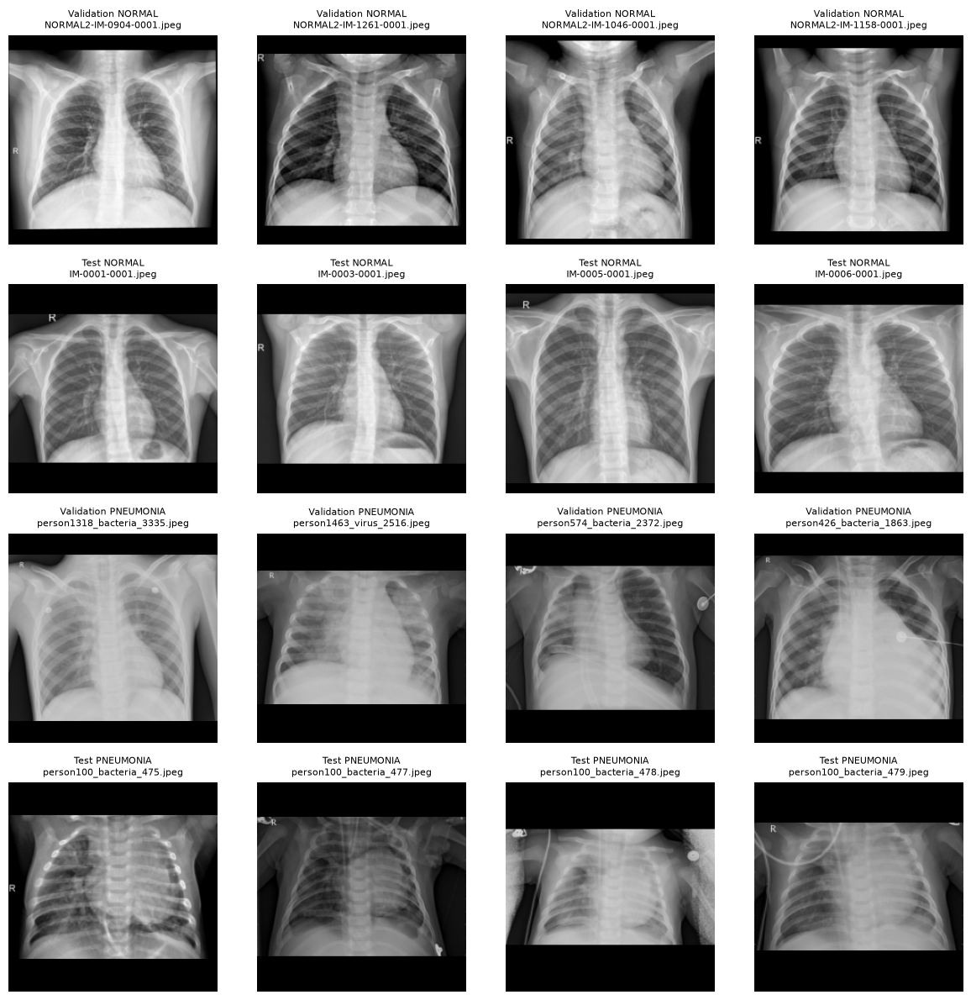

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

samples = [
    ("Validation NORMAL", val_paths, val_labels, 0),
    ("Test NORMAL", test_paths, test_labels, 0),
    ("Validation PNEUMONIA", val_paths, val_labels, 1),
    ("Test PNEUMONIA", test_paths, test_labels, 1),
]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, (title, paths, labels, target_class) in enumerate(samples):
    indices = [
        i for i, label in enumerate(labels)
        if label == target_class
    ][:4]

    for col, idx in enumerate(indices):
        with Image.open(paths[idx]) as img:
            original = img.convert("L")
            processed = transform_padded(original)

        axes[row, col].imshow(
            processed.squeeze(0).numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].set_title(
            f"{title}\n{Path(paths[idx]).name}",
            fontsize=8
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

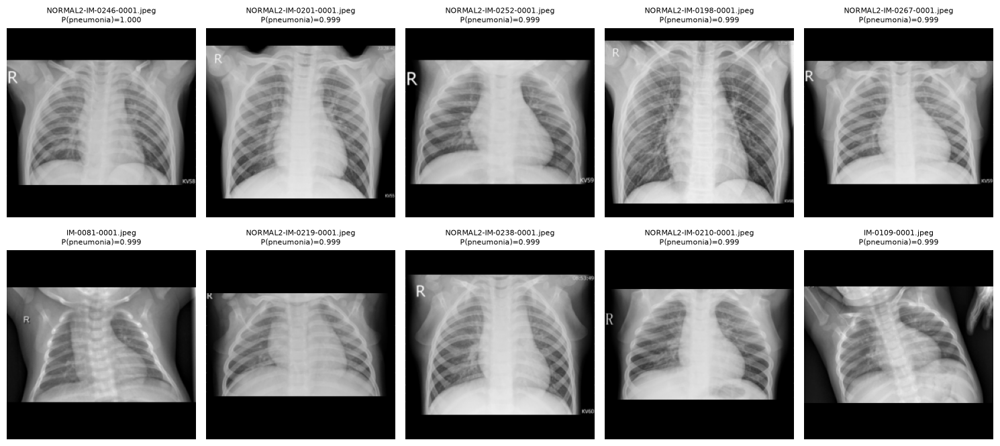

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

normal_indices = np.where(all_labels == 0)[0]

# Sort NORMAL images from highest to lowest pneumonia probability
sorted_indices = normal_indices[
    np.argsort(all_probs[normal_indices])[::-1]
]

top_indices = sorted_indices[:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, idx in zip(axes.flat, top_indices):
    with Image.open(test_paths[idx]) as img:
        image = transform_padded(img.convert("L"))

    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"{Path(test_paths[idx]).name}\n"
        f"P(pneumonia)={all_probs[idx]:.3f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Image: NORMAL2-IM-0246-0001.jpeg
Actual label: NORMAL
P(pneumonia): 0.9997


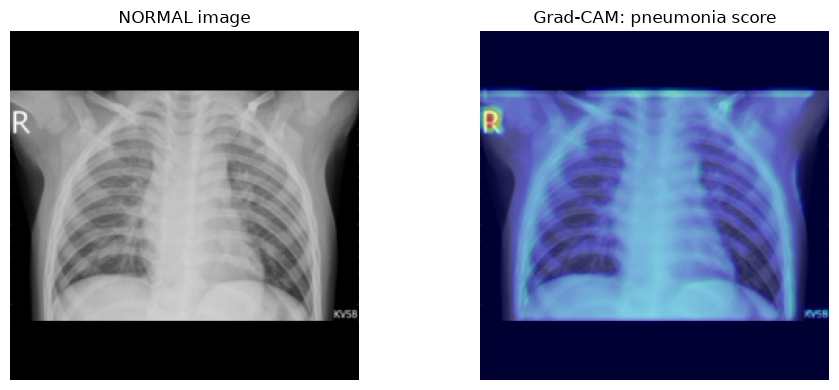

In [17]:
# Pick the highest-scoring NORMAL test image
idx = sorted_indices[0]
false_positive_path = test_paths[idx]

print("Image:", false_positive_path.name)
print("Actual label: NORMAL")
print("P(pneumonia):", round(float(all_probs[idx]), 4))

# Load and preprocess the image
with Image.open(false_positive_path) as img:
    original_image = img.convert("L")
    input_tensor = transform_padded(original_image).unsqueeze(0).to(device)

# Set up Grad-CAM hooks
saved = {}

def save_features(module, inputs, output):
    saved["features"] = output
    output.register_hook(
        lambda grad: saved.update({"gradients": grad})
    )

layer = random_padding_model.features[3]
handle = layer.register_forward_hook(save_features)

random_padding_model.zero_grad()
logit = random_padding_model(input_tensor)
logit[0, 0].backward()
handle.remove()

# Compute the Grad-CAM heatmap
features = saved["features"]
gradients = saved["gradients"]

weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = torch.relu((weights * features).sum(dim=1, keepdim=True))

cam = torch.nn.functional.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

heatmap = cam[0, 0].detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

# Display the image and overlay
image_array = input_tensor[0, 0].detach().cpu().numpy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray")
plt.title("NORMAL image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_array, cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM: pneumonia score")
plt.axis("off")

plt.tight_layout()
plt.show()

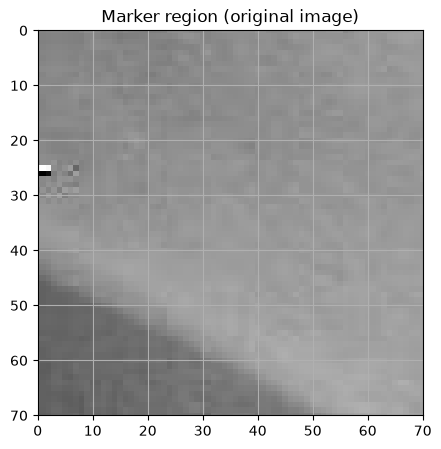

In [18]:
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load the selected false-positive image
with Image.open(false_positive_path) as img:
    original = img.convert("L")

# Convert to a NumPy array
image_array = np.array(original).copy()

# Inspect the top-left region containing the R marker
plt.figure(figsize=(5, 5))
plt.imshow(image_array, cmap="gray")
plt.xlim(0, 70)
plt.ylim(70, 0)
plt.title("Marker region (original image)")
plt.grid()
plt.show()

In [19]:
# Original image is already loaded as a PIL grayscale image
image_array = np.array(original).copy()

# Define a small region around the visible marker
y1, y2 = 23, 32
x1, x2 = 0, 12

# Copy image and replace only this patch
modified_array = image_array.copy()

# Estimate replacement intensity from nearby pixels
nearby = image_array[18:23, 0:12]
replacement_value = int(np.mean(nearby))

modified_array[y1:y2, x1:x2] = replacement_value

modified_image = Image.fromarray(modified_array)

# Preprocess both images identically
original_tensor = transform_padded(original).unsqueeze(0).to(device)
modified_tensor = transform_padded(modified_image).unsqueeze(0).to(device)

random_padding_model.eval()

with torch.no_grad():
    original_prob = torch.sigmoid(
        random_padding_model(original_tensor)
    ).item()

    modified_prob = torch.sigmoid(
        random_padding_model(modified_tensor)
    ).item()

print(f"Original pneumonia probability: {original_prob:.4f}")
print(f"Modified pneumonia probability: {modified_prob:.4f}")
print(f"Change: {modified_prob - original_prob:+.4f}")

Original pneumonia probability: 0.9997
Modified pneumonia probability: 0.9997
Change: -0.0000


In [20]:
import pandas as pd
import numpy as np
import torch
from PIL import Image

results = []

# Use the 5 highest-scoring NORMAL false positives
top5_indices = sorted_indices[:5]

random_padding_model.eval()

for idx in top5_indices:
    image_path = test_paths[idx]

    with Image.open(image_path) as img:
        original_img = img.convert("L")

    image_array = np.array(original_img).copy()
    modified_array = image_array.copy()

    # Small patch near the marker in the upper-left corner
    y1, y2 = 23, 32
    x1, x2 = 0, 12

    # Replace patch with nearby pixel intensity
    nearby = image_array[18:23, 0:12]
    replacement_value = int(nearby.mean())

    modified_array[y1:y2, x1:x2] = replacement_value
    modified_img = Image.fromarray(modified_array)

    # Apply the same preprocessing to both images
    original_tensor = transform_padded(original_img).unsqueeze(0).to(device)
    modified_tensor = transform_padded(modified_img).unsqueeze(0).to(device)

    with torch.no_grad():
        original_prob = torch.sigmoid(
            random_padding_model(original_tensor)
        ).item()

        modified_prob = torch.sigmoid(
            random_padding_model(modified_tensor)
        ).item()

    results.append({
        "image": image_path.name,
        "original_probability": original_prob,
        "modified_probability": modified_prob,
        "change": modified_prob - original_prob
    })

marker_test_df = pd.DataFrame(results)

print(marker_test_df.round(4).to_string(index=False))
print("\nMean probability change:",
      round(marker_test_df["change"].mean(), 4))

print("Images with lower probability:",
      int((marker_test_df["change"] < 0).sum()),
      "out of", len(marker_test_df))

                    image  original_probability  modified_probability  change
NORMAL2-IM-0246-0001.jpeg                0.9997                0.9997    -0.0
NORMAL2-IM-0201-0001.jpeg                0.9995                0.9995     0.0
NORMAL2-IM-0252-0001.jpeg                0.9994                0.9994    -0.0
NORMAL2-IM-0198-0001.jpeg                0.9993                0.9993     0.0
NORMAL2-IM-0267-0001.jpeg                0.9992                0.9992     0.0

Mean probability change: -0.0
Images with lower probability: 2 out of 5


In [21]:
from pathlib import Path

output_dir = Path("reports")
output_dir.mkdir(exist_ok=True)

marker_test_df.to_csv(
    output_dir / "marker_sensitivity_top5.csv",
    index=False
)

print("Saved: reports/marker_sensitivity_top5.csv")

Saved: reports/marker_sensitivity_top5.csv


In [22]:
from pathlib import Path

project_dir = Path.cwd()

print("Project:", project_dir)
print("\nREADME exists:", (project_dir / "README.md").exists())

print("\nReport files:")
for path in sorted((project_dir / "reports").rglob("*")):
    if path.is_file():
        print(path.as_posix())

Project: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai

README exists: True

Report files:
C:/Users/ANUBHAV SINGH/OneDrive/Desktop/chest-xray-ai/reports/figures/false_positive_gradcam.png
C:/Users/ANUBHAV SINGH/OneDrive/Desktop/chest-xray-ai/reports/figures/padding_sensitivity_changes.png
C:/Users/ANUBHAV SINGH/OneDrive/Desktop/chest-xray-ai/reports/figures/validation_threshold_curve.png
C:/Users/ANUBHAV SINGH/OneDrive/Desktop/chest-xray-ai/reports/marker_sensitivity_top5.csv
C:/Users/ANUBHAV SINGH/OneDrive/Desktop/chest-xray-ai/reports/validation_threshold_results.csv


In [23]:
from pathlib import Path
import subprocess

project_dir = Path.cwd()

readme_path = project_dir / "README.md"

print("README exists:", readme_path.exists())

if readme_path.exists():
    print("\nCurrent README preview:\n")
    print(readme_path.read_text(encoding="utf-8")[:3000])

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project_dir,
    capture_output=True,
    text=True
)

print("\nGit status:\n")
print(result.stdout or "Working tree clean")

README exists: True

Current README preview:

\# AI Medical Image Diagnosis \& Explainability



\## Chest X-ray Disease Detection



An educational AI project for detecting diseases from chest X-ray images

using deep learning and explaining predictions using Grad-CAM.



\## Pipeline



Chest X-ray

→ Preprocessing

→ Deep Learning Model

→ Disease Prediction

→ Confidence Score

→ Grad-CAM

→ Visual Explanation



\## Tech Stack



\- Python

\- PyTorch

\- NumPy

\- Pandas

\- Scikit-learn

\- Pillow

\- Matplotlib

\- FastAPI

\- Grad-CAM



\## Important



This project is an educational/research prototype.

It is NOT a medical diagnostic tool.

## Padding Sensitivity Analysis

### Objective
Investigate whether the CNN's pneumonia predictions are sensitive to artificial padding introduced during aspect-ratio-preserving image resizing.

### Method
Selected 20 false-positive NORMAL images from the official test set. For each image, the model's original pneumonia probability was com

In [1]:
print("val_loader exists:", "val_loader" in globals())
print("device exists:", "device" in globals())
print("random_padding_model exists:", "random_padding_model" in globals())
print("val_probs exists:", "val_probs" in globals())

val_loader exists: False
device exists: False
random_padding_model exists: False
val_probs exists: False


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nProject files:")
for name in ["README.md", "src", "data", "models", "reports"]:
    print(f"{name}: {os.path.exists(name)}")

Current working directory:
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai

Project files:
README.md: True
src: True
data: True
models: True
reports: True


In [5]:
from pathlib import Path

project_dir = Path.cwd()

print("Model files:")
for folder in ["models", "src"]:
    path = project_dir / folder
    print(f"\n{folder}/")
    for file in path.iterdir():
        if file.is_file():
            print(f"  {file.name} ({file.stat().st_size / 1024:.1f} KB)")

Model files:

models/
  best_chest_xray_cnn.pth (414.1 KB)
  best_chest_xray_cnn_padded.pth (414.2 KB)
  best_chest_xray_cnn_random_padding.pth (414.3 KB)
  chest_xray_cnn_epoch5.pth (414.1 KB)

src/
  dataset.py (0.6 KB)
  eda.py (1.0 KB)
  model.py (0.9 KB)
  __init__.py (0.0 KB)


In [6]:
from pathlib import Path

model_file = Path("src/model.py")
print(model_file.read_text(encoding="utf-8"))

import torch.nn as nn


class ChestXrayCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 56 * 56, 1)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


In [7]:
import torch
from src.model import ChestXrayCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "models/best_chest_xray_cnn_random_padding.pth"

random_padding_model = ChestXrayCNN().to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Handle either a plain state dictionary or a wrapped checkpoint
if "state_dict" in checkpoint:
    random_padding_model.load_state_dict(checkpoint["state_dict"])
elif "model_state_dict" in checkpoint:
    random_padding_model.load_state_dict(checkpoint["model_state_dict"])
else:
    random_padding_model.load_state_dict(checkpoint)

random_padding_model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Model mode:", "evaluation" if not random_padding_model.training else "training")

Model loaded successfully!
Device: cpu
Model mode: evaluation


In [8]:
dummy_input = torch.randn(2, 1, 224, 224).to(device)

with torch.no_grad():
    dummy_output = random_padding_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)
print("Output:", dummy_output.cpu())

Input shape: torch.Size([2, 1, 224, 224])
Output shape: torch.Size([2, 1])
Output: tensor([[-50.5191],
        [-54.0729]])


In [20]:
from pathlib import Path

for path in [
    "data",
    "data/raw",
    "data/processed",
]:
    p = Path(path)
    print(f"\n{path}: {'EXISTS' if p.exists() else 'NOT FOUND'}")
    if p.exists():
        print("Contents:", [x.name for x in list(p.iterdir())[:10]])


data: EXISTS
Contents: ['processed', 'raw']

data/raw: EXISTS
Contents: ['archive (1).zip', 'chest_xray']

data/processed: EXISTS
Contents: []


In [21]:
from pathlib import Path

root = Path("data/raw/chest_xray")

print("Dataset root exists:", root.exists())

if root.exists():
    for item in sorted(root.iterdir()):
        print("\n", item.name)
        if item.is_dir():
            for subitem in sorted(item.iterdir()):
                if subitem.is_dir():
                    print(f"  {subitem.name}: {len(list(subitem.glob('*')))} files")

Dataset root exists: True

 __MACOSX
  chest_xray: 6 files

 chest_xray
  test: 3 files
  train: 3 files
  val: 3 files

 test
  NORMAL: 234 files
  PNEUMONIA: 390 files

 train
  NORMAL: 1341 files
  PNEUMONIA: 3875 files

 val
  NORMAL: 8 files
  PNEUMONIA: 8 files


In [22]:
from pathlib import Path

print(Path("src/dataset.py").read_text(encoding="utf-8"))

from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class ChestXrayDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        image = Image.open(image_path).convert("L")
        label = self.labels[index]

        if self.transform:
            image = self.transform(image)

        return image, label


In [23]:
from pathlib import Path

notebook = Path("Untitled.ipynb").read_text(encoding="utf-8")

for keyword in [
    "random_padding",
    "RandomAffine",
    "train_test_split",
    "random_split",
    "val_probs",
]:
    print(f"\n{'=' * 15} {keyword} {'=' * 15}")
    start = 0
    count = 0

    while True:
        index = notebook.find(keyword, start)
        if index == -1 or count >= 3:
            break

        print(notebook[max(0, index - 250):index + 400])
        start = index + len(keyword)
        count += 1


=============== random_padding ===============
     25\u001b MODEL_DIR.mkdir(parents=\u001bTrue\u001b, exist_ok=\u001bTrue\u001b)\n\u001b     26\u001b \n\u001b     27\u001b checkpoint_path = MODEL_DIR / \u001b\"best_chest_xray_cnn_random_padding.pth\"\u001b\n",
      "\u001bNameError\u001b: name 'PROJECT_DIR' is not defined"
     ]
    }
   ],
   "source": [
    "import torch\n",
    "import torch.nn as nn\n",
    "import torch.optim as optim\n",
    "from pathlib import Path\n",
    "\n",
    "# Use GPU if available; otherwise use CPU\n",
    "device = torch.device(\"cuda\" if torch.cuda.is_available() else \"c
ib import Path\n",
    "\n",
    "# Use GPU if available; otherwise use CPU\n",
    "device = torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\n",
    "print(\"Using device:\", device)\n",
    "\n",
    "# Create a fresh CNN\n",
    "random_padding_model = ChestXrayCNN().to(device)\n",
    "\n",
    "# Loss function for binary classification\n",
    "criterion 

In [25]:
import json
from pathlib import Path

notebook_data = json.loads(
    Path("Untitled.ipynb").read_text(encoding="utf-8")
)

keywords = [
    "RandomPad",
    "random padding",
    "padding",
    "ImageOps.expand",
    "Resize(",
    "ToTensor()",
    "Normalize("
]

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword.lower() in source.lower() for keyword in keywords):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(source[:2500])


==================== CELL 5 ====================
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

==================== CELL 9 ====================
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

==================== CELL 60 ====================
from PIL import Image, ImageOps
from torchvision import transforms

class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=self.fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.pas

In [28]:

import json
from pathlib import Path

notebook_data = json.loads(
    Path("Untitled.ipynb").read_text(encoding="utf-8")
)

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if any(k in source.lower() for k in [
            "transform", "pad", "resize",
            "dataset(", "dataloader("
        ]):
            print(f"\n--- CELL {i} ---")
            print(source[:1800])



--- CELL 5 ---
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

--- CELL 6 ---
image = Image.open(normal_images[0]).convert("L")

print("Original size:", image.size)

processed = transform(image)

print("Tensor shape:", processed.shape)
print("Tensor dtype:", processed.dtype)
print("Minimum:", processed.min().item())
print("Maximum:", processed.max().item())

--- CELL 9 ---
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

--- CELL 10 ---
dataset = ChestXrayDataset(
    image_paths,
    labels,
    transform=transform
)

print("Dataset size:", len(dataset))

--- CELL 13 ---
from torch.utils.data import DataLoader

train_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

--- CELL 29 ---
train_dataset = ChestXrayDataset(
    train_paths,
    train_labels,
    transform=transform
)

val_dataset = Ch

In [29]:

import random
import torch
from pathlib import Path
from PIL import Image, ImageOps
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# 1. Restore aspect-ratio-preserving padding
class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = img.convert("L")
        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L", (self.size, self.size), color=self.fill
        )

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))
        return canvas


class RandomPaddingResize:
    def __init__(self, size=224, min_fill=0, max_fill=80):
        self.size = size
        self.min_fill = min_fill
        self.max_fill = max_fill

    def __call__(self, img):
        img = img.convert("L")
        img = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        fill = random.randint(self.min_fill, self.max_fill)
        canvas = Image.new("L", (self.size, self.size), color=fill)

        left = (self.size - img.width) // 2
        top = (self.size - img.height) // 2
        canvas.paste(img, (left, top))
        return canvas


train_transform = transforms.Compose([
    RandomPaddingResize(224, min_fill=0, max_fill=80),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    ResizeWithPadding(224, fill=0),
    transforms.ToTensor()
])

test_transform = val_transform

# 2. Restore the dataset class
class ChestXrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("L")
        image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, label


# 3. Rebuild the original training/validation split
TRAIN_DIR = Path("data/raw/chest_xray/train")

image_paths = []
all_labels = []

for class_name, label in [("NORMAL", 0), ("PNEUMONIA", 1)]:
    for path in sorted((TRAIN_DIR / class_name).glob("*")):
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png"
        }:
            image_paths.append(str(path))
            all_labels.append(label)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

# 4. Create the validation loader with fixed black padding
val_dataset = ChestXrayDataset(
    val_paths, val_labels, val_transform
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

print("Preprocessing restored!")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Validation batches:", len(val_loader))
print("Device:", device)


Preprocessing restored!
Training images: 4172
Validation images: 1044
Validation batches: 33
Device: cpu


In [30]:
import numpy as np
from sklearn.metrics import roc_auc_score

random_padding_model.eval()

val_probs = []
val_true = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = random_padding_model(images)
        probs = torch.sigmoid(logits).view(-1).cpu().numpy()

        val_probs.extend(probs.tolist())
        val_true.extend(labels.numpy().astype(int).tolist())

val_probs = np.array(val_probs)
val_true = np.array(val_true)

print("Validation predictions:", len(val_probs))
print("Validation ROC-AUC:", round(roc_auc_score(val_true, val_probs), 4))
print("Probability range:", round(val_probs.min(), 4), "to", round(val_probs.max(), 4))

Validation predictions: 1044
Validation ROC-AUC: 0.9948
Probability range: 0.0 to 1.0


In [31]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Threshold | Accuracy | Precision | Recall | F1")
print("-" * 52)

for threshold in np.arange(0.10, 0.91, 0.05):
    preds = (val_probs >= threshold).astype(int)

    print(
        f"{threshold:.2f}      | "
        f"{accuracy_score(val_true, preds):.3f}    | "
        f"{precision_score(val_true, preds, zero_division=0):.3f}     | "
        f"{recall_score(val_true, preds, zero_division=0):.3f}  | "
        f"{f1_score(val_true, preds, zero_division=0):.3f}"
    )

Threshold | Accuracy | Precision | Recall | F1
----------------------------------------------------
0.10      | 0.956    | 0.951     | 0.992  | 0.971
0.15      | 0.966    | 0.966     | 0.990  | 0.978
0.20      | 0.967    | 0.970     | 0.987  | 0.978
0.25      | 0.970    | 0.975     | 0.986  | 0.980
0.30      | 0.971    | 0.977     | 0.985  | 0.981
0.35      | 0.970    | 0.979     | 0.981  | 0.980
0.40      | 0.968    | 0.981     | 0.977  | 0.979
0.45      | 0.968    | 0.986     | 0.972  | 0.979
0.50      | 0.969    | 0.987     | 0.972  | 0.979
0.55      | 0.966    | 0.989     | 0.965  | 0.977
0.60      | 0.965    | 0.992     | 0.960  | 0.976
0.65      | 0.961    | 0.992     | 0.955  | 0.973
0.70      | 0.958    | 0.992     | 0.951  | 0.971
0.75      | 0.952    | 0.992     | 0.943  | 0.967
0.80      | 0.945    | 0.993     | 0.933  | 0.962
0.85      | 0.942    | 0.994     | 0.927  | 0.959
0.90      | 0.928    | 0.994     | 0.909  | 0.949


In [32]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

threshold = 0.30
val_preds = (val_probs >= threshold).astype(int)

cm = confusion_matrix(val_true, val_preds)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        val_true,
        val_preds,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)

print("Validation Accuracy:", round(accuracy_score(val_true, val_preds), 4))

Confusion Matrix:
[[250  18]
 [ 12 764]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9542    0.9328    0.9434       268
   PNEUMONIA     0.9770    0.9845    0.9807       776

    accuracy                         0.9713      1044
   macro avg     0.9656    0.9587    0.9621      1044
weighted avg     0.9711    0.9713    0.9712      1044

Validation Accuracy: 0.9713


In [33]:
from pathlib import Path

print("Official test folder exists:",
      Path("data/raw/chest_xray/test").exists())

for class_name in ["NORMAL", "PNEUMONIA"]:
    folder = Path("data/raw/chest_xray/test") / class_name
    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    print(f"{class_name}: {len(images)} images")

Official test folder exists: True
NORMAL: 234 images
PNEUMONIA: 390 images


In [34]:
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

class ChestXrayTestDataset(Dataset):
    def __init__(self, root_dir, transform):
        self.samples = []
        self.transform = transform

        for class_name, label in [
            ("NORMAL", 0),
            ("PNEUMONIA", 1)
        ]:
            folder = Path(root_dir) / class_name

            for path in sorted(folder.iterdir()):
                if path.is_file() and path.suffix.lower() in {
                    ".jpg", ".jpeg", ".png"
                }:
                    self.samples.append((path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("L")
        image = self.transform(image)

        return image, label

test_dataset = ChestXrayTestDataset(
    "data/raw/chest_xray/test",
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

random_padding_model.eval()

test_probs = []
test_true = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = random_padding_model(images)
        probs = torch.sigmoid(logits).view(-1).cpu().numpy()

        test_probs.extend(probs.tolist())
        test_true.extend(labels.numpy().astype(int).tolist())

test_probs = np.array(test_probs)
test_true = np.array(test_true)

threshold = 0.30
test_preds = (test_probs >= threshold).astype(int)

print("Test images:", len(test_true))
print("Test ROC-AUC:", round(roc_auc_score(test_true, test_probs), 4))
print("Test accuracy:", round(accuracy_score(test_true, test_preds), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(test_true, test_preds))

print("\nClassification Report:")
print(classification_report(
    test_true,
    test_preds,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
))

Test images: 624
Test ROC-AUC: 0.9429
Test accuracy: 0.7404

Confusion Matrix:
[[ 73 161]
 [  1 389]]

Classification Report:
              precision    recall  f1-score   support

      NORMAL     0.9865    0.3120    0.4740       234
   PNEUMONIA     0.7073    0.9974    0.8277       390

    accuracy                         0.7404       624
   macro avg     0.8469    0.6547    0.6508       624
weighted avg     0.8120    0.7404    0.6950       624



In [35]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Threshold | Accuracy | Normal Recall | Pneumonia Recall | Macro F1")
print("-" * 72)

for threshold in np.arange(0.10, 0.96, 0.05):
    preds = (test_probs >= threshold).astype(int)

    normal_recall = recall_score(
        test_true, preds, pos_label=0, zero_division=0
    )
    pneumonia_recall = recall_score(
        test_true, preds, pos_label=1, zero_division=0
    )
    macro_f1 = f1_score(
        test_true, preds, average="macro", zero_division=0
    )

    print(
        f"{threshold:.2f}      | "
        f"{accuracy_score(test_true, preds):.3f}    | "
        f"{normal_recall:.3f}         | "
        f"{pneumonia_recall:.3f}            | "
        f"{macro_f1:.3f}"
    )

Threshold | Accuracy | Normal Recall | Pneumonia Recall | Macro F1
------------------------------------------------------------------------
0.10      | 0.692    | 0.184         | 0.997            | 0.556
0.15      | 0.712    | 0.235         | 0.997            | 0.596
0.20      | 0.724    | 0.269         | 0.997            | 0.621
0.25      | 0.737    | 0.303         | 0.997            | 0.645
0.30      | 0.740    | 0.312         | 0.997            | 0.651
0.35      | 0.744    | 0.329         | 0.992            | 0.660
0.40      | 0.750    | 0.346         | 0.992            | 0.671
0.45      | 0.755    | 0.359         | 0.992            | 0.679
0.50      | 0.769    | 0.406         | 0.987            | 0.706
0.55      | 0.780    | 0.436         | 0.987            | 0.724
0.60      | 0.790    | 0.466         | 0.985            | 0.739
0.65      | 0.798    | 0.487         | 0.985            | 0.752
0.70      | 0.819    | 0.543         | 0.985            | 0.782
0.75      | 0.827    | 0.568

In [36]:
import pandas as pd
import numpy as np

def summarize_probabilities(name, labels, probabilities):
    df = pd.DataFrame({
        "actual_label": labels,
        "probability": probabilities
    })

    print(f"\n{name}")
    for label, class_name in [(0, "NORMAL"), (1, "PNEUMONIA")]:
        scores = df.loc[
            df["actual_label"] == label, "probability"
        ]

        print(
            f"{class_name}: "
            f"count={len(scores)}, "
            f"mean={scores.mean():.4f}, "
            f"median={scores.median():.4f}, "
            f"25th={scores.quantile(0.25):.4f}, "
            f"75th={scores.quantile(0.75):.4f}"
        )

summarize_probabilities("VALIDATION", val_true, val_probs)
summarize_probabilities("OFFICIAL TEST", test_true, test_probs)


VALIDATION
NORMAL: count=268, mean=0.0605, median=0.0038, 25th=0.0005, 75th=0.0231
PNEUMONIA: count=776, mean=0.9566, median=0.9994, 25th=0.9939, 75th=0.9999

OFFICIAL TEST
NORMAL: count=234, mean=0.5754, median=0.6676, 25th=0.1692, 75th=0.9527
PNEUMONIA: count=390, mean=0.9823, median=0.9998, 25th=0.9978, 75th=1.0000


In [37]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

def collect_image_stats(folder, split_name):
    rows = []

    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_dir = Path(folder) / class_name

        for path in class_dir.iterdir():
            if not path.is_file():
                continue
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue

            try:
                with Image.open(path) as img:
                    width, height = img.size
                    rows.append({
                        "split": split_name,
                        "class": class_name,
                        "width": width,
                        "height": height,
                        "aspect_ratio": width / height,
                        "mode": img.mode
                    })
            except Exception as e:
                print("Could not read:", path, e)

    return rows

stats = []

stats += collect_image_stats(
    "data/raw/chest_xray/train", "TRAIN"
)
stats += collect_image_stats(
    "data/raw/chest_xray/test", "TEST"
)

image_stats = pd.DataFrame(stats)

print("Image counts:")
print(image_stats.groupby(["split", "class"]).size())

print("\nImage dimensions and aspect ratios:")
print(
    image_stats.groupby(["split", "class"])[
        ["width", "height", "aspect_ratio"]
    ].agg(["median", "mean", "min", "max"]).round(3)
)

print("\nImage modes:")
print(image_stats.groupby(["split", "class", "mode"]).size())

Image counts:
split  class    
TEST   NORMAL        234
       PNEUMONIA     390
TRAIN  NORMAL       1341
       PNEUMONIA    3875
dtype: int64

Image dimensions and aspect ratios:
                  width                       height                       \
                 median      mean  min   max  median      mean  min   max   
split class                                                                 
TEST  NORMAL     1762.0  1800.303  984  2752  1317.5  1369.090  496  2713   
      PNEUMONIA  1111.0  1140.823  728  2000   736.0   765.290  344  1456   
TRAIN NORMAL     1640.0  1667.735  912  2916  1328.0  1381.431  672  2663   
      PNEUMONIA  1168.0  1200.484  384  2772   776.0   825.027  127  2304   

                aspect_ratio                       
                      median   mean    min    max  
split class                                        
TEST  NORMAL           1.353  1.368  0.928  2.107  
      PNEUMONIA        1.506  1.527  1.000  2.581  
TRAIN NORMAL       

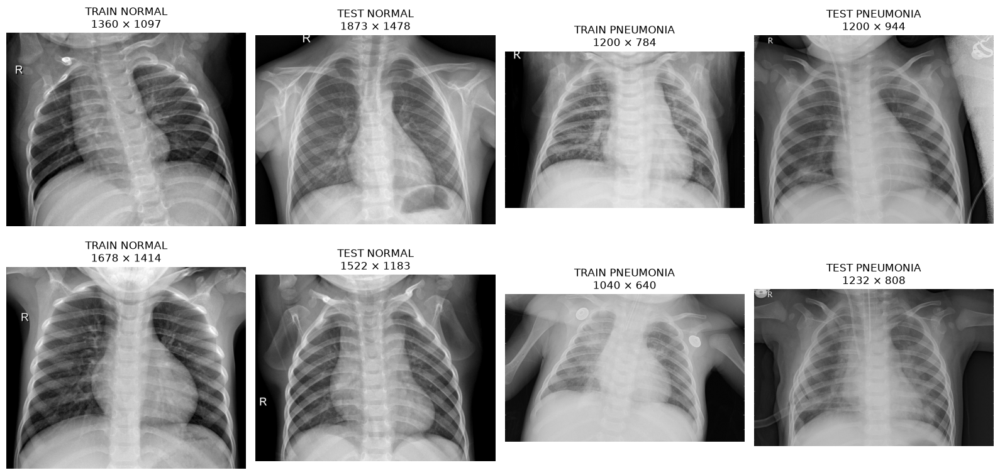

In [38]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

random.seed(42)

examples = [
    ("TRAIN NORMAL", Path("data/raw/chest_xray/train/NORMAL")),
    ("TEST NORMAL", Path("data/raw/chest_xray/test/NORMAL")),
    ("TRAIN PNEUMONIA", Path("data/raw/chest_xray/train/PNEUMONIA")),
    ("TEST PNEUMONIA", Path("data/raw/chest_xray/test/PNEUMONIA")),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, (title, folder) in enumerate(examples):
    paths = [
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    chosen = random.sample(paths, min(2, len(paths)))

    for row, path in enumerate(chosen):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")
            axes[row, col].set_title(
                f"{title}\n{img.width} × {img.height}"
            )
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [39]:
print("TRAIN TRANSFORM:")
print(train_transform)

print("\nVALIDATION TRANSFORM:")
print(val_transform)

print("\nTEST TRANSFORM:")
print(test_transform)

TRAIN TRANSFORM:
Compose(
    ToTensor()
)

VALIDATION TRANSFORM:
Compose(
    ToTensor()
)

TEST TRANSFORM:
Compose(
    ToTensor()
)


In [40]:
print("Train and validation transforms identical:",
      train_transform == val_transform)

print("Validation and test transforms identical:",
      val_transform == test_transform)

Train and validation transforms identical: False
Validation and test transforms identical: True


In [41]:
from pathlib import Path
from PIL import Image
import numpy as np

def image_pixel_stats(folder, limit=None):
    paths = sorted([
        p for p in Path(folder).iterdir()
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    if limit:
        paths = paths[:limit]

    means, stds = [], []

    for path in paths:
        with Image.open(path) as img:
            arr = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
            means.append(arr.mean())
            stds.append(arr.std())

    return {
        "count": len(paths),
        "mean_pixel_mean": float(np.mean(means)),
        "mean_pixel_std": float(np.mean(stds))
    }

for name, folder in [
    ("TRAIN NORMAL", "data/raw/chest_xray/train/NORMAL"),
    ("TEST NORMAL", "data/raw/chest_xray/test/NORMAL"),
    ("TRAIN PNEUMONIA", "data/raw/chest_xray/train/PNEUMONIA"),
    ("TEST PNEUMONIA", "data/raw/chest_xray/test/PNEUMONIA"),
]:
    print(name, image_pixel_stats(folder))

TRAIN NORMAL {'count': 1341, 'mean_pixel_mean': 0.47990715503692627, 'mean_pixel_std': 0.24092508852481842}
TEST NORMAL {'count': 234, 'mean_pixel_mean': 0.48656249046325684, 'mean_pixel_std': 0.23597879707813263}
TRAIN PNEUMONIA {'count': 3875, 'mean_pixel_mean': 0.48313671350479126, 'mean_pixel_std': 0.21702642738819122}
TEST PNEUMONIA {'count': 390, 'mean_pixel_mean': 0.4675520360469818, 'mean_pixel_std': 0.21947796642780304}


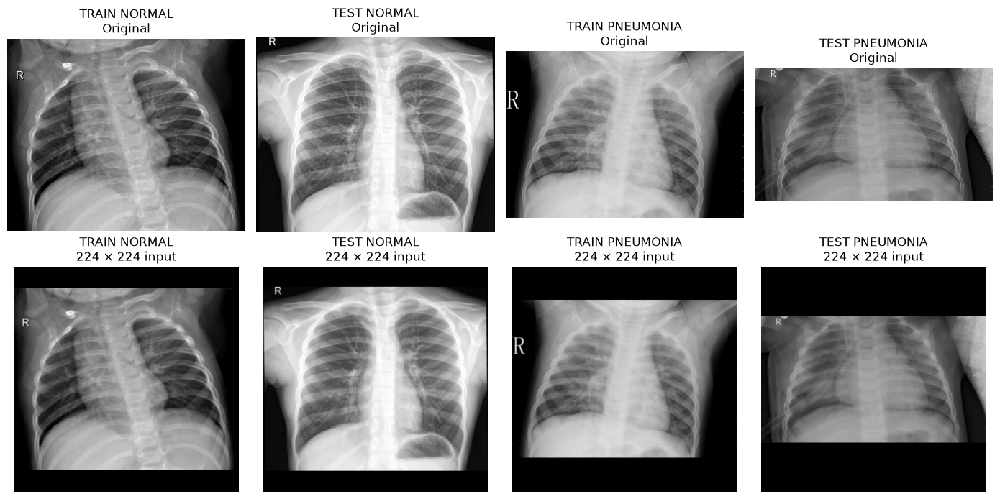

In [42]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

random.seed(42)

examples = [
    ("TRAIN NORMAL", Path("data/raw/chest_xray/train/NORMAL")),
    ("TEST NORMAL", Path("data/raw/chest_xray/test/NORMAL")),
    ("TRAIN PNEUMONIA", Path("data/raw/chest_xray/train/PNEUMONIA")),
    ("TEST PNEUMONIA", Path("data/raw/chest_xray/test/PNEUMONIA")),
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, (title, folder) in enumerate(examples):
    paths = sorted([
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    path = random.choice(paths)

    with Image.open(path) as img:
        original = img.convert("L")

        # Apply the same fixed preprocessing used for validation/test.
        processed = test_transform(original)
        processed = processed.squeeze(0).numpy()

    axes[0, col].imshow(original, cmap="gray")
    axes[0, col].set_title(f"{title}\nOriginal")
    axes[0, col].axis("off")

    axes[1, col].imshow(processed, cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title(f"{title}\n224 × 224 input")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

In [43]:
from PIL import Image
from torch.utils.data import DataLoader
import numpy as np
import torch

# Build a second test transform with grey padding.
gray_padding_transform = transforms.Compose([
    ResizeWithPadding(size=224, fill=40),
    transforms.ToTensor()
])

gray_test_dataset = ChestXrayTestDataset(
    "data/raw/chest_xray/test",
    gray_padding_transform
)

gray_test_loader = DataLoader(
    gray_test_dataset,
    batch_size=32,
    shuffle=False
)

gray_test_probs = []
gray_test_true = []

random_padding_model.eval()

with torch.no_grad():
    for images, labels in gray_test_loader:
        images = images.to(device)
        logits = random_padding_model(images)

        probs = torch.sigmoid(logits).view(-1).cpu().numpy()

        gray_test_probs.extend(probs.tolist())
        gray_test_true.extend(labels.numpy().astype(int).tolist())

gray_test_probs = np.array(gray_test_probs)
gray_test_true = np.array(gray_test_true)

# Use the same threshold for a fair comparison.
threshold = 0.30
gray_preds = (gray_test_probs >= threshold).astype(int)

print("Grey-padding ROC-AUC:",
      round(roc_auc_score(gray_test_true, gray_test_probs), 4))
print("Grey-padding accuracy:",
      round(accuracy_score(gray_test_true, gray_preds), 4))
print("\nGrey-padding confusion matrix:")
print(confusion_matrix(gray_test_true, gray_preds))

print("\nMean absolute probability change:",
      round(float(np.mean(np.abs(gray_test_probs - test_probs))), 4))

Grey-padding ROC-AUC: 0.9442
Grey-padding accuracy: 0.7147

Grey-padding confusion matrix:
[[ 57 177]
 [  1 389]]

Mean absolute probability change: 0.0385


In [44]:
import pandas as pd
import numpy as np

def probability_summary(name, labels, probabilities):
    rows = []

    for label, class_name in [(0, "NORMAL"), (1, "PNEUMONIA")]:
        scores = probabilities[labels == label]

        rows.append({
            "Experiment": name,
            "Class": class_name,
            "Median probability": np.median(scores),
            "10th percentile": np.percentile(scores, 10),
            "90th percentile": np.percentile(scores, 90),
        })

    return rows

summary = []

summary += probability_summary(
    "Black padding", test_true, test_probs
)
summary += probability_summary(
    "Grey padding", gray_test_true, gray_test_probs
)

pd.DataFrame(summary).round(4)

,Experiment,Class,Median probability,10th percentile,90th percentile
0,Black padding,NORMAL,0.6676,0.0263,0.9971
1,Black padding,PNEUMONIA,0.9998,0.9824,1.0000
2,Grey padding,NORMAL,0.8289,0.0504,0.9985
3,Grey padding,PNEUMONIA,0.9999,0.9944,1.0000


In [45]:
import pandas as pd
from pathlib import Path

test_paths = test_dataset.samples

normal_errors = []

for i, (path, label) in enumerate(test_paths):
    if label == 0:
        normal_errors.append({
            "path": str(path),
            "probability": float(test_probs[i]),
            "predicted_class": (
                "PNEUMONIA" if test_probs[i] >= 0.30 else "NORMAL"
            )
        })

normal_errors_df = pd.DataFrame(normal_errors)

print("NORMAL test images:", len(normal_errors_df))
print(
    "Misclassified at threshold 0.30:",
    (normal_errors_df["predicted_class"] == "PNEUMONIA").sum()
)

print("\n10 NORMAL images with highest pneumonia probabilities:")
display(
    normal_errors_df
    .sort_values("probability", ascending=False)
    .head(10)
)

NORMAL test images: 234
Misclassified at threshold 0.30: 161

10 NORMAL images with highest pneumonia probabilities:


,path,probability,predicted_class
140,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-024...,0.999691,PNEUMONIA
123,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-020...,0.999450,PNEUMONIA
143,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-025...,0.999433,PNEUMONIA
121,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-019...,0.999260,PNEUMONIA
146,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-026...,0.999245,PNEUMONIA
49,data\raw\chest_xray\test\NORMAL\IM-0081-0001.jpeg,0.999211,PNEUMONIA
129,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-021...,0.999209,PNEUMONIA
136,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-023...,0.999093,PNEUMONIA
126,data\raw\chest_xray\test\NORMAL\NORMAL2-IM-021...,0.998882,PNEUMONIA
66,data\raw\chest_xray\test\NORMAL\IM-0109-0001.jpeg,0.998806,PNEUMONIA


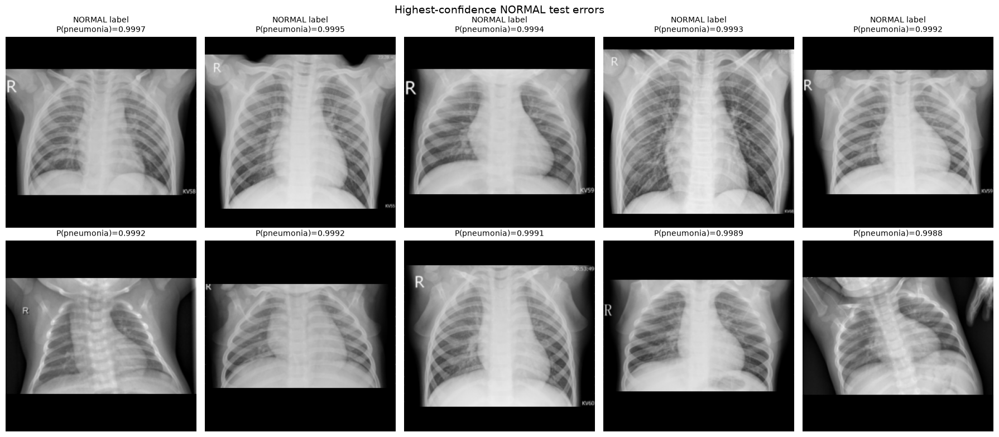

In [46]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

hardest_normal = (
    normal_errors_df
    .sort_values("probability", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, (_, row) in enumerate(hardest_normal.iterrows()):
    path = Path(row["path"])

    with Image.open(path) as img:
        image = img.convert("L")

    processed = test_transform(image).squeeze(0).numpy()

    ax = axes.flat[i]
    ax.imshow(processed, cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"NORMAL label\nP(pneumonia)={row['probability']:.4f}",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "Highest-confidence NORMAL test errors",
    fontsize=14
)
plt.tight_layout()
plt.show()

In [47]:
from pathlib import Path

for folder in ["src", "reports", "figures", "outputs"]:
    path = Path(folder)
    print(f"\n{folder}/ exists:", path.exists())

    if path.exists():
        for item in sorted(path.iterdir()):
            print("  ", item.name)


src/ exists: True
   __init__.py
   __pycache__
   dataset.py
   eda.py
   model.py

reports/ exists: True
   figures
   gradcam_multi_image_analysis.csv
   gradcam_region_analysis.csv
   marker_sensitivity_top5.csv
   validation_threshold_results.csv

figures/ exists: False

outputs/ exists: False


In [48]:
from pathlib import Path
import pandas as pd

reports_dir = Path("reports")

for filename in [
    "gradcam_multi_image_analysis.csv",
    "gradcam_region_analysis.csv",
    "marker_sensitivity_top5.csv",
    "validation_threshold_results.csv",
]:
    path = reports_dir / filename

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df.head(10))
    else:
        print("File not found.")


gradcam_multi_image_analysis.csv
Shape: (5, 4)


,image,lung_activation_pct,other_image_activation_pct,padding_activation_pct
0,IM-0001-0001.jpeg,28.854174,58.116425,13.029398
1,IM-0003-0001.jpeg,22.539974,62.983967,14.476063
2,IM-0005-0001.jpeg,25.041597,70.936460,4.021942
3,IM-0006-0001.jpeg,29.342142,69.546814,1.111045
4,IM-0007-0001.jpeg,21.781115,76.384476,1.834407



gradcam_region_analysis.csv
Shape: (3, 4)


,region,activation_percent,sample_size,mask_type
0,Lung regions,28.85,1,Approximate manual polygon
1,Other image content,58.12,1,"Outside manual polygon, excluding padding"
2,Padding,13.03,1,Geometric padding mask



marker_sensitivity_top5.csv
Shape: (5, 4)


,image,original_probability,modified_probability,change
0,NORMAL2-IM-0246-0001.jpeg,0.999691,0.999691,-1.192093e-07
1,NORMAL2-IM-0201-0001.jpeg,0.999450,0.999450,1.192093e-07
2,NORMAL2-IM-0252-0001.jpeg,0.999433,0.999432,-2.384186e-07
3,NORMAL2-IM-0198-0001.jpeg,0.999260,0.999260,0.000000e+00
4,NORMAL2-IM-0267-0001.jpeg,0.999245,0.999245,0.000000e+00



validation_threshold_results.csv
Shape: (17, 6)


,threshold,accuracy,normal_recall,pneumonia_recall,pneumonia_precision,macro_f1
0,0.10,0.955939,0.850746,0.992268,0.950617,0.939681
1,0.15,0.966475,0.899254,0.989691,0.966038,0.955011
2,0.20,0.967433,0.910448,0.987113,0.969620,0.956577
3,0.25,0.970307,0.925373,0.985825,0.974522,0.960659
4,0.30,0.971264,0.932836,0.984536,0.976982,0.962070
5,0.35,0.970307,0.940299,0.980670,0.979408,0.961047
6,0.40,0.968391,0.944030,0.976804,0.980595,0.958736
7,0.45,0.968391,0.958955,0.971649,0.985621,0.959128
8,0.50,0.969349,0.962687,0.971649,0.986911,0.960413
9,0.55,0.966475,0.970149,0.965206,0.989432,0.957053


In [49]:
from pathlib import Path

notebook_path = Path("Untitled.ipynb")

if notebook_path.exists():
    import nbformat

    notebook = nbformat.read(notebook_path, as_version=4)

    keywords = [
        "gradcam",
        "lung_activation_pct",
        "marker_sensitivity",
        "gradcam_region_analysis"
    ]

    for i, cell in enumerate(notebook.cells):
        if cell.cell_type == "code":
            source = cell.source
            if any(word in source.lower() for word in keywords):
                print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
                print(source[:5000])
else:
    print("Untitled.ipynb not found in the current directory.")


========================= CELL 116 =========================

import matplotlib.pyplot as plt
import torch.nn.functional as F

# Calculate Grad-CAM from the captured feature maps and gradients
features = saved["features"]
gradients = saved["gradients"]

weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = torch.relu((weights * features).sum(dim=1, keepdim=True))

cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

heatmap = cam[0, 0].detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

# Prepare the preprocessed X-ray
image_array = test_transform(original_image).numpy().squeeze()

# Create the output folder
OUTPUT_DIR = PROJECT_DIR / "reports" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Plot the original, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_array, cmap="gray")
axes[0].set_title("Preprocessed X-ray")

axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1

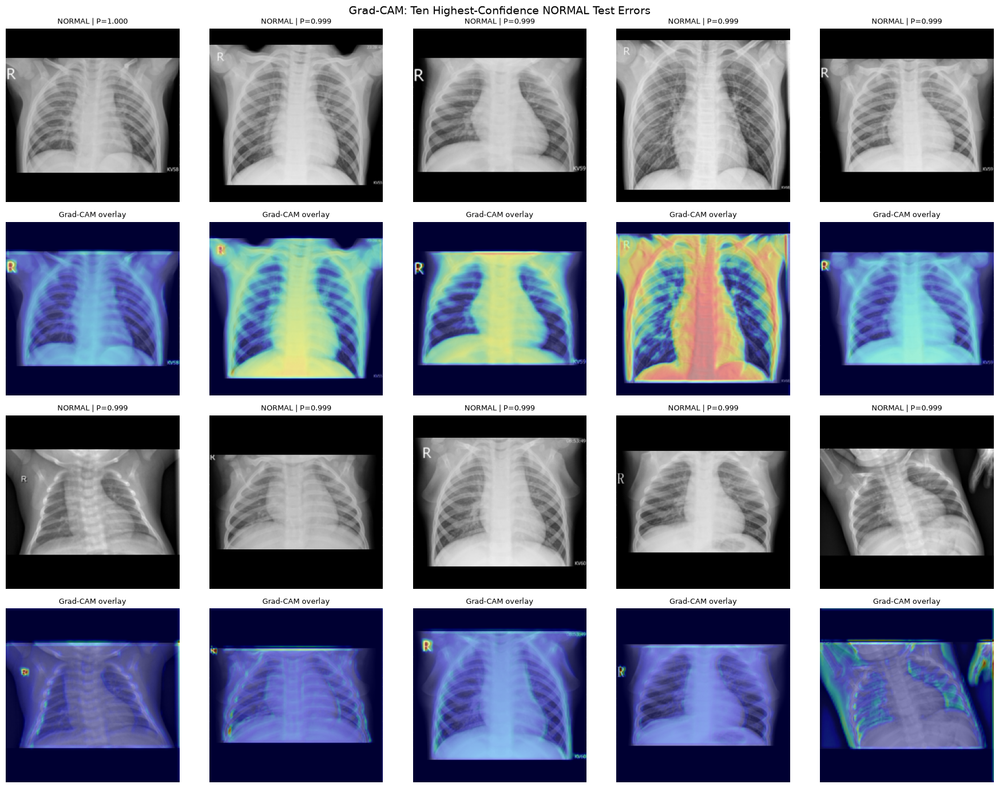

Saved: reports\figures\hardest_normal_gradcam.png


In [50]:

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from pathlib import Path

def generate_gradcam(model, input_tensor, target_layer):
    captured = {}

    def forward_hook(module, inputs, output):
        captured["features"] = output
        output.register_hook(
            lambda grad: captured.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        model.zero_grad(set_to_none=True)
        logits = model(input_tensor)
        logits[0, 0].backward()

        features = captured["features"]
        gradients = captured["gradients"]

        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * features).sum(dim=1, keepdim=True))

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam / (cam.max() + 1e-8)

        probability = torch.sigmoid(logits[0, 0]).item()

        return cam, probability

    finally:
        handle.remove()


# Use the existing model and last convolutional layer.
random_padding_model.eval()
device = next(random_padding_model.parameters()).device
target_layer = random_padding_model.features[3]

hardest_normal = (
    normal_errors_df
    .sort_values("probability", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(4, 5, figsize=(18, 14))

for i, row in hardest_normal.iterrows():
    path = Path(row["path"])

    with Image.open(path) as img:
        original = img.convert("L")
        input_tensor = test_transform(original).unsqueeze(0).to(device)

    cam, probability = generate_gradcam(
        random_padding_model,
        input_tensor,
        target_layer
    )

    xray = input_tensor[0, 0].detach().cpu().numpy()

    # First row pair: X-ray and heatmap overlay.
    r = (i // 5) * 2
    c = i % 5

    axes[r, c].imshow(xray, cmap="gray", vmin=0, vmax=1)
    axes[r, c].set_title(f"NORMAL | P={probability:.3f}", fontsize=9)
    axes[r, c].axis("off")

    axes[r + 1, c].imshow(xray, cmap="gray", vmin=0, vmax=1)
    axes[r + 1, c].imshow(
        cam, cmap="jet", alpha=0.4, vmin=0, vmax=1
    )
    axes[r + 1, c].set_title("Grad-CAM overlay", fontsize=9)
    axes[r + 1, c].axis("off")

plt.suptitle(
    "Grad-CAM: Ten Highest-Confidence NORMAL Test Errors",
    fontsize=14
)
plt.tight_layout()
plt.show()

# Save the figure for the project report.
output_dir = Path("reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "hardest_normal_gradcam.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
print("Saved:", figure_path)

plt.show()


In [52]:

from pathlib import Path
import pandas as pd
import numpy as np

def get_image_path(item):
    # Some datasets store entries as (path, label).
    if isinstance(item, (tuple, list)):
        item = item[0]
    return Path(item)

comparison_rows = []

for group, indices in selected.items():
    for idx in indices:
        image_path = get_image_path(test_paths[idx])

        comparison_rows.append({
            "group": group,
            "filename": image_path.name,
            "true_label": (
                "PNEUMONIA" if test_true[idx] == 1 else "NORMAL"
            ),
            "pneumonia_probability": round(
                float(test_probs[idx]), 5
            ),
            "predicted_label": (
                "PNEUMONIA" if test_preds[idx] == 1 else "NORMAL"
            ),
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)


,group,filename,true_label,pneumonia_probability,predicted_label
0,NORMAL false positive,NORMAL2-IM-0267-0001.jpeg,NORMAL,0.99925,PNEUMONIA
1,NORMAL false positive,NORMAL2-IM-0198-0001.jpeg,NORMAL,0.99926,PNEUMONIA
2,NORMAL false positive,NORMAL2-IM-0252-0001.jpeg,NORMAL,0.99943,PNEUMONIA
3,NORMAL false positive,NORMAL2-IM-0201-0001.jpeg,NORMAL,0.99945,PNEUMONIA
4,NORMAL false positive,NORMAL2-IM-0246-0001.jpeg,NORMAL,0.99969,PNEUMONIA
5,Correct NORMAL,NORMAL2-IM-0307-0001.jpeg,NORMAL,0.12256,NORMAL
6,Correct NORMAL,NORMAL2-IM-0086-0001.jpeg,NORMAL,0.00021,NORMAL
7,Correct NORMAL,NORMAL2-IM-0276-0001.jpeg,NORMAL,0.16967,NORMAL
8,Correct NORMAL,IM-0061-0001.jpeg,NORMAL,0.09139,NORMAL
9,Correct NORMAL,NORMAL2-IM-0374-0001.jpeg,NORMAL,0.23291,NORMAL


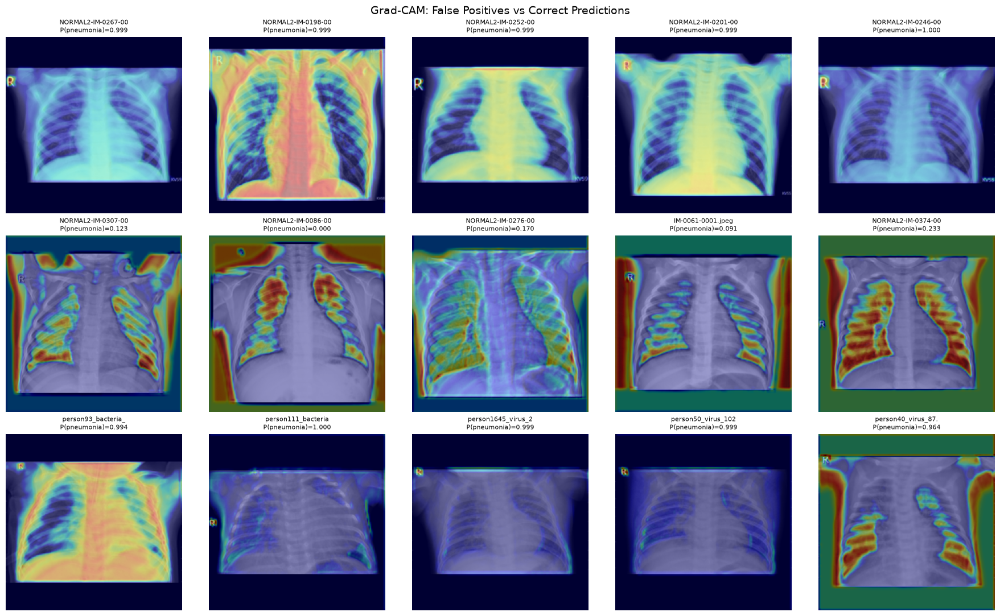

Saved: reports\figures\gradcam_error_vs_correct.png


In [55]:

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

group_order = [
    "NORMAL false positive",
    "Correct NORMAL",
    "Correct PNEUMONIA",
]

fig, axes = plt.subplots(3, 5, figsize=(18, 11))

for row_idx, group in enumerate(group_order):
    indices = selected[group]

    for col_idx, idx in enumerate(indices):
        path = get_image_path(test_paths[idx])

        with Image.open(path) as img:
            input_tensor = (
                test_transform(img.convert("L"))
                .unsqueeze(0)
                .to(device)
            )

        cam, probability = generate_gradcam(
            random_padding_model,
            input_tensor,
            target_layer
        )

        xray = input_tensor[0, 0].detach().cpu().numpy()

        ax = axes[row_idx, col_idx]
        ax.imshow(xray, cmap="gray", vmin=0, vmax=1)
        ax.imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
        ax.set_title(
            f"{path.name[:18]}\nP(pneumonia)={probability:.3f}",
            fontsize=8
        )
        ax.axis("off")

    axes[row_idx, 0].set_ylabel(
        group, fontsize=10, rotation=90, labelpad=12
    )

plt.suptitle(
    "Grad-CAM: False Positives vs Correct Predictions",
    fontsize=14
)
plt.tight_layout()

output_dir = Path("reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "gradcam_error_vs_correct.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", figure_path)


In [56]:

import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import torch

# Confirm the comparison groups and Grad-CAM function are available.
print("Selected groups:", list(selected.keys()))
print("Grad-CAM function:", generate_gradcam.__name__)
print("Target layer:", target_layer)

print("\nImages per group:")
for group, indices in selected.items():
    print(f"{group}: {len(indices)}")

print("\nReady for the quantitative activation comparison.")


Selected groups: ['NORMAL false positive', 'Correct NORMAL', 'Correct PNEUMONIA']
Grad-CAM function: generate_gradcam
Target layer: Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

Images per group:
NORMAL false positive: 5
Correct NORMAL: 5
Correct PNEUMONIA: 5

Ready for the quantitative activation comparison.


In [ ]:

import numpy as np
import pandas as pd
import torch
from PIL import Image
from pathlib import Path
from matplotlib.path import Path as PolygonPath

# Approximate lung-region polygons used in our earlier analysis.
left_lung = np.array([
    [47, 48], [57, 30], [75, 25], [91, 43],
    [96, 75], [91, 111], [83, 151], [67, 181],
    [49, 174], [43, 140], [40, 100]
])

right_lung = np.array([
    [111, 43], [127, 25], [145, 30], [158, 48],
    [164, 100], [160, 140], [151, 174], [133, 181],
    [117, 151], [110, 111], [108, 75]
])

yy, xx = np.mgrid[0:224, 0:224]
points = np.column_stack([xx.ravel(), yy.ravel()])

lung_mask = (
    PolygonPath(left_lung).contains_points(points).reshape(224, 224)
    | PolygonPath(right_lung).contains_points(points).reshape(224, 224)
)

random_padding_model.eval()
device = next(random_padding_model.parameters()).device
target_layer = random_padding_model.features[3]

activation_rows = []

for group, indices in selected.items():
    for idx in indices:
        image_path = get_image_path(test_paths[idx])

        with Image.open(image_path) as img:
            original = img.convert("L")
            input_tensor = (
                test_transform(original).unsqueeze(0).to(device)
            )

        # Generate Grad-CAM using the existing function.
        cam, probability = generate_gradcam(
            random_padding_model, input_tensor, target_layer
        )

        # Identify the padding for this original image.
        padding_mask = get_padding_mask(original, size=224)

        # Make sure the masks and heatmap use compatible dimensions.
        cam = np.asarray(cam, dtype=np.float64)
        cam = np.maximum(cam, 0)
        cam = cam / (cam.sum() + 1e-8)

        lung_region = lung_mask & ~padding_mask
        other_region = ~lung_mask & ~padding_mask

        activation_rows.append({
            "group": group,
            "filename": image_path.name,
            "true_label": (
                "PNEUMONIA" if test_true[idx] == 1 else "NORMAL"
            ),
            "pneumonia_probability": float(probability),
            "lung_activation_pct": 100 * cam[lung_region].sum(),
            "other_content_activation_pct": 100 * cam[other_region].sum(),
            "padding_activation_pct": 100 * cam[padding_mask].sum(),
        })

activation_df = pd.DataFrame(activation_rows)

print("Per-image activation percentages:")
display(activation_df.round(2))

print("\nGroup averages:")
summary_df = (
    activation_df.groupby("group")[
        [
            "lung_activation_pct",
            "other_content_activation_pct",
            "padding_activation_pct",
        ]
    ]
    .mean()
    .round(2)
)
display(summary_df)

output_dir = Path("reports")
output_dir.mkdir(parents=True, exist_ok=True)

activation_df.to_csv(
    output_dir / "gradcam_group_activation.csv", index=False
)
summary_df.to_csv(
    output_dir / "gradcam_group_activation_summary.csv"
)

print("Saved quantitative analysis to:", output_dir)


In [58]:

import numpy as np
from PIL import Image, ImageOps

def get_padding_mask(img, size=224):
    """
    Return True for pixels introduced by padding
    and False for pixels occupied by the resized image.
    """
    img = img.convert("L")

    resized = ImageOps.contain(
        img,
        (size, size),
        method=Image.Resampling.BILINEAR
    )

    mask = np.ones((size, size), dtype=bool)

    left = (size - resized.width) // 2
    top = (size - resized.height) // 2

    mask[
        top:top + resized.height,
        left:left + resized.width
    ] = False

    return mask

print("Padding-mask function restored!")


Padding-mask function restored!


In [59]:

from pathlib import Path
from PIL import Image

sample_path = get_image_path(test_paths[0])

with Image.open(sample_path) as img:
    padding_mask = get_padding_mask(img, size=224)

print("Mask shape:", padding_mask.shape)
print("Padding pixels:", int(padding_mask.sum()))
print("Image pixels:", int((~padding_mask).sum()))
print("Total pixels:", padding_mask.size)


Mask shape: (224, 224)
Padding pixels: 14560
Image pixels: 35616
Total pixels: 50176


In [1]:
print("Model:", "random_padding_model" in globals())
print("Grad-CAM function:", "generate_gradcam" in globals())
print("Padding mask:", "get_padding_mask" in globals())
print("Selected groups:", [name for name in globals() if "group" in name.lower()])

Model: False
Grad-CAM function: False
Padding mask: False
Selected groups: []


In [2]:
from pathlib import Path
import os

search_roots = [
    Path.cwd(),
    Path.home() / "OneDrive" / "Desktop",
    Path.home() / "Desktop",
    Path.home() / "OneDrive" / "Documents",
]

matches = []

for base in search_roots:
    if not base.exists():
        continue

    for checkpoint in base.glob(
        "**/models/best_chest_xray_cnn_random_padding.pth"
    ):
        project = checkpoint.parent.parent
        matches.append((project, checkpoint))

if not matches:
    print("Project checkpoint not found automatically.")
    print("Current notebook directory:", Path.cwd())
else:
    for i, (project, checkpoint) in enumerate(matches, 1):
        print(f"\nProject {i}: {project}")
        print("Checkpoint:", checkpoint.exists())
        print("src folder:", (project / "src").exists())
        print("reports folder:", (project / "reports").exists())

        for folder in project.glob("**/train"):
            if (folder / "NORMAL").exists() and (folder / "PNEUMONIA").exists():
                print("Training data:", folder)


Project 1: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai
Checkpoint: True
src folder: True
reports folder: True
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\train
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray\train
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\__MACOSX\chest_xray\train

Project 2: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai
Checkpoint: True
src folder: True
reports folder: True
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\train
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\chest_xray\train
Training data: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\data\raw\chest_xray\__MACOSX\chest_xray\train


In [3]:

# ============================================================
# CHEST-XRAY-AI: ONE-CELL NOTEBOOK RESTORATION
# Does NOT retrain or overwrite model checkpoints
# ============================================================

from pathlib import Path
import sys
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# -------------------------
# 1. PROJECT PATHS
# -------------------------

PROJECT_DIR = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

sys.path.insert(0, str(PROJECT_DIR))

TRAIN_DIR = (
    PROJECT_DIR / "data/raw/chest_xray/train"
)
TEST_DIR = (
    PROJECT_DIR / "data/raw/chest_xray/test"
)
CHECKPOINT_PATH = (
    PROJECT_DIR / "models/best_chest_xray_cnn_random_padding.pth"
)
REPORT_DIR = PROJECT_DIR / "reports"

assert TRAIN_DIR.exists(), f"Training folder missing: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Test folder missing: {TEST_DIR}"
assert CHECKPOINT_PATH.exists(), f"Checkpoint missing: {CHECKPOINT_PATH}"

for split_dir in [TRAIN_DIR, TEST_DIR]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        assert (split_dir / cls).exists(), f"Missing {cls} in {split_dir}"

print("Project paths verified.")

# -------------------------
# 2. DEVICE AND MODEL
# -------------------------

from src.model import ChestXrayCNN

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random_padding_model = ChestXrayCNN().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

if "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

random_padding_model.load_state_dict(state_dict)
random_padding_model.eval()

print("Model restored:", type(random_padding_model).__name__)
print("Device:", device)

# -------------------------
# 3. RECREATE PREPROCESSING
# -------------------------

class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = img.convert("L")

        resized = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L",
            (self.size, self.size),
            color=self.fill
        )

        left = (self.size - resized.width) // 2
        top = (self.size - resized.height) // 2

        canvas.paste(resized, (left, top))

        arr = np.asarray(canvas, dtype=np.float32) / 255.0

        return torch.from_numpy(arr).unsqueeze(0)


eval_transform = ResizeWithPadding(size=224, fill=0)

# -------------------------
# 4. REBUILD DATASETS
# -------------------------

full_train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Class mapping:", full_train_dataset.class_to_idx)
assert full_train_dataset.class_to_idx == {
    "NORMAL": 0,
    "PNEUMONIA": 1
}, "Unexpected class mapping. Stop and inspect before proceeding."

all_indices = np.arange(len(full_train_dataset))
all_labels = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

validation_dataset = Subset(
    full_train_dataset,
    val_indices
)

train_loader = DataLoader(
    Subset(full_train_dataset, train_indices),
    batch_size=32,
    shuffle=False
)

val_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training images:", len(train_indices))
print("Validation images:", len(validation_dataset))
print("Official test images:", len(test_dataset))

# -------------------------
# 5. PREDICTION FUNCTION
# -------------------------

@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()

    probabilities = []
    labels = []

    for images, targets in loader:
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits).view(-1)

        probabilities.extend(probs.cpu().numpy())
        labels.extend(targets.numpy())

    return np.array(probabilities), np.array(labels)


val_probs, val_labels = collect_predictions(
    random_padding_model,
    val_loader
)

test_probs, test_labels = collect_predictions(
    random_padding_model,
    test_loader
)

print("\nValidation predictions:", len(val_probs))
print("Test predictions:", len(test_probs))
print("Validation ROC-AUC:", round(
    roc_auc_score(val_labels, val_probs), 4
))
print("Test ROC-AUC:", round(
    roc_auc_score(test_labels, test_probs), 4
))

# -------------------------
# 6. RESTORE PADDING MASK
# -------------------------

def get_padding_mask(img, size=224):
    img = img.convert("L")

    resized = ImageOps.contain(
        img,
        (size, size),
        method=Image.Resampling.BILINEAR
    )

    mask = np.ones((size, size), dtype=bool)

    left = (size - resized.width) // 2
    top = (size - resized.height) // 2

    mask[
        top:top + resized.height,
        left:left + resized.width
    ] = False

    return mask


# -------------------------
# 7. RESTORE GRAD-CAM
# -------------------------

def generate_gradcam(model, input_tensor):
    model.eval()

    activations = []
    gradients = []

    target_layer = model.features[3]

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    try:
        model.zero_grad(set_to_none=True)

        x = input_tensor.unsqueeze(0).to(device)
        x.requires_grad_(True)

        output = model(x)
        output[:, 0].sum().backward()

        feature_maps = activations[0]
        grads = gradients[0]

        weights = grads.mean(dim=(2, 3), keepdim=True)

        cam = (weights * feature_maps).sum(dim=1)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        ).squeeze()

        cam = cam.detach().cpu().numpy()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam

    finally:
        forward_handle.remove()
        backward_handle.remove()


# -------------------------
# 8. SELECT THREE GROUPS
# -------------------------

test_paths = test_dataset.samples

test_pred_labels = (test_probs >= 0.30).astype(int)

normal_fp = [
    i for i in range(len(test_labels))
    if test_labels[i] == 0 and test_pred_labels[i] == 1
]

normal_correct = [
    i for i in range(len(test_labels))
    if test_labels[i] == 0 and test_pred_labels[i] == 0
]

pneumonia_correct = [
    i for i in range(len(test_labels))
    if test_labels[i] == 1 and test_pred_labels[i] == 1
]

selected_groups = {
    "NORMAL false positives": normal_fp[:5],
    "Correct NORMAL": normal_correct[:5],
    "Correct PNEUMONIA": pneumonia_correct[:5]
}

for group, indices in selected_groups.items():
    print(f"\n{group}: {len(indices)} images")
    for idx in indices:
        print(
            Path(test_paths[idx][0]).name,
            "Probability:",
            round(float(test_probs[idx]), 5)
        )

# -------------------------
# 9. RESTORATION SUMMARY
# -------------------------

print("\n" + "=" * 50)
print("RESTORATION COMPLETE")
print("=" * 50)

print("Model:", type(random_padding_model).__name__)
print("Grad-CAM function:", callable(generate_gradcam))
print("Padding mask:", callable(get_padding_mask))
print("Validation predictions:", len(val_probs))
print("Test predictions:", len(test_probs))
print("Selected groups:", {
    k: len(v) for k, v in selected_groups.items()
})


Project paths verified.
Model restored: ChestXrayCNN
Device: cpu
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Training images: 4172
Validation images: 1044
Official test images: 624

Validation predictions: 1044
Test predictions: 624
Validation ROC-AUC: 0.9948
Test ROC-AUC: 0.9429

NORMAL false positives: 5 images
IM-0001-0001.jpeg Probability: 0.88496
IM-0003-0001.jpeg Probability: 0.95714
IM-0005-0001.jpeg Probability: 0.99061
IM-0006-0001.jpeg Probability: 0.99844
IM-0007-0001.jpeg Probability: 0.97827

Correct NORMAL: 5 images
IM-0010-0001.jpeg Probability: 0.15198
IM-0013-0001.jpeg Probability: 0.2562
IM-0025-0001.jpeg Probability: 0.01201
IM-0035-0001.jpeg Probability: 0.18449
IM-0049-0001.jpeg Probability: 0.13249

Correct PNEUMONIA: 5 images
person100_bacteria_475.jpeg Probability: 0.98776
person100_bacteria_477.jpeg Probability: 0.99968
person100_bacteria_478.jpeg Probability: 1.0
person100_bacteria_479.jpeg Probability: 0.99991
person100_bacteria_480.jpeg Probability: 1.0

RE

In [4]:
print("Validation predictions:", len(val_probs) if "val_probs" in globals() else "Not created")
print("Test predictions:", len(test_probs) if "test_probs" in globals() else "Not created")
print("Grad-CAM:", callable(globals().get("generate_gradcam")))
print("Padding mask:", callable(globals().get("get_padding_mask")))
print("Selected groups:", globals().get("selected_groups", "Not created"))

Validation predictions: 1044
Test predictions: 624
Grad-CAM: True
Padding mask: True
Selected groups: {'NORMAL false positives': [0, 1, 2, 3, 4], 'Correct NORMAL': [6, 10, 18, 27, 35], 'Correct PNEUMONIA': [234, 235, 236, 237, 238]}


Processing: NORMAL false positives
Processing: Correct NORMAL
Processing: Correct PNEUMONIA

INDIVIDUAL IMAGE RESULTS


,group,image,true_label,predicted_label,pneumonia_probability,lung_proxy_activation_pct,other_content_activation_pct,padding_activation_pct
0,NORMAL false positives,IM-0001-0001.jpeg,0,1,0.88,36.669998,50.299999,13.030000
1,NORMAL false positives,IM-0003-0001.jpeg,0,1,0.96,37.549999,47.970001,14.480000
2,NORMAL false positives,IM-0005-0001.jpeg,0,1,0.99,39.880001,56.099998,4.020000
3,NORMAL false positives,IM-0006-0001.jpeg,0,1,1.00,54.369999,44.520000,1.110000
4,NORMAL false positives,IM-0007-0001.jpeg,0,1,0.98,44.630001,53.529999,1.830000
5,Correct NORMAL,IM-0010-0001.jpeg,0,0,0.15,31.930000,42.930000,25.139999
6,Correct NORMAL,IM-0013-0001.jpeg,0,0,0.26,31.980000,45.959999,22.059999
7,Correct NORMAL,IM-0025-0001.jpeg,0,0,0.01,29.750000,51.880001,18.370001
8,Correct NORMAL,IM-0035-0001.jpeg,0,0,0.18,25.709999,63.450001,10.840000
9,Correct NORMAL,IM-0049-0001.jpeg,0,0,0.13,18.420000,56.540001,25.040001



GROUP-LEVEL COMPARISON (mean ± standard deviation)


lung_proxy_activation_pct         \
                                            mean    std   
group                                                     
Correct NORMAL                         27.559999   5.71   
Correct PNEUMONIA                      41.930000  20.59   
NORMAL false positives                 42.619999   7.26   

                       other_content_activation_pct         \
                                               mean    std   
group                                                        
Correct NORMAL                            52.150002   8.22   
Correct PNEUMONIA                         40.950001  13.96   
NORMAL false positives                    50.490002   4.55   

                       padding_activation_pct         
                                         mean    std  
group                                                 
Correct NORMAL                      20.290001   5.96  
Correct PNEUMONIA                   17.120001  13.38  
NORMAL false positives               6.890000   6.37


Saved reports:
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_15_image_comparison.csv
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_group_summary.csv


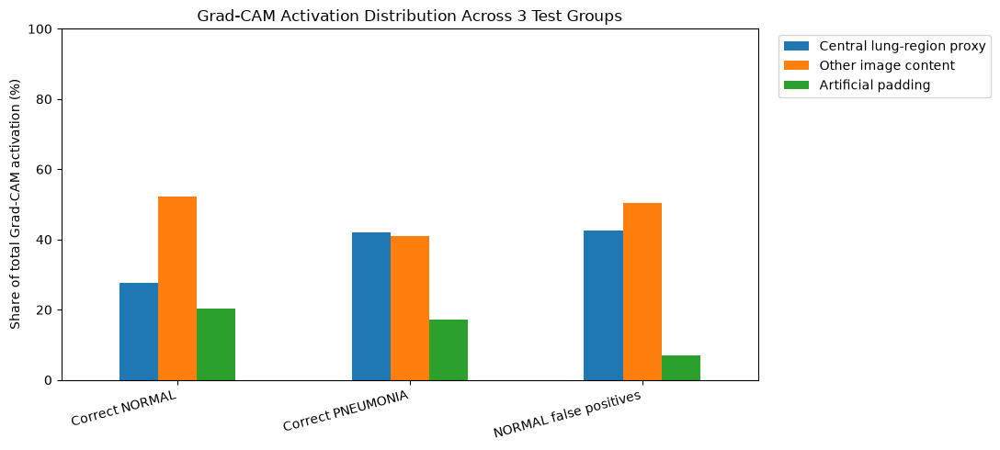

In [55]:

# ============================================================
# GRAD-CAM GROUP COMPARISON — 15 TEST IMAGES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Approximate central lung-field proxy.
# This is NOT a medically validated lung segmentation mask.
def make_lung_region_proxy(valid_mask):
    h, w = valid_mask.shape
    yy, xx = np.mgrid[0:h, 0:w]

    # Ellipse positioned within the central image area
    cx, cy = w * 0.50, h * 0.53
    rx, ry = w * 0.36, h * 0.40

    ellipse = ((xx - cx) / rx) ** 2 + ((yy - cy) / ry) ** 2 <= 1
    return ellipse & (~valid_mask)


# The padding mask is True where artificial padding exists.
# Invert it to get the actual image area.
results = []

for group_name, indices in selected_groups.items():

    print(f"Processing: {group_name}")

    for idx in indices:
        image_path, true_label = test_paths[idx]
        image = Image.open(image_path).convert("L")

        # Prepare model input and generate Grad-CAM
        input_tensor = eval_transform(image)
        cam = generate_gradcam(random_padding_model, input_tensor)

        # Identify padding and valid image regions
        padding_mask = get_padding_mask(image)
        valid_mask = ~padding_mask

        # Approximate central lung-field proxy
        lung_proxy = make_lung_region_proxy(padding_mask)

        # Remaining image content, excluding padding and proxy
        other_mask = valid_mask & (~lung_proxy)

        # Sum positive Grad-CAM activation in each region
        total_activation = float(np.sum(cam))

        if total_activation <= 0:
            print(f"Warning: zero activation for {image_path}")
            continue

        lung_share = np.sum(cam[lung_proxy]) / total_activation * 100
        other_share = np.sum(cam[other_mask]) / total_activation * 100
        padding_share = np.sum(cam[padding_mask]) / total_activation * 100

        probability = float(test_probs[idx])
        predicted_label = int(probability >= 0.30)

        results.append({
            "group": group_name,
            "image": Path(image_path).name,
            "true_label": int(true_label),
            "predicted_label": predicted_label,
            "pneumonia_probability": probability,
            "lung_proxy_activation_pct": lung_share,
            "other_content_activation_pct": other_share,
            "padding_activation_pct": padding_share
        })


# Create and save detailed results
gradcam_df = pd.DataFrame(results)

reports_dir = Path(PROJECT_DIR) / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

detail_path = reports_dir / "gradcam_15_image_comparison.csv"
gradcam_df.to_csv(detail_path, index=False)

# Group-level mean and standard deviation
summary_df = (
    gradcam_df.groupby("group")[
        [
            "lung_proxy_activation_pct",
            "other_content_activation_pct",
            "padding_activation_pct"
        ]
    ]
    .agg(["mean", "std"])
    .round(2)
)

summary_path = reports_dir / "gradcam_group_summary.csv"
summary_df.to_csv(summary_path)

print("\nINDIVIDUAL IMAGE RESULTS")
display(gradcam_df.round(2))

print("\nGROUP-LEVEL COMPARISON (mean ± standard deviation)")
display(summary_df)

print("\nSaved reports:")
print(detail_path)
print(summary_path)

# Visual comparison of mean activation shares
plot_df = (
    gradcam_df.groupby("group")[
        [
            "lung_proxy_activation_pct",
            "other_content_activation_pct",
            "padding_activation_pct"
        ]
    ]
    .mean()
)

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 100),
    ylabel="Share of total Grad-CAM activation (%)",
    title="Grad-CAM Activation Distribution Across 3 Test Groups"
)

ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(
    ["Central lung-region proxy", "Other image content", "Artificial padding"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


Processing: NORMAL false positives
Processing: Correct NORMAL
Processing: Correct PNEUMONIA

CORRECTED INDIVIDUAL RESULTS


,group,image,true_label,predicted_label,pneumonia_probability,lung_proxy_activation_pct,other_content_activation_pct,padding_activation_pct
0,NORMAL false positives,IM-0001-0001.jpeg,0,1,0.88,36.67,50.30,13.03
1,NORMAL false positives,IM-0003-0001.jpeg,0,1,0.96,37.55,47.97,14.48
2,NORMAL false positives,IM-0005-0001.jpeg,0,1,0.99,39.88,56.10,4.02
3,NORMAL false positives,IM-0006-0001.jpeg,0,1,1.00,54.37,44.52,1.11
4,NORMAL false positives,IM-0007-0001.jpeg,0,1,0.98,44.63,53.53,1.83
5,Correct NORMAL,IM-0010-0001.jpeg,0,0,0.15,31.93,42.93,25.14
6,Correct NORMAL,IM-0013-0001.jpeg,0,0,0.26,31.98,45.96,22.06
7,Correct NORMAL,IM-0025-0001.jpeg,0,0,0.01,29.75,51.88,18.37
8,Correct NORMAL,IM-0035-0001.jpeg,0,0,0.18,25.71,63.45,10.84
9,Correct NORMAL,IM-0049-0001.jpeg,0,0,0.13,18.42,56.54,25.04



CORRECTED GROUP SUMMARY


lung_proxy_activation_pct         \
                                            mean    std   
group                                                     
Correct NORMAL                             27.56   5.71   
Correct PNEUMONIA                          41.93  20.59   
NORMAL false positives                     42.62   7.26   

                       other_content_activation_pct         \
                                               mean    std   
group                                                        
Correct NORMAL                                52.15   8.22   
Correct PNEUMONIA                             40.95  13.96   
NORMAL false positives                        50.49   4.55   

                       padding_activation_pct         
                                         mean    std  
group                                                 
Correct NORMAL                          20.29   5.96  
Correct PNEUMONIA                       17.12  13.38  
NORMAL false positives                   6.89   6.37


Activation percentage check:
Minimum: 100.0
Maximum: 100.0


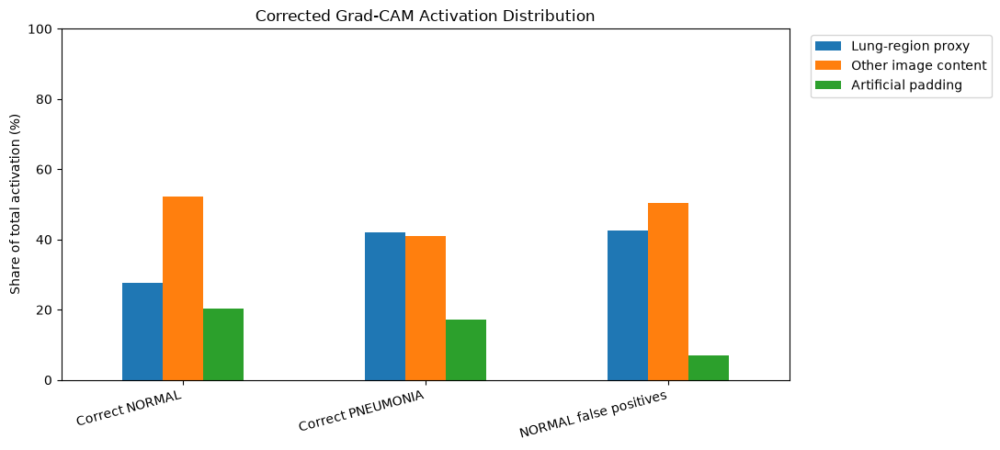


Corrected CSV reports saved in: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports


In [6]:

# ============================================================
# CORRECTED GRAD-CAM ANALYSIS — 15 TEST IMAGES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

def make_lung_region_proxy(valid_mask):
    h, w = valid_mask.shape
    yy, xx = np.mgrid[0:h, 0:w]

    cx, cy = w * 0.50, h * 0.53
    rx, ry = w * 0.36, h * 0.40

    ellipse = ((xx - cx) / rx)**2 + ((yy - cy) / ry)**2 <= 1

    # Correct: approximate lung region must be inside actual image
    return ellipse & valid_mask


results = []

for group_name, indices in selected_groups.items():
    print("Processing:", group_name)

    for idx in indices:
        image_path, true_label = test_paths[idx]
        image = Image.open(image_path).convert("L")

        tensor = eval_transform(image)
        cam = generate_gradcam(random_padding_model, tensor)

        padding_mask = get_padding_mask(image)
        valid_mask = ~padding_mask

        lung_mask = make_lung_region_proxy(valid_mask)
        other_mask = valid_mask & (~lung_mask)

        total = float(cam.sum())

        if total <= 0:
            print("Skipping zero activation:", image_path)
            continue

        lung_pct = float(cam[lung_mask].sum() / total * 100)
        other_pct = float(cam[other_mask].sum() / total * 100)
        padding_pct = float(cam[padding_mask].sum() / total * 100)

        probability = float(test_probs[idx])

        results.append({
            "group": group_name,
            "image": Path(image_path).name,
            "true_label": int(true_label),
            "predicted_label": int(probability >= 0.30),
            "pneumonia_probability": probability,
            "lung_proxy_activation_pct": lung_pct,
            "other_content_activation_pct": other_pct,
            "padding_activation_pct": padding_pct
        })


gradcam_df = pd.DataFrame(results)

reports_dir = Path(PROJECT_DIR) / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

gradcam_df.to_csv(
    reports_dir / "gradcam_15_image_comparison.csv",
    index=False
)

summary_df = gradcam_df.groupby("group")[
    [
        "lung_proxy_activation_pct",
        "other_content_activation_pct",
        "padding_activation_pct"
    ]
].agg(["mean", "std"]).round(2)

summary_df.to_csv(reports_dir / "gradcam_group_summary.csv")

print("\nCORRECTED INDIVIDUAL RESULTS")
display(gradcam_df.round(2))

print("\nCORRECTED GROUP SUMMARY")
display(summary_df)

# Check that the three regions partition total activation
row_sums = gradcam_df[
    [
        "lung_proxy_activation_pct",
        "other_content_activation_pct",
        "padding_activation_pct"
    ]
].sum(axis=1)

print("\nActivation percentage check:")
print("Minimum:", round(row_sums.min(), 2))
print("Maximum:", round(row_sums.max(), 2))

plot_df = gradcam_df.groupby("group")[
    [
        "lung_proxy_activation_pct",
        "other_content_activation_pct",
        "padding_activation_pct"
    ]
].mean()

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 100),
    title="Corrected Grad-CAM Activation Distribution",
    ylabel="Share of total activation (%)"
)

ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(
    ["Lung-region proxy", "Other image content", "Artificial padding"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

print("\nCorrected CSV reports saved in:", reports_dir)


Generating: NORMAL false positives


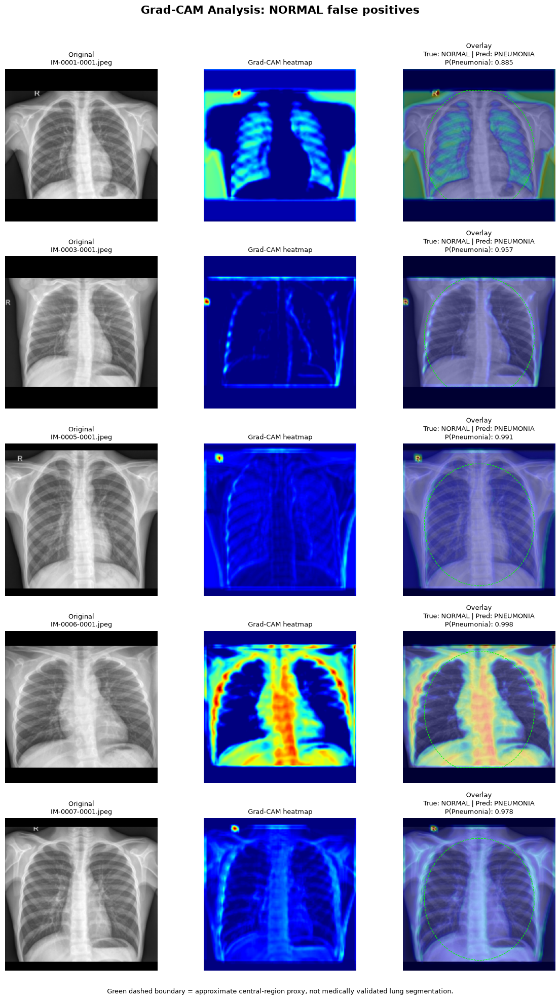

Generating: Correct NORMAL


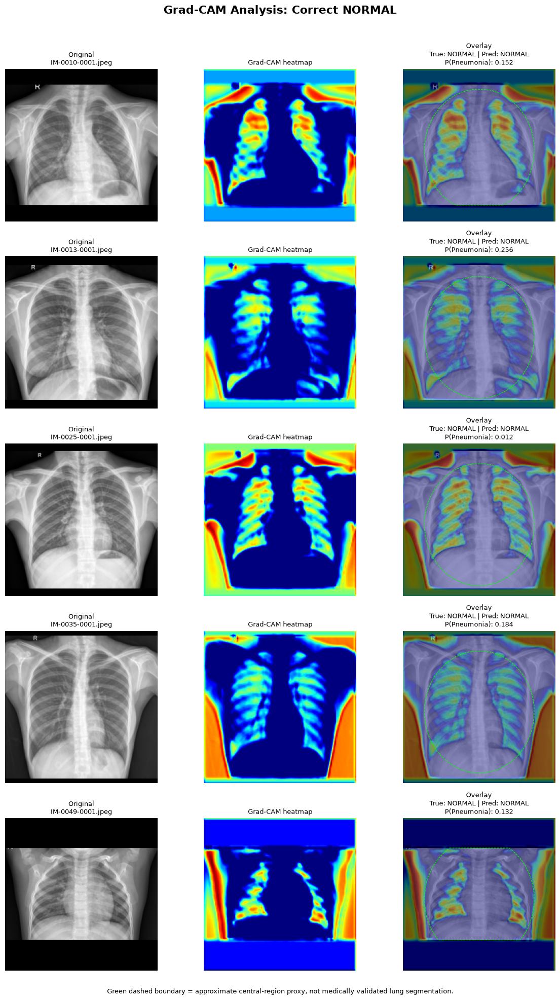

Generating: Correct PNEUMONIA


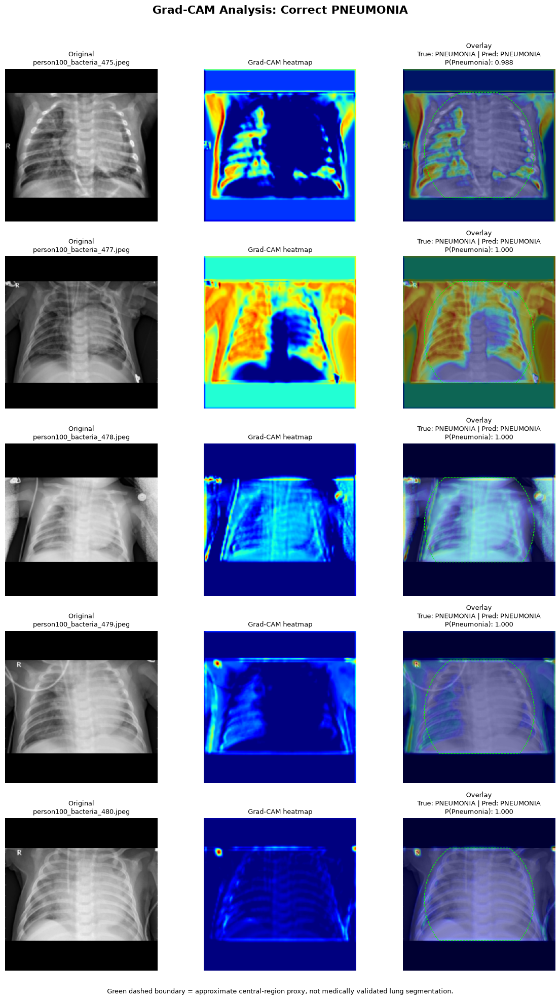


VISUAL REPORT COMPLETED
Output folder: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations
Combined PDF: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations\gradcam_complete_visual_report.pdf

Generated PNG reports:
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations\normal_false_positives.png
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations\correct_normal.png
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations\correct_pneumonia.png


In [7]:

# ============================================================
# VISUAL GRAD-CAM REPORT — ALL 15 SELECTED TEST IMAGES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages

output_dir = Path(PROJECT_DIR) / "reports" / "gradcam_visualizations"
output_dir.mkdir(parents=True, exist_ok=True)

pdf_path = output_dir / "gradcam_complete_visual_report.pdf"

group_files = {
    "NORMAL false positives": "normal_false_positives.png",
    "Correct NORMAL": "correct_normal.png",
    "Correct PNEUMONIA": "correct_pneumonia.png"
}

with PdfPages(pdf_path) as pdf:

    for group_name, indices in selected_groups.items():

        print("Generating:", group_name)

        fig, axes = plt.subplots(
            len(indices), 3,
            figsize=(12, 4 * len(indices))
        )

        fig.suptitle(
            f"Grad-CAM Analysis: {group_name}",
            fontsize=16,
            fontweight="bold"
        )

        for row, idx in enumerate(indices):

            image_path, true_label = test_paths[idx]
            image = Image.open(image_path).convert("L")

            # Model input and matching display image
            tensor = eval_transform(image)
            display_image = tensor.squeeze().cpu().numpy()

            # Generate Grad-CAM
            cam = generate_gradcam(random_padding_model, tensor)

            # Approximate lung boundary and padding
            padding_mask = get_padding_mask(image)
            valid_mask = ~padding_mask
            lung_mask = make_lung_region_proxy(valid_mask)

            probability = float(test_probs[idx])
            predicted = int(probability >= 0.30)

            true_name = "PNEUMONIA" if true_label == 1 else "NORMAL"
            pred_name = "PNEUMONIA" if predicted == 1 else "NORMAL"

            filename = Path(image_path).name

            # 1. Original X-ray
            axes[row, 0].imshow(display_image, cmap="gray")
            axes[row, 0].set_title(
                f"Original\n{filename}",
                fontsize=9
            )

            # 2. Grad-CAM heatmap
            axes[row, 1].imshow(cam, cmap="jet", vmin=0, vmax=1)
            axes[row, 1].set_title("Grad-CAM heatmap", fontsize=9)

            # 3. Overlay with approximate lung boundary
            axes[row, 2].imshow(display_image, cmap="gray")
            axes[row, 2].imshow(
                cam,
                cmap="jet",
                alpha=0.40,
                vmin=0,
                vmax=1
            )

            # Dashed contour: approximate region, NOT segmentation
            axes[row, 2].contour(
                lung_mask.astype(float),
                levels=[0.5],
                colors="lime",
                linewidths=0.8,
                linestyles="dashed"
            )

            axes[row, 2].set_title(
                f"Overlay\nTrue: {true_name} | Pred: {pred_name}\n"
                f"P(Pneumonia): {probability:.3f}",
                fontsize=9
            )

            for col in range(3):
                axes[row, col].axis("off")

        fig.text(
            0.5, 0.005,
            "Green dashed boundary = approximate central-region proxy, "
            "not medically validated lung segmentation.",
            ha="center",
            fontsize=9
        )

        plt.tight_layout(rect=[0, 0.02, 1, 0.97])

        # Save group PNG
        png_path = output_dir / group_files[group_name]
        fig.savefig(png_path, dpi=160, bbox_inches="tight")

        # Add group page to combined PDF
        pdf.savefig(fig, bbox_inches="tight")

        plt.show()
        plt.close(fig)

print("\nVISUAL REPORT COMPLETED")
print("Output folder:", output_dir)
print("Combined PDF:", pdf_path)
print("\nGenerated PNG reports:")
for filename in group_files.values():
    print(output_dir / filename)


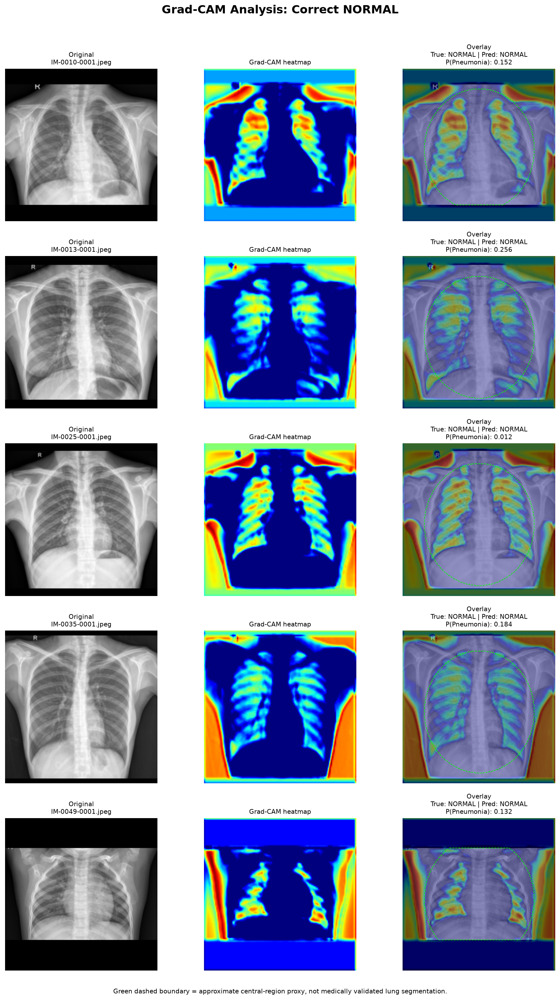

In [8]:
from PIL import Image
from IPython.display import display

report_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "gradcam_visualizations"
    / "correct_normal.png"
)

display(Image.open(report_path))

## 6. Image Corner Sensitivity Experiments

This section examines whether the CNN is sensitive to image corners and border regions.

Controlled image perturbations are used to study changes in prediction scores and identify possible reliance on non-lung image information.

In [9]:

# ============================================================
# CONTROLLED IMAGE-CORNER SENSITIVITY EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
import torch
from pathlib import Path

results = []

def mask_corner(tensor, corner, fraction_x=0.25, fraction_y=0.18):
    """
    Mask a corner using the median intensity of nearby pixels.
    Input tensor shape: [1, H, W].
    """
    modified = tensor.clone()
    _, h, w = modified.shape

    patch_h = int(h * fraction_y)
    patch_w = int(w * fraction_x)

    if corner == "upper_left":
        y0, y1 = 0, patch_h
        x0, x1 = 0, patch_w

        nearby = torch.cat([
            modified[:, y1:min(y1 + 8, h), x0:x1].flatten(),
            modified[:, y0:y1, x1:min(x1 + 8, w)].flatten()
        ])

    elif corner == "upper_right":
        y0, y1 = 0, patch_h
        x0, x1 = w - patch_w, w

        nearby = torch.cat([
            modified[:, y1:min(y1 + 8, h), x0:x1].flatten(),
            modified[:, y0:y1, max(0, x0 - 8):x0].flatten()
        ])

    else:
        raise ValueError("Unsupported corner")

    fill_value = nearby.median()
    modified[:, y0:y1, x0:x1] = fill_value

    return modified


def predict_probability(model, tensor):
    model.eval()
    with torch.no_grad():
        output = model(tensor.unsqueeze(0).to(device))
        return torch.sigmoid(output).item()


for group_name, indices in selected_groups.items():

    print("Testing:", group_name)

    for idx in indices:

        image_path, true_label = test_paths[idx]
        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        original_probability = predict_probability(
            random_padding_model, tensor
        )

        left_masked = mask_corner(tensor, "upper_left")
        left_probability = predict_probability(
            random_padding_model, left_masked
        )

        right_masked = mask_corner(tensor, "upper_right")
        right_probability = predict_probability(
            random_padding_model, right_masked
        )

        results.append({
            "group": group_name,
            "image": Path(image_path).name,
            "original_probability": original_probability,
            "upper_left_masked_probability": left_probability,
            "upper_right_masked_probability": right_probability,
            "left_probability_change": (
                left_probability - original_probability
            ),
            "right_probability_change": (
                right_probability - original_probability
            )
        })


sensitivity_df = pd.DataFrame(results)

# Save individual results
output_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "corner_sensitivity_analysis.csv"
)

sensitivity_df.to_csv(output_path, index=False)

print("\nINDIVIDUAL RESULTS")
display(sensitivity_df.round(4))

print("\nGROUP SUMMARY — MEAN ABSOLUTE PROBABILITY CHANGE")

summary = sensitivity_df.groupby("group").agg(
    left_mean_change=("left_probability_change", "mean"),
    left_mean_absolute_change=(
        "left_probability_change",
        lambda x: x.abs().mean()
    ),
    right_mean_change=("right_probability_change", "mean"),
    right_mean_absolute_change=(
        "right_probability_change",
        lambda x: x.abs().mean()
    )
).round(4)

display(summary)

print("\nSaved:", output_path)


Testing: NORMAL false positives
Testing: Correct NORMAL
Testing: Correct PNEUMONIA

INDIVIDUAL RESULTS


,group,image,original_probability,upper_left_masked_probability,upper_right_masked_probability,left_probability_change,right_probability_change
0,NORMAL false positives,IM-0001-0001.jpeg,0.8850,0.9437,0.8898,0.0588,0.0048
1,NORMAL false positives,IM-0003-0001.jpeg,0.9571,0.9360,0.9388,-0.0212,-0.0183
2,NORMAL false positives,IM-0005-0001.jpeg,0.9906,0.9932,0.9967,0.0025,0.0061
3,NORMAL false positives,IM-0006-0001.jpeg,0.9984,0.9983,0.9994,-0.0002,0.0010
4,NORMAL false positives,IM-0007-0001.jpeg,0.9783,0.9955,0.9839,0.0172,0.0056
5,Correct NORMAL,IM-0010-0001.jpeg,0.1520,0.3203,0.1682,0.1683,0.0162
6,Correct NORMAL,IM-0013-0001.jpeg,0.2562,0.3559,0.2183,0.0997,-0.0379
7,Correct NORMAL,IM-0025-0001.jpeg,0.0120,0.0211,0.0097,0.0091,-0.0023
8,Correct NORMAL,IM-0035-0001.jpeg,0.1845,0.3495,0.2733,0.1650,0.0888
9,Correct NORMAL,IM-0049-0001.jpeg,0.1325,0.1325,0.1325,0.0000,0.0000



GROUP SUMMARY — MEAN ABSOLUTE PROBABILITY CHANGE


,left_mean_change,left_mean_absolute_change,right_mean_change,right_mean_absolute_change
group,,,,
Correct NORMAL,0.0884,0.0884,0.0130,0.0290
Correct PNEUMONIA,-0.0001,0.0001,-0.0011,0.0011
NORMAL false positives,0.0114,0.0200,-0.0001,0.0072



Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\corner_sensitivity_analysis.csv


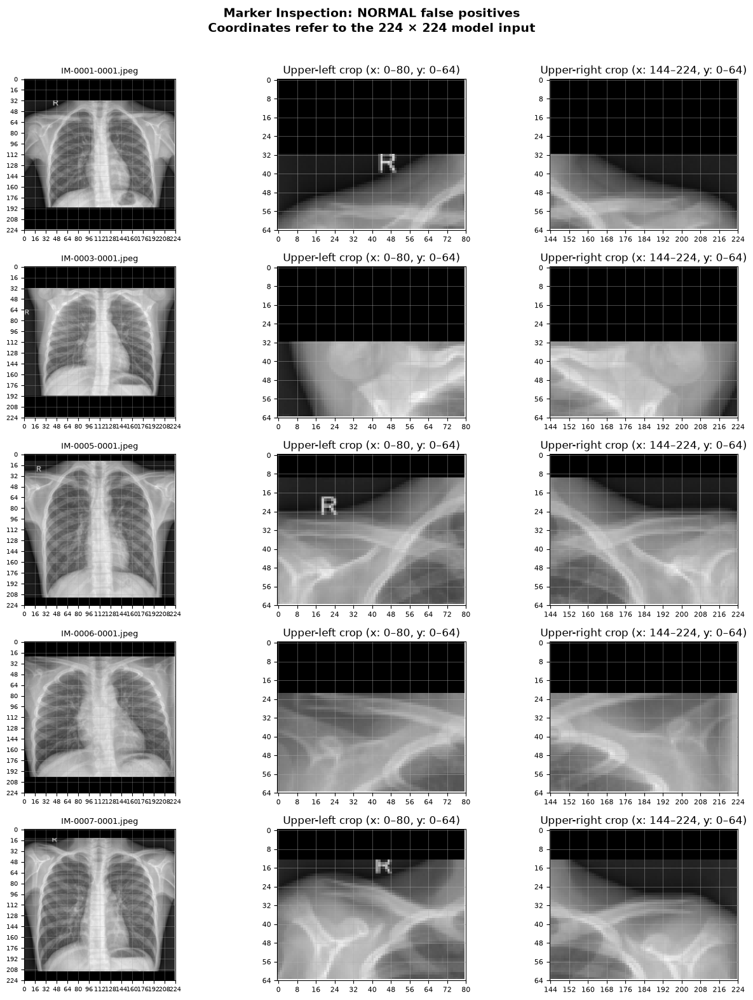

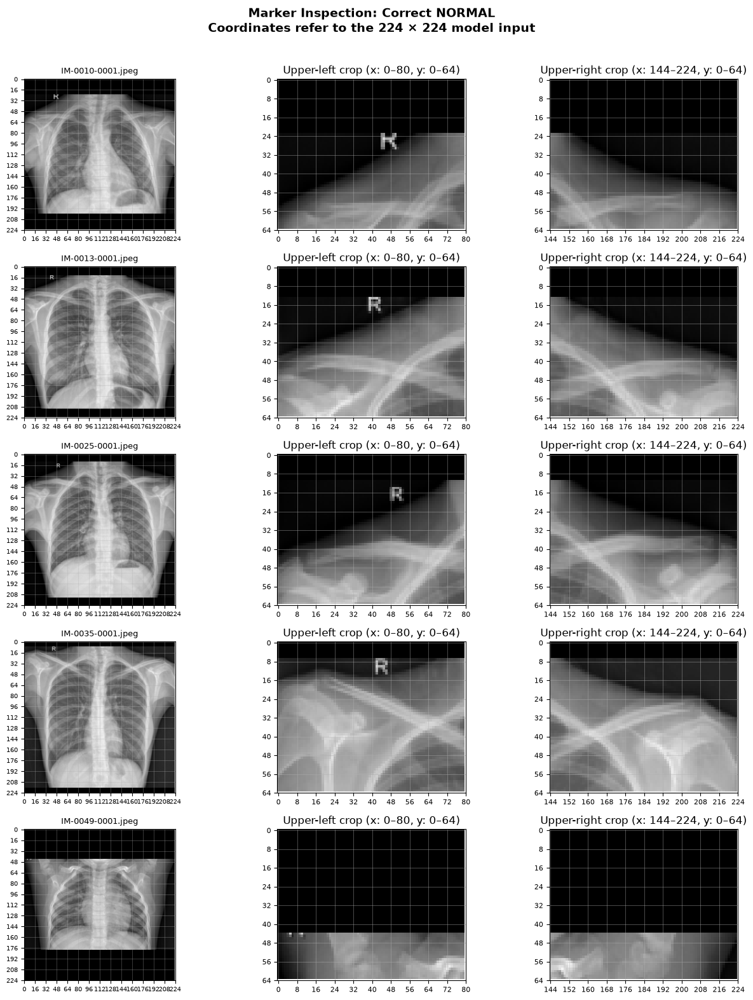

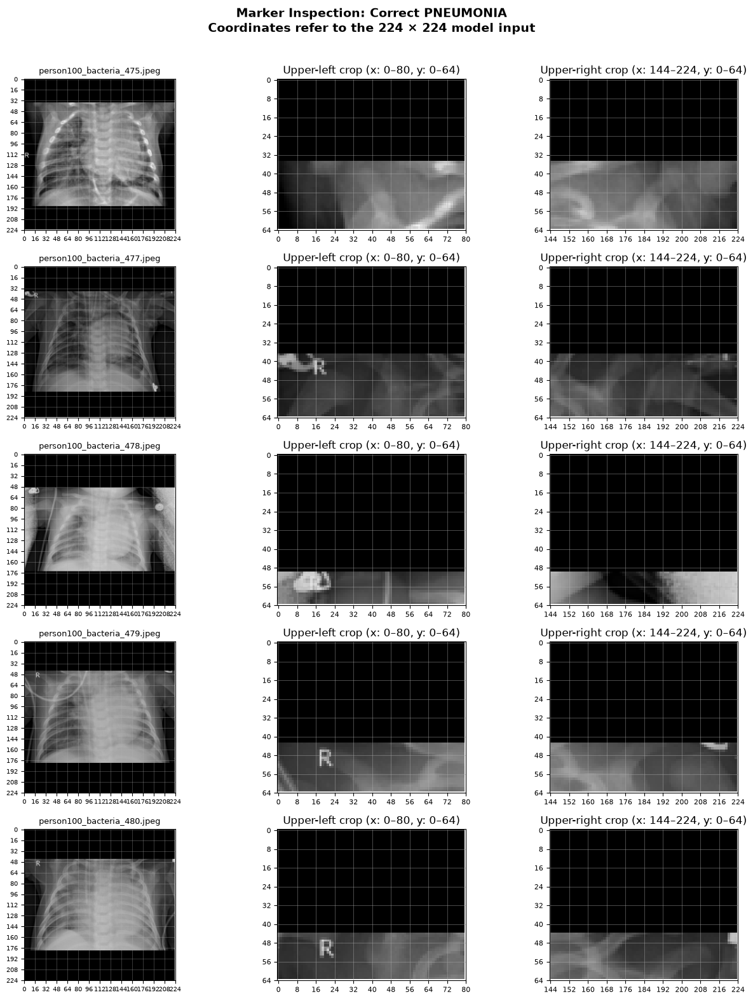

Marker inspection reports saved in: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations\marker_inspection


In [10]:

# ============================================================
# MARKER LOCATION INSPECTION — 15 SELECTED IMAGES
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

marker_dir = (
    Path(PROJECT_DIR)
    / "reports"
    / "gradcam_visualizations"
    / "marker_inspection"
)
marker_dir.mkdir(parents=True, exist_ok=True)

for group_name, indices in selected_groups.items():

    fig, axes = plt.subplots(
        len(indices), 3,
        figsize=(13, 3.2 * len(indices))
    )

    fig.suptitle(
        f"Marker Inspection: {group_name}\n"
        "Coordinates refer to the 224 × 224 model input",
        fontsize=14,
        fontweight="bold"
    )

    for row, idx in enumerate(indices):

        image_path, true_label = test_paths[idx]
        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)
        arr = tensor.squeeze().cpu().numpy()

        # Full image with coordinate grid
        axes[row, 0].imshow(arr, cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title(Path(image_path).name, fontsize=9)
        axes[row, 0].set_xticks(np.arange(0, 225, 16))
        axes[row, 0].set_yticks(np.arange(0, 225, 16))
        axes[row, 0].grid(alpha=0.45, linewidth=0.5)
        axes[row, 0].tick_params(labelsize=7)

        # Enlarged upper-left region
        axes[row, 1].imshow(
            arr[:64, :80],
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )
        axes[row, 1].set_title("Upper-left crop (x: 0–80, y: 0–64)")
        axes[row, 1].set_xticks(np.arange(0, 81, 8))
        axes[row, 1].set_yticks(np.arange(0, 65, 8))
        axes[row, 1].grid(alpha=0.5, linewidth=0.6)
        axes[row, 1].tick_params(labelsize=8)

        # Enlarged upper-right region
        axes[row, 2].imshow(
            arr[:64, 144:224],
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )
        axes[row, 2].set_title("Upper-right crop (x: 144–224, y: 0–64)")
        axes[row, 2].set_xticks(np.arange(0, 81, 8))
        axes[row, 2].set_xticklabels(np.arange(144, 225, 8))
        axes[row, 2].set_yticks(np.arange(0, 65, 8))
        axes[row, 2].grid(alpha=0.5, linewidth=0.6)
        axes[row, 2].tick_params(labelsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    filename = (
        group_name.lower().replace(" ", "_").replace("/", "_")
        + "_marker_coordinates.png"
    )

    fig.savefig(marker_dir / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Marker inspection reports saved in:", marker_dir)


Excluded ambiguous marker: IM-0006-0001.jpeg
Excluded ambiguous marker: IM-0049-0001.jpeg
Excluded ambiguous marker: person100_bacteria_478.jpeg

INDIVIDUAL MARKER EXPERIMENT RESULTS


,group,image,marker_box,control_box,original_probability,marker_masked_probability,control_masked_probability,marker_probability_change,control_probability_change,marker_absolute_change,control_absolute_change,marker_class_changed,control_class_changed
0,NORMAL false positives,IM-0001-0001.jpeg,"(42, 27, 56, 41)","(62, 27, 76, 41)",0.8850,0.9376,0.8830,0.0527,-0.0019,0.0527,0.0019,False,False
1,NORMAL false positives,IM-0003-0001.jpeg,"(0, 57, 10, 73)","(20, 57, 30, 73)",0.9571,0.9278,0.9554,-0.0294,-0.0018,0.0294,0.0018,False,False
2,NORMAL false positives,IM-0005-0001.jpeg,"(17, 14, 31, 29)","(37, 14, 51, 29)",0.9906,0.9883,0.9904,-0.0023,-0.0002,0.0023,0.0002,False,False
3,NORMAL false positives,IM-0007-0001.jpeg,"(47, 7, 61, 23)","(67, 7, 81, 23)",0.9783,0.9817,0.9783,0.0034,0.0001,0.0034,0.0001,False,False
4,Correct NORMAL,IM-0010-0001.jpeg,"(42, 17, 56, 31)","(62, 17, 76, 31)",0.1520,0.2783,0.1455,0.1263,-0.0065,0.1263,0.0065,False,False
5,Correct NORMAL,IM-0013-0001.jpeg,"(37, 7, 51, 22)","(57, 7, 71, 22)",0.2562,0.4407,0.2316,0.1845,-0.0246,0.1845,0.0246,True,False
6,Correct NORMAL,IM-0025-0001.jpeg,"(47, 7, 61, 23)","(67, 7, 81, 23)",0.0120,0.0242,0.0115,0.0122,-0.0005,0.0122,0.0005,False,False
7,Correct NORMAL,IM-0035-0001.jpeg,"(48, 0, 62, 15)","(68, 0, 82, 15)",0.1845,0.1810,0.1718,-0.0035,-0.0127,0.0035,0.0127,False,False
8,Correct PNEUMONIA,person100_bacteria_475.jpeg,"(0, 118, 10, 134)","(20, 118, 30, 134)",0.9878,0.9878,0.9882,0.0000,0.0004,0.0000,0.0004,False,False
9,Correct PNEUMONIA,person100_bacteria_477.jpeg,"(8, 34, 23, 49)","(28, 34, 43, 49)",0.9997,0.9988,0.9997,-0.0009,-0.0000,0.0009,0.0000,False,False



GROUP COMPARISON


,images_tested,marker_mean_abs_change,control_mean_abs_change,marker_class_flips,control_class_flips
group,,,,,
Correct NORMAL,4,0.0816,0.0111,1,0
Correct PNEUMONIA,4,0.0003,0.0001,0,0
NORMAL false positives,4,0.0219,0.0010,0,0



OVERALL COMPARISON
Marker mean absolute change: 0.0346
Control mean absolute change: 0.0041

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_only_vs_control.csv


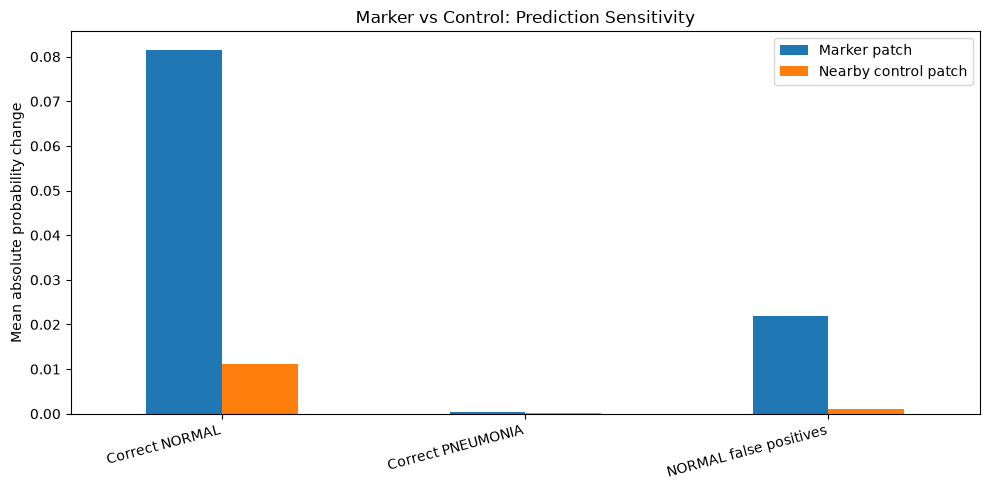

In [11]:

# ============================================================
# MARKER-ONLY OCCLUSION vs MATCHED CONTROL — 12 IMAGES
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# Manually estimated marker boxes:
# format = (x_start, y_start, x_end, y_end)
# Coordinates refer to the 224x224 preprocessed image.

marker_boxes = {
    "IM-0001-0001.jpeg": (42, 27, 56, 41),
    "IM-0003-0001.jpeg": (0, 57, 10, 73),
    "IM-0005-0001.jpeg": (17, 14, 31, 29),
    "IM-0007-0001.jpeg": (47, 7, 61, 23),

    "IM-0010-0001.jpeg": (42, 17, 56, 31),
    "IM-0013-0001.jpeg": (37, 7, 51, 22),
    "IM-0025-0001.jpeg": (47, 7, 61, 23),
    "IM-0035-0001.jpeg": (48, 0, 62, 15),

    "person100_bacteria_475.jpeg": (0, 118, 10, 134),
    "person100_bacteria_477.jpeg": (8, 34, 23, 49),
    "person100_bacteria_479.jpeg": (14, 46, 27, 62),
    "person100_bacteria_480.jpeg": (13, 55, 26, 70),
}

# Fill a selected patch using the median of a surrounding ring.
def mask_patch(tensor, box):
    modified = tensor.clone()
    _, h, w = modified.shape

    x0, y0, x1, y1 = box
    x0, x1 = max(0, x0), min(w, x1)
    y0, y1 = max(0, y0), min(h, y1)

    ring = torch.zeros((h, w), dtype=torch.bool)

    outer_x0 = max(0, x0 - 5)
    outer_x1 = min(w, x1 + 5)
    outer_y0 = max(0, y0 - 5)
    outer_y1 = min(h, y1 + 5)

    ring[outer_y0:outer_y1, outer_x0:outer_x1] = True
    ring[y0:y1, x0:x1] = False

    surrounding = modified[0][ring]

    if surrounding.numel() == 0:
        fill_value = modified.median()
    else:
        fill_value = surrounding.median()

    modified[:, y0:y1, x0:x1] = fill_value
    return modified


def make_control_box(marker_box, width=224):
    x0, y0, x1, y1 = marker_box

    # Shift the same-sized patch horizontally away from the marker.
    if x1 + 20 <= width:
        shift = 20
    else:
        shift = -20

    return (
        max(0, x0 + shift),
        y0,
        min(width, x1 + shift),
        y1
    )


def predict_probability(model, tensor):
    model.eval()
    with torch.no_grad():
        output = model(tensor.unsqueeze(0).to(device))
        return torch.sigmoid(output).item()


results = []

for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        # Skip images without a clearly identifiable letter marker.
        if filename not in marker_boxes:
            print("Excluded ambiguous marker:", filename)
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        marker_box = marker_boxes[filename]
        control_box = make_control_box(marker_box)

        original_prob = predict_probability(
            random_padding_model, tensor
        )

        marker_masked = mask_patch(tensor, marker_box)
        marker_prob = predict_probability(
            random_padding_model, marker_masked
        )

        control_masked = mask_patch(tensor, control_box)
        control_prob = predict_probability(
            random_padding_model, control_masked
        )

        original_class = int(original_prob >= 0.30)
        marker_class = int(marker_prob >= 0.30)
        control_class = int(control_prob >= 0.30)

        results.append({
            "group": group_name,
            "image": filename,
            "marker_box": str(marker_box),
            "control_box": str(control_box),
            "original_probability": original_prob,
            "marker_masked_probability": marker_prob,
            "control_masked_probability": control_prob,
            "marker_probability_change": marker_prob - original_prob,
            "control_probability_change": control_prob - original_prob,
            "marker_absolute_change": abs(marker_prob - original_prob),
            "control_absolute_change": abs(control_prob - original_prob),
            "marker_class_changed": marker_class != original_class,
            "control_class_changed": control_class != original_class
        })


marker_df = pd.DataFrame(results)

reports_dir = Path(PROJECT_DIR) / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

csv_path = reports_dir / "marker_only_vs_control.csv"
marker_df.to_csv(csv_path, index=False)

print("\nINDIVIDUAL MARKER EXPERIMENT RESULTS")
display(marker_df.round(4))

summary = marker_df.groupby("group").agg(
    images_tested=("image", "count"),
    marker_mean_abs_change=("marker_absolute_change", "mean"),
    control_mean_abs_change=("control_absolute_change", "mean"),
    marker_class_flips=("marker_class_changed", "sum"),
    control_class_flips=("control_class_changed", "sum")
).round(4)

print("\nGROUP COMPARISON")
display(summary)

print("\nOVERALL COMPARISON")
print(
    "Marker mean absolute change:",
    round(marker_df["marker_absolute_change"].mean(), 4)
)
print(
    "Control mean absolute change:",
    round(marker_df["control_absolute_change"].mean(), 4)
)

print("\nSaved:", csv_path)

# Visual comparison
plot_df = summary[
    ["marker_mean_abs_change", "control_mean_abs_change"]
].copy()

plot_df.columns = ["Marker patch", "Nearby control patch"]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    title="Marker vs Control: Prediction Sensitivity",
    ylabel="Mean absolute probability change"
)

ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


INDIVIDUAL RESULTS


,group,image,marker_absolute_change,control_count,control_mean_absolute_change,control_median_absolute_change,marker_vs_control_median
0,NORMAL false positives,IM-0001-0001.jpeg,0.0527,5,0.0181,0.0048,0.0478
1,NORMAL false positives,IM-0003-0001.jpeg,0.0294,3,0.0033,0.0018,0.0276
2,NORMAL false positives,IM-0005-0001.jpeg,0.0023,3,0.0004,0.0002,0.0021
3,NORMAL false positives,IM-0007-0001.jpeg,0.0034,5,0.0015,0.0002,0.0032
4,Correct NORMAL,IM-0010-0001.jpeg,0.1263,5,0.0211,0.0065,0.1199
5,Correct NORMAL,IM-0013-0001.jpeg,0.1845,4,0.0116,0.0108,0.1737
6,Correct NORMAL,IM-0025-0001.jpeg,0.0122,5,0.0006,0.0005,0.0117
7,Correct NORMAL,IM-0035-0001.jpeg,0.0035,5,0.0352,0.0127,-0.0092
8,Correct PNEUMONIA,person100_bacteria_475.jpeg,0.0000,3,0.0003,0.0003,-0.0003
9,Correct PNEUMONIA,person100_bacteria_477.jpeg,0.0009,3,0.0000,0.0000,0.0009



GROUP SUMMARY


,images,marker_mean_change,control_mean_change,control_median_change,marker_excess
group,,,,,
Correct NORMAL,4,0.0816,0.0171,0.0076,0.0740
Correct PNEUMONIA,4,0.0003,0.0001,0.0001,0.0002
NORMAL false positives,4,0.0219,0.0058,0.0018,0.0202



OVERALL
Marker mean change: 0.0346
Control mean change: 0.0077

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_multiple_controls.csv


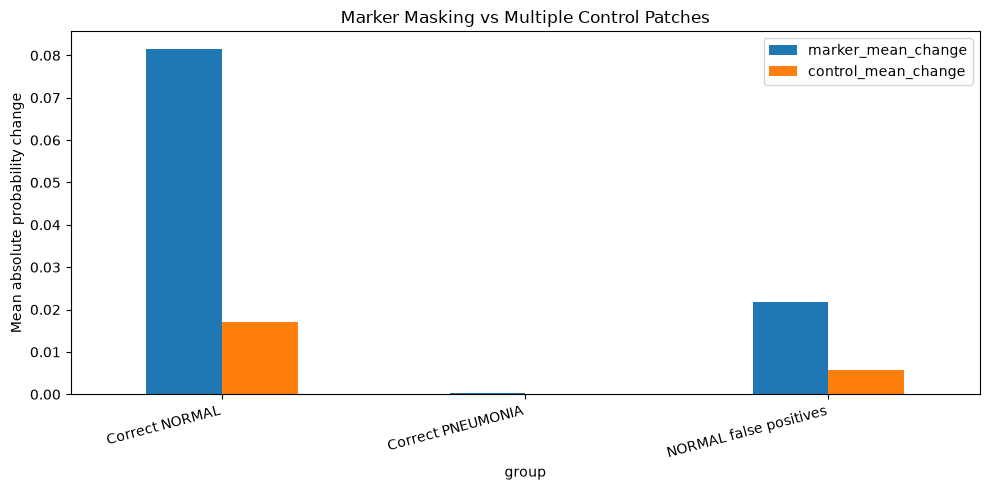

In [12]:

# ============================================================
# MULTIPLE CONTROL PATCH EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

multi_control_results = []

def make_control_boxes(marker_box, image_width=224):
    x0, y0, x1, y1 = marker_box
    width = x1 - x0

    candidates = []

    for shift in [-60, -40, -20, 20, 40, 60]:
        cx0 = x0 + shift
        cx1 = cx0 + width

        if cx0 < 0 or cx1 > image_width:
            continue

        # Avoid overlap with marker box
        if cx0 < x1 and cx1 > x0:
            continue

        candidates.append((cx0, y0, cx1, y1))

    return candidates


for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        if filename not in marker_boxes:
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        marker_box = marker_boxes[filename]

        original_prob = predict_probability(
            random_padding_model, tensor
        )

        marker_tensor = mask_patch(tensor, marker_box)

        marker_prob = predict_probability(
            random_padding_model, marker_tensor
        )

        marker_change = abs(marker_prob - original_prob)

        control_changes = []

        for control_box in make_control_boxes(marker_box):

            control_tensor = mask_patch(tensor, control_box)

            control_prob = predict_probability(
                random_padding_model, control_tensor
            )

            control_changes.append(
                abs(control_prob - original_prob)
            )

        if not control_changes:
            continue

        multi_control_results.append({
            "group": group_name,
            "image": filename,
            "marker_absolute_change": marker_change,
            "control_count": len(control_changes),
            "control_mean_absolute_change": np.mean(control_changes),
            "control_median_absolute_change": np.median(control_changes),
            "marker_vs_control_median": (
                marker_change - np.median(control_changes)
            )
        })


multi_df = pd.DataFrame(multi_control_results)

output_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "marker_multiple_controls.csv"
)

multi_df.to_csv(output_path, index=False)

print("INDIVIDUAL RESULTS")
display(multi_df.round(4))

summary = multi_df.groupby("group").agg(
    images=("image", "count"),
    marker_mean_change=("marker_absolute_change", "mean"),
    control_mean_change=("control_mean_absolute_change", "mean"),
    control_median_change=("control_median_absolute_change", "mean"),
    marker_excess=("marker_vs_control_median", "mean")
).round(4)

print("\nGROUP SUMMARY")
display(summary)

print("\nOVERALL")
print("Marker mean change:",
      round(multi_df.marker_absolute_change.mean(), 4))
print("Control mean change:",
      round(multi_df.control_mean_absolute_change.mean(), 4))

print("\nSaved:", output_path)

plot_data = summary[
    ["marker_mean_change", "control_mean_change"]
]
plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    title="Marker Masking vs Multiple Control Patches",
    ylabel="Mean absolute probability change"
)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [13]:

# ============================================================
# EXHAUSTIVE SAME-ROW MARKER VS CONTROL EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

same_row_results = []

for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        if filename not in marker_boxes:
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        x0, y0, x1, y1 = marker_boxes[filename]
        patch_w = x1 - x0
        patch_h = y1 - y0

        original_prob = predict_probability(
            random_padding_model, tensor
        )

        marker_prob = predict_probability(
            random_padding_model,
            mask_patch(tensor, (x0, y0, x1, y1))
        )

        marker_change = abs(marker_prob - original_prob)

        # Identify valid, non-padding image pixels
        padding_mask = get_padding_mask(image)

        control_changes = []
        control_positions = []

        # Test every possible horizontal position at same y
        for cx0 in range(0, 224 - patch_w + 1):

            cx1 = cx0 + patch_w

            # Exclude marker overlap
            if cx0 < x1 and cx1 > x0:
                continue

            # Exclude patches touching artificial padding
            if padding_mask[y0:y1, cx0:cx1].any():
                continue

            control_box = (cx0, y0, cx1, y1)

            control_tensor = mask_patch(tensor, control_box)

            control_prob = predict_probability(
                random_padding_model, control_tensor
            )

            change = abs(control_prob - original_prob)

            control_changes.append(change)
            control_positions.append((cx0, cx1))

        if not control_changes:
            print("No valid controls:", filename)
            continue

        control_changes = np.array(control_changes)

        same_row_results.append({
            "group": group_name,
            "image": filename,
            "marker_absolute_change": marker_change,
            "control_count": len(control_changes),
            "control_mean": control_changes.mean(),
            "control_median": np.median(control_changes),
            "control_95th_percentile": np.percentile(
                control_changes, 95
            ),
            "marker_exceeds_95th_percentile": (
                marker_change > np.percentile(control_changes, 95)
            ),
            "marker_minus_control_median": (
                marker_change - np.median(control_changes)
            )
        })


same_row_df = pd.DataFrame(same_row_results)

output_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "marker_exhaustive_same_row_controls.csv"
)

same_row_df.to_csv(output_path, index=False)

print("INDIVIDUAL RESULTS")
display(same_row_df.round(4))

print("\nGROUP SUMMARY")

summary = same_row_df.groupby("group").agg(
    images=("image", "count"),
    marker_mean=("marker_absolute_change", "mean"),
    control_mean=("control_mean", "mean"),
    control_median=("control_median", "mean"),
    control_95th=("control_95th_percentile", "mean"),
    marker_exceeds_95th=("marker_exceeds_95th_percentile", "sum")
).round(4)

display(summary)

print("\nOVERALL")
print("Images tested:", len(same_row_df))
print(
    "Markers exceeding 95th percentile:",
    same_row_df["marker_exceeds_95th_percentile"].sum(),
    "/", len(same_row_df)
)

print("\nSaved:", output_path)


No valid controls: IM-0001-0001.jpeg
No valid controls: IM-0007-0001.jpeg
No valid controls: IM-0010-0001.jpeg
No valid controls: IM-0013-0001.jpeg
No valid controls: IM-0025-0001.jpeg
No valid controls: IM-0035-0001.jpeg
No valid controls: person100_bacteria_477.jpeg
INDIVIDUAL RESULTS


,group,image,marker_absolute_change,control_count,control_mean,control_median,control_95th_percentile,marker_exceeds_95th_percentile,marker_minus_control_median
0,NORMAL false positives,IM-0003-0001.jpeg,0.0294,205,0.0018,0.0013,0.0054,True,0.0281
1,NORMAL false positives,IM-0005-0001.jpeg,0.0023,184,0.0009,0.0007,0.0019,True,0.0016
2,Correct PNEUMONIA,person100_bacteria_475.jpeg,0.0000,205,0.0005,0.0003,0.0014,False,-0.0003
3,Correct PNEUMONIA,person100_bacteria_479.jpeg,0.0002,187,0.0000,0.0000,0.0000,True,0.0002
4,Correct PNEUMONIA,person100_bacteria_480.jpeg,0.0000,187,0.0000,0.0000,0.0000,False,-0.0000



GROUP SUMMARY


,images,marker_mean,control_mean,control_median,control_95th,marker_exceeds_95th
group,,,,,,
Correct PNEUMONIA,3,0.0001,0.0002,0.0001,0.0005,1
NORMAL false positives,2,0.0158,0.0013,0.0010,0.0037,2



OVERALL
Images tested: 5
Markers exceeding 95th percentile: 3 / 5

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_exhaustive_same_row_controls.csv


In [14]:

# ============================================================
# 2D RANDOMIZED MARKER VS CONTROL EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

rng = np.random.default_rng(42)
results_2d = []

for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        if filename not in marker_boxes:
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        x0, y0, x1, y1 = marker_boxes[filename]
        patch_w, patch_h = x1 - x0, y1 - y0

        original_prob = predict_probability(
            random_padding_model, tensor
        )

        marker_prob = predict_probability(
            random_padding_model,
            mask_patch(tensor, (x0, y0, x1, y1))
        )

        marker_change = abs(marker_prob - original_prob)

        padding_mask = get_padding_mask(image)

        # Build valid control locations throughout the image
        candidates = []

        for cy in range(0, 224 - patch_h + 1, 2):
            for cx in range(0, 224 - patch_w + 1, 2):

                # Do not overlap the marker patch
                if cx < x1 and cx + patch_w > x0:
                    if cy < y1 and cy + patch_h > y0:
                        continue

                # Exclude artificial padding
                if padding_mask[
                    cy:cy + patch_h,
                    cx:cx + patch_w
                ].any():
                    continue

                candidates.append((cx, cy))

        if not candidates:
            print("No 2D controls:", filename)
            continue

        # Sample up to 100 unique control positions
        sample_count = min(100, len(candidates))
        selected = rng.choice(
            len(candidates),
            size=sample_count,
            replace=False
        )

        control_changes = []

        for selected_index in selected:
            cx, cy = candidates[selected_index]

            control_box = (
                cx, cy, cx + patch_w, cy + patch_h
            )

            control_tensor = mask_patch(
                tensor, control_box
            )

            control_prob = predict_probability(
                random_padding_model, control_tensor
            )

            control_changes.append(
                abs(control_prob - original_prob)
            )

        control_changes = np.asarray(control_changes)

        # Empirical percentile rank; retain full precision
        marker_percentile = (
            100 * np.mean(control_changes <= marker_change)
        )

        results_2d.append({
            "group": group_name,
            "image": filename,
            "marker_change": marker_change,
            "control_count": len(control_changes),
            "control_mean": control_changes.mean(),
            "control_median": np.median(control_changes),
            "control_95th": np.percentile(control_changes, 95),
            "marker_percentile": marker_percentile,
            "marker_exceeds_95th": (
                marker_change > np.percentile(control_changes, 95)
            )
        })

df_2d = pd.DataFrame(results_2d)

output = (
    Path(PROJECT_DIR)
    / "reports"
    / "marker_2d_random_controls.csv"
)

df_2d.to_csv(output, index=False)

print("INDIVIDUAL RESULTS")
display(df_2d.round(5))

print("\nGROUP SUMMARY")

summary_2d = df_2d.groupby("group").agg(
    images=("image", "count"),
    marker_mean=("marker_change", "mean"),
    control_mean=("control_mean", "mean"),
    control_median=("control_median", "mean"),
    marker_above_95th=("marker_exceeds_95th", "sum")
).round(5)

display(summary_2d)

print("\nTOTAL IMAGES:", len(df_2d))
print(
    "Marker above 95th percentile:",
    df_2d["marker_exceeds_95th"].sum(),
    "/", len(df_2d)
)

print("\nSaved:", output)


INDIVIDUAL RESULTS


,group,image,marker_change,control_count,control_mean,control_median,control_95th,marker_percentile,marker_exceeds_95th
0,NORMAL false positives,IM-0001-0001.jpeg,0.05267,100,0.00586,0.00372,0.01920,100.0,True
1,NORMAL false positives,IM-0003-0001.jpeg,0.02936,100,0.00267,0.00148,0.00950,100.0,True
2,NORMAL false positives,IM-0005-0001.jpeg,0.00230,100,0.00047,0.00032,0.00157,99.0,True
3,NORMAL false positives,IM-0007-0001.jpeg,0.00338,100,0.00141,0.00094,0.00413,90.0,False
4,Correct NORMAL,IM-0010-0001.jpeg,0.12632,100,0.00799,0.00300,0.03872,100.0,True
5,Correct NORMAL,IM-0013-0001.jpeg,0.18447,100,0.01085,0.00818,0.02829,100.0,True
6,Correct NORMAL,IM-0025-0001.jpeg,0.01222,100,0.00068,0.00031,0.00238,100.0,True
7,Correct NORMAL,IM-0035-0001.jpeg,0.00346,100,0.01059,0.00528,0.04181,39.0,False
8,Correct PNEUMONIA,person100_bacteria_475.jpeg,0.00000,100,0.00045,0.00026,0.00147,2.0,False
9,Correct PNEUMONIA,person100_bacteria_477.jpeg,0.00087,100,0.00001,0.00000,0.00002,100.0,True



GROUP SUMMARY


,images,marker_mean,control_mean,control_median,marker_above_95th
group,,,,,
Correct NORMAL,4,0.08162,0.00753,0.00419,3
Correct PNEUMONIA,4,0.00027,0.00011,0.00007,2
NORMAL false positives,4,0.02193,0.00260,0.00161,3



TOTAL IMAGES: 12
Marker above 95th percentile: 8 / 12

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_2d_random_controls.csv


## 7. Marker Sensitivity Experiments

This section investigates whether image markers influence the CNN's predictions.

Marker regions are compared with control regions using controlled image perturbations and changes in model logits.

The experiments explore potential sensitivity to non-medical image features.

In [15]:

# ============================================================
# MARKER VS CONTROL: LOGIT SENSITIVITY
# ============================================================

import numpy as np
import pandas as pd
import torch
from pathlib import Path

rng = np.random.default_rng(42)
logit_results = []

def get_model_logit(model, tensor):
    model.eval()
    with torch.no_grad():
        x = tensor.unsqueeze(0).to(device)
        output = model(x)
        return float(output.reshape(-1)[0].item())


for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        if filename not in marker_boxes:
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        x0, y0, x1, y1 = marker_boxes[filename]
        patch_w = x1 - x0
        patch_h = y1 - y0

        original_logit = get_model_logit(
            random_padding_model, tensor
        )

        marker_tensor = mask_patch(
            tensor, (x0, y0, x1, y1)
        )

        marker_logit = get_model_logit(
            random_padding_model, marker_tensor
        )

        marker_change = abs(marker_logit - original_logit)

        padding_mask = get_padding_mask(image)
        candidates = []

        # Find valid same-size patches throughout the image
        for cy in range(0, 224 - patch_h + 1, 2):
            for cx in range(0, 224 - patch_w + 1, 2):

                # Exclude marker overlap
                if (cx < x1 and cx + patch_w > x0 and
                    cy < y1 and cy + patch_h > y0):
                    continue

                # Exclude artificial padding
                if padding_mask[
                    cy:cy + patch_h,
                    cx:cx + patch_w
                ].any():
                    continue

                candidates.append((cx, cy))

        if not candidates:
            print("No valid controls:", filename)
            continue

        sample_count = min(100, len(candidates))
        chosen = rng.choice(
            len(candidates),
            size=sample_count,
            replace=False
        )

        control_changes = []

        for j in chosen:
            cx, cy = candidates[j]

            control_tensor = mask_patch(
                tensor,
                (cx, cy, cx + patch_w, cy + patch_h)
            )

            control_logit = get_model_logit(
                random_padding_model, control_tensor
            )

            control_changes.append(
                abs(control_logit - original_logit)
            )

        control_changes = np.asarray(control_changes)
        control_95 = np.percentile(control_changes, 95)

        logit_results.append({
            "group": group_name,
            "image": filename,
            "original_logit": original_logit,
            "marker_masked_logit": marker_logit,
            "marker_absolute_logit_change": marker_change,
            "control_count": len(control_changes),
            "control_mean_logit_change": control_changes.mean(),
            "control_median_logit_change": np.median(control_changes),
            "control_95th_logit_change": control_95,
            "marker_exceeds_control_95th": marker_change > control_95
        })


logit_df = pd.DataFrame(logit_results)

output_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "marker_logit_sensitivity.csv"
)

logit_df.to_csv(output_path, index=False)

print("INDIVIDUAL LOGIT RESULTS")
display(logit_df.round(5))

print("\nGROUP SUMMARY")

logit_summary = logit_df.groupby("group").agg(
    images=("image", "count"),
    marker_mean=("marker_absolute_logit_change", "mean"),
    control_mean=("control_mean_logit_change", "mean"),
    control_median=("control_median_logit_change", "mean"),
    marker_above_95th=("marker_exceeds_control_95th", "sum")
).round(5)

display(logit_summary)

print("\nOVERALL")
print("Images:", len(logit_df))
print(
    "Marker exceeds control 95th percentile:",
    logit_df["marker_exceeds_control_95th"].sum(),
    "/", len(logit_df)
)

print("\nSaved:", output_path)


INDIVIDUAL LOGIT RESULTS


,group,image,original_logit,marker_masked_logit,marker_absolute_logit_change,control_count,control_mean_logit_change,control_median_logit_change,control_95th_logit_change,marker_exceeds_control_95th
0,NORMAL false positives,IM-0001-0001.jpeg,2.04028,2.71028,0.67000,100,0.05884,0.03626,0.19059,True
1,NORMAL false positives,IM-0003-0001.jpeg,3.10609,2.55314,0.55295,100,0.06935,0.03609,0.26036,True
2,NORMAL false positives,IM-0005-0001.jpeg,4.65851,4.43701,0.22150,100,0.05218,0.03403,0.18386,True
3,NORMAL false positives,IM-0007-0001.jpeg,3.80724,3.98002,0.17278,100,0.06369,0.04393,0.18146,False
4,Correct NORMAL,IM-0010-0001.jpeg,-1.71913,-0.95288,0.76625,100,0.05812,0.02330,0.27367,True
5,Correct NORMAL,IM-0013-0001.jpeg,-1.06581,-0.23845,0.82736,100,0.05638,0.04246,0.14386,True
6,Correct NORMAL,IM-0025-0001.jpeg,-4.41030,-3.69581,0.71449,100,0.05618,0.02630,0.20142,True
7,Correct NORMAL,IM-0035-0001.jpeg,-1.48620,-1.50938,0.02319,100,0.06900,0.03527,0.30269,False
8,Correct PNEUMONIA,person100_bacteria_475.jpeg,4.39068,4.39068,0.00000,100,0.03778,0.02172,0.12957,False
9,Correct PNEUMONIA,person100_bacteria_477.jpeg,8.05377,6.73235,1.32142,100,0.02070,0.01186,0.06827,True



GROUP SUMMARY


,images,marker_mean,control_mean,control_median,marker_above_95th
group,,,,,
Correct NORMAL,4,0.58282,0.05992,0.03183,3
Correct PNEUMONIA,4,0.62976,0.03024,0.01725,2
NORMAL false positives,4,0.40431,0.06101,0.03758,3



OVERALL
Images: 12
Marker exceeds control 95th percentile: 8 / 12

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_logit_sensitivity.csv


In [16]:

# ============================================================
# MARKER ROBUSTNESS: LOCAL MEAN vs BLUR REPLACEMENT
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path

rng = np.random.default_rng(123)
robustness_results = []

def replace_patch(tensor, box, method):
    """Replace a patch using local mean or blurred image content."""
    x0, y0, x1, y1 = box
    result = tensor.clone()
    _, h, w = result.shape

    if method == "local_mean":
        ring = torch.zeros((h, w), dtype=torch.bool)

        ox0, ox1 = max(0, x0 - 6), min(w, x1 + 6)
        oy0, oy1 = max(0, y0 - 6), min(h, y1 + 6)

        ring[oy0:oy1, ox0:ox1] = True
        ring[y0:y1, x0:x1] = False

        surrounding = result[:, ring]

        fill = (
            surrounding.mean(dim=1)
            if surrounding.numel()
            else result.mean(dim=(1, 2))
        )

        result[:, y0:y1, x0:x1] = fill[:, None, None]

    elif method == "blur":
        # Average pooling creates a smooth, locally blurred image.
        blurred = F.avg_pool2d(
            result.unsqueeze(0),
            kernel_size=11,
            stride=1,
            padding=5
        ).squeeze(0)

        result[:, y0:y1, x0:x1] = blurred[:, y0:y1, x0:x1]

    return result


for group_name, indices in selected_groups.items():

    for idx in indices:

        image_path, true_label = test_paths[idx]
        filename = Path(image_path).name

        if filename not in marker_boxes:
            continue

        image = Image.open(image_path).convert("L")
        tensor = eval_transform(image)

        x0, y0, x1, y1 = marker_boxes[filename]
        pw, ph = x1 - x0, y1 - y0

        original_logit = get_model_logit(
            random_padding_model, tensor
        )

        padding_mask = get_padding_mask(image)
        candidates = []

        for cy in range(0, 224 - ph + 1, 2):
            for cx in range(0, 224 - pw + 1, 2):

                # Exclude overlap with marker
                if (cx < x1 and cx + pw > x0 and
                    cy < y1 and cy + ph > y0):
                    continue

                if padding_mask[cy:cy+ph, cx:cx+pw].any():
                    continue

                candidates.append((cx, cy))

        if not candidates:
            print("No valid controls:", filename)
            continue

        chosen = rng.choice(
            len(candidates),
            size=min(50, len(candidates)),
            replace=False
        )

        for method in ["local_mean", "blur"]:

            marker_box = (x0, y0, x1, y1)

            marker_tensor = replace_patch(
                tensor, marker_box, method
            )

            marker_logit = get_model_logit(
                random_padding_model, marker_tensor
            )

            marker_change = abs(marker_logit - original_logit)
            control_changes = []

            for j in chosen:
                cx, cy = candidates[j]
                control_box = (
                    cx, cy, cx + pw, cy + ph
                )

                control_tensor = replace_patch(
                    tensor, control_box, method
                )

                control_logit = get_model_logit(
                    random_padding_model, control_tensor
                )

                control_changes.append(
                    abs(control_logit - original_logit)
                )

            control_changes = np.asarray(control_changes)

            robustness_results.append({
                "group": group_name,
                "image": filename,
                "method": method,
                "marker_logit_change": marker_change,
                "control_count": len(control_changes),
                "control_mean": control_changes.mean(),
                "control_median": np.median(control_changes),
                "control_95th": np.percentile(
                    control_changes, 95
                ),
                "marker_exceeds_95th": (
                    marker_change > np.percentile(
                        control_changes, 95
                    )
                )
            })

robust_df = pd.DataFrame(robustness_results)

output_path = (
    Path(PROJECT_DIR)
    / "reports"
    / "marker_replacement_robustness.csv"
)

robust_df.to_csv(output_path, index=False)

print("INDIVIDUAL RESULTS")
display(robust_df.round(5))

print("\nGROUP AND METHOD SUMMARY")

summary = robust_df.groupby(
    ["group", "method"]
).agg(
    images=("image", "count"),
    marker_mean=("marker_logit_change", "mean"),
    control_mean=("control_mean", "mean"),
    control_median=("control_median", "mean"),
    marker_above_95th=("marker_exceeds_95th", "sum")
).round(5)

display(summary)

print("\nOVERALL METHOD COMPARISON")

overall = robust_df.groupby("method").agg(
    marker_mean=("marker_logit_change", "mean"),
    control_mean=("control_mean", "mean"),
    images=("image", "count"),
    marker_above_95th=("marker_exceeds_95th", "sum")
).round(5)

display(overall)

print("\nSaved:", output_path)


INDIVIDUAL RESULTS


,group,image,method,marker_logit_change,control_count,control_mean,control_median,control_95th,marker_exceeds_95th
0,NORMAL false positives,IM-0001-0001.jpeg,local_mean,0.66392,50,0.05161,0.03600,0.20262,True
1,NORMAL false positives,IM-0001-0001.jpeg,blur,0.67512,50,0.03244,0.01592,0.11212,True
2,NORMAL false positives,IM-0003-0001.jpeg,local_mean,0.55044,50,0.05399,0.02408,0.19863,True
3,NORMAL false positives,IM-0003-0001.jpeg,blur,0.52745,50,0.02783,0.01483,0.11353,True
4,NORMAL false positives,IM-0005-0001.jpeg,local_mean,0.29884,50,0.06372,0.03284,0.21722,True
5,NORMAL false positives,IM-0005-0001.jpeg,blur,0.31642,50,0.03457,0.01415,0.13493,True
6,NORMAL false positives,IM-0007-0001.jpeg,local_mean,0.17741,50,0.05556,0.04076,0.15084,True
7,NORMAL false positives,IM-0007-0001.jpeg,blur,0.22738,50,0.03591,0.01986,0.10739,True
8,Correct NORMAL,IM-0010-0001.jpeg,local_mean,0.78958,50,0.06984,0.05785,0.18689,True
9,Correct NORMAL,IM-0010-0001.jpeg,blur,0.79245,50,0.02960,0.01922,0.07870,True



GROUP AND METHOD SUMMARY


images  marker_mean  control_mean  \
group                  method                                          
Correct NORMAL         blur             4      0.61918       0.03067   
                       local_mean       4      0.60539       0.05985   
Correct PNEUMONIA      blur             4      0.71574       0.02560   
                       local_mean       4      0.63044       0.03753   
NORMAL false positives blur             4      0.43659       0.03269   
                       local_mean       4      0.42265       0.05622   

                                   control_median  marker_above_95th  
group                  method                                         
Correct NORMAL         blur               0.01889                  3  
                       local_mean         0.04363                  3  
Correct PNEUMONIA      blur               0.01069                  2  
                       local_mean         0.01890                  2  
NORMAL false positives blur               0.01619                  4  
                       local_mean         0.03342                  4


OVERALL METHOD COMPARISON


,marker_mean,control_mean,images,marker_above_95th
method,,,,
blur,0.59050,0.02965,12,9
local_mean,0.55283,0.05120,12,9



Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\marker_replacement_robustness.csv


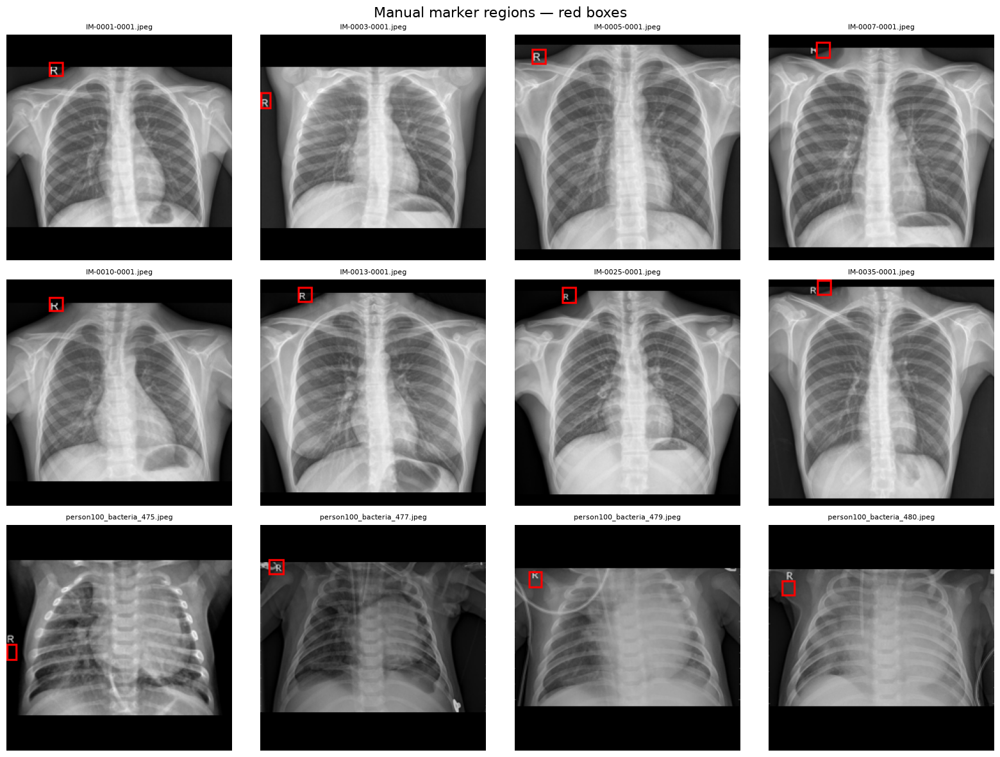

In [17]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from pathlib import Path

# Display original images with the marker regions outlined
image_names = list(marker_boxes.keys())

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, image_name in zip(axes, image_names):

    # Find image path
    image_path = next(
        (Path(p) for p, label in test_paths
         if Path(p).name == image_name),
        None
    )

    if image_path is None:
        ax.set_title(f"Not found: {image_name}")
        ax.axis("off")
        continue

    img = Image.open(image_path).convert("L")
    img = ImageOps.contain(img, (224, 224))

    # Match evaluation preprocessing
    canvas = Image.new("L", (224, 224), 0)
    x = (224 - img.width) // 2
    y = (224 - img.height) // 2
    canvas.paste(img, (x, y))

    # Draw marker box
    display_img = canvas.convert("RGB")
    draw = ImageDraw.Draw(display_img)

    x1, y1, x2, y2 = marker_boxes[image_name]
    draw.rectangle((x1, y1, x2, y2), outline="red", width=2)

    ax.imshow(display_img)
    ax.set_title(image_name, fontsize=8)
    ax.axis("off")

plt.suptitle(
    "Manual marker regions — red boxes",
    fontsize=16
)
plt.tight_layout()
plt.show()

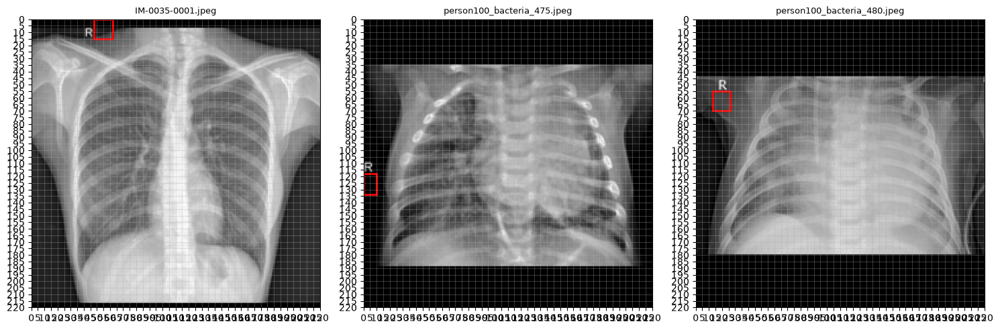

In [18]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageOps

check_images = [
    "IM-0035-0001.jpeg",
    "person100_bacteria_475.jpeg",
    "person100_bacteria_480.jpeg"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, image_name in zip(axes, check_images):

    image_path = next(
        (Path(p) for p, label in test_paths
         if Path(p).name == image_name),
        None
    )

    if image_path is None:
        ax.set_title(f"Not found: {image_name}")
        continue

    img = Image.open(image_path).convert("L")
    img = ImageOps.contain(img, (224, 224))

    canvas = Image.new("L", (224, 224), 0)
    x = (224 - img.width) // 2
    y = (224 - img.height) // 2
    canvas.paste(img, (x, y))

    x1, y1, x2, y2 = marker_boxes[image_name]

    ax.imshow(canvas, cmap="gray", origin="upper")
    ax.add_patch(plt.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="red", linewidth=2
    ))

    ax.set_xlim(max(0, x1-15), min(224, x2+15))
    ax.set_ylim(min(224, y2+15), max(0, y1-15))
    ax.set_xticks(range(0, 225, 5))
    ax.set_yticks(range(0, 225, 5))
    ax.grid(alpha=0.3)
    ax.set_title(image_name, fontsize=9)

plt.tight_layout()
plt.show()

In [19]:
marker_boxes.update({
    "IM-0035-0001.jpeg": (40, 4, 55, 20),
    "person100_bacteria_475.jpeg": (0, 112, 10, 129),
    "person100_bacteria_480.jpeg": (14, 45, 29, 62)
})

print("Updated marker coordinates:")
for name, box in marker_boxes.items():
    print(f"{name}: {box}")

Updated marker coordinates:
IM-0001-0001.jpeg: (42, 27, 56, 41)
IM-0003-0001.jpeg: (0, 57, 10, 73)
IM-0005-0001.jpeg: (17, 14, 31, 29)
IM-0007-0001.jpeg: (47, 7, 61, 23)
IM-0010-0001.jpeg: (42, 17, 56, 31)
IM-0013-0001.jpeg: (37, 7, 51, 22)
IM-0025-0001.jpeg: (47, 7, 61, 23)
IM-0035-0001.jpeg: (40, 4, 55, 20)
person100_bacteria_475.jpeg: (0, 112, 10, 129)
person100_bacteria_477.jpeg: (8, 34, 23, 49)
person100_bacteria_479.jpeg: (14, 46, 27, 62)
person100_bacteria_480.jpeg: (14, 45, 29, 62)


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from pathlib import Path

# Reproducibility
rng = np.random.default_rng(123)

MODEL = random_padding_model
MODEL.eval()

PATCH_COUNT = 50
METHODS = ["local_mean", "blur"]

def replace_patch(tensor, box, method):
    """Replace a patch using local mean or local blur."""
    x1, y1, x2, y2 = box
    result = tensor.clone()

    if method == "local_mean":
        margin = 6
        rx1 = max(0, x1 - margin)
        ry1 = max(0, y1 - margin)
        rx2 = min(224, x2 + margin)
        ry2 = min(224, y2 + margin)

        ring = result[:, ry1:ry2, rx1:rx2].clone()

        # Exclude the patch itself from the surrounding ring
        patch_mask = torch.ones(
            (ry2 - ry1, rx2 - rx1),
            dtype=torch.bool,
            device=result.device
        )
        patch_mask[
            y1 - ry1:y2 - ry1,
            x1 - rx1:x2 - rx1
        ] = False

        surrounding = ring[:, patch_mask]

        if surrounding.numel() > 0:
            fill = surrounding.mean(dim=1).view(-1, 1, 1)
            result[:, y1:y2, x1:x2] = fill

    elif method == "blur":
        blurred = F.avg_pool2d(
            result.unsqueeze(0),
            kernel_size=11,
            stride=1,
            padding=5
        ).squeeze(0)

        result[:, y1:y2, x1:x2] = blurred[:, y1:y2, x1:x2]

    return result


def get_valid_positions(image, patch_w, patch_h, marker_box):
    """Find candidate control patches entirely inside the real image."""
    contained = ImageOps.contain(image, (224, 224))

    offset_x = (224 - contained.width) // 2
    offset_y = (224 - contained.height) // 2

    valid = []

    mx1, my1, mx2, my2 = marker_box

    for y in range(offset_y, offset_y + contained.height - patch_h + 1, 2):
        for x in range(offset_x, offset_x + contained.width - patch_w + 1, 2):

            # Exclude marker overlap
            overlap = (
                x < mx2 and x + patch_w > mx1
                and y < my2 and y + patch_h > my1
            )

            if not overlap:
                valid.append((x, y, x + patch_w, y + patch_h))

    return valid


def load_eval_tensor(image_path):
    image = Image.open(image_path).convert("L")
    image = ImageOps.contain(image, (224, 224))

    canvas = Image.new("L", (224, 224), 0)
    x = (224 - image.width) // 2
    y = (224 - image.height) // 2
    canvas.paste(image, (x, y))

    tensor = eval_transform(canvas).to(device)
    return tensor


# Map image names to paths
path_lookup = {
    Path(path).name: Path(path)
    for path, label in test_paths
}

individual_results = []

with torch.no_grad():

    for group, image_names in selected_groups.items():

        for image_index in image_names:

            image_path = Path(test_paths[image_index][0])
            image_name = image_path.name

            if image_name not in marker_boxes:
                continue

            if image_name not in path_lookup:
                print("Skipping missing image:", image_name)
                continue

            box = marker_boxes[image_name]
            x1, y1, x2, y2 = box

            image = Image.open(image_path).convert("L")
            tensor = load_eval_tensor(image_path)

            original_logit = get_model_logit(MODEL, tensor)

            patch_w = x2 - x1
            patch_h = y2 - y1

            candidates = get_valid_positions(
                image, patch_w, patch_h, box
            )

            if len(candidates) < PATCH_COUNT:
                print(
                    f"Skipping {image_name}: "
                    f"only {len(candidates)} valid controls"
                )
                continue

            selected_controls = rng.choice(
                len(candidates),
                size=PATCH_COUNT,
                replace=False
            )

            control_boxes = [
                candidates[i] for i in selected_controls
            ]

            for method in METHODS:

                # Marker replacement
                marker_tensor = replace_patch(tensor, box, method)
                marker_logit = get_model_logit(MODEL, marker_tensor)

                marker_change = abs(
                    original_logit - marker_logit
                )

                # Control replacements
                control_changes = []

                for control_box in control_boxes:
                    control_tensor = replace_patch(
                        tensor, control_box, method
                    )

                    control_logit = get_model_logit(
                        MODEL, control_tensor
                    )

                    control_changes.append(
                        abs(original_logit - control_logit)
                    )

                control_changes = np.asarray(
                    control_changes, dtype=float
                )

                control_mean = float(control_changes.mean())
                control_median = float(np.median(control_changes))
                control_95th = float(
                    np.percentile(control_changes, 95)
                )

                individual_results.append({
                    "group": group,
                    "image": image_name,
                    "method": method,
                    "marker_logit_change": float(marker_change),
                    "control_count": len(control_changes),
                    "control_mean": control_mean,
                    "control_median": control_median,
                    "control_95th": control_95th,
                    "marker_exceeds_95th": (
                        float(marker_change) > control_95th
                    )
                })

# Create results
corrected_df = pd.DataFrame(individual_results)

if corrected_df.empty:
    raise RuntimeError("No results generated. Check image paths and marker boxes.")

# Group summary
corrected_summary = (
    corrected_df.groupby(["group", "method"])
    .agg(
        images=("image", "nunique"),
        marker_mean=("marker_logit_change", "mean"),
        control_mean=("control_mean", "mean"),
        control_median=("control_median", "mean"),
        marker_above_95th=("marker_exceeds_95th", "sum")
    )
)

# Overall comparison
corrected_overall = (
    corrected_df.groupby("method")
    .agg(
        marker_mean=("marker_logit_change", "mean"),
        control_mean=("control_mean", "mean"),
        images=("image", "nunique"),
        marker_above_95th=("marker_exceeds_95th", "sum")
    )
)

# Save without overwriting previous experiments
reports_dir = Path(REPORTS_DIR)
reports_dir.mkdir(parents=True, exist_ok=True)

corrected_df.to_csv(
    reports_dir / "marker_replacement_robustness_corrected.csv",
    index=False
)

corrected_summary.to_csv(
    reports_dir / "marker_replacement_summary_corrected.csv"
)

corrected_overall.to_csv(
    reports_dir / "marker_replacement_overall_corrected.csv"
)

# Display
print("\nINDIVIDUAL CORRECTED RESULTS")
display(corrected_df.round(5))

print("\nGROUP AND METHOD SUMMARY")
display(corrected_summary.round(5))

print("\nOVERALL METHOD COMPARISON")
display(corrected_overall.round(5))

print("\nSaved corrected results in:", reports_dir)


In [21]:
from pathlib import Path

# Reconstruct the reports directory
PROJECT_DIR = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save existing experiment results
corrected_df.to_csv(
    REPORTS_DIR / "marker_replacement_robustness_corrected.csv",
    index=False
)

corrected_summary.to_csv(
    REPORTS_DIR / "marker_replacement_summary_corrected.csv"
)

corrected_overall.to_csv(
    REPORTS_DIR / "marker_replacement_overall_corrected.csv"
)

print("All corrected results saved successfully!")
print("Location:", REPORTS_DIR)

All corrected results saved successfully!
Location: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports


In [22]:
print("\n1. INDIVIDUAL CORRECTED RESULTS")
display(corrected_df.round(5))

print("\n2. GROUP AND METHOD SUMMARY")
display(corrected_summary.round(5))

print("\n3. OVERALL METHOD COMPARISON")
display(corrected_overall.round(5))


1. INDIVIDUAL CORRECTED RESULTS


,group,image,method,marker_logit_change,control_count,control_mean,control_median,control_95th,marker_exceeds_95th
0,NORMAL false positives,IM-0001-0001.jpeg,local_mean,0.79394,50,0.05487,0.03796,0.19893,True
1,NORMAL false positives,IM-0001-0001.jpeg,blur,0.80502,50,0.03727,0.01889,0.12927,True
2,NORMAL false positives,IM-0003-0001.jpeg,local_mean,0.68378,50,0.05555,0.02562,0.21385,True
3,NORMAL false positives,IM-0003-0001.jpeg,blur,0.66121,50,0.03132,0.01452,0.12832,True
4,NORMAL false positives,IM-0005-0001.jpeg,local_mean,0.39934,50,0.06777,0.03566,0.21753,True
5,NORMAL false positives,IM-0005-0001.jpeg,blur,0.41537,50,0.03994,0.01739,0.15573,True
6,NORMAL false positives,IM-0007-0001.jpeg,local_mean,0.23083,50,0.06467,0.04055,0.19280,True
7,NORMAL false positives,IM-0007-0001.jpeg,blur,0.27730,50,0.04110,0.01587,0.11828,True
8,Correct NORMAL,IM-0010-0001.jpeg,local_mean,0.91105,50,0.07164,0.05369,0.19030,True
9,Correct NORMAL,IM-0010-0001.jpeg,blur,0.91314,50,0.03392,0.01899,0.10599,True



2. GROUP AND METHOD SUMMARY


images  marker_mean  control_mean  \
group                  method                                          
Correct NORMAL         blur             4      0.91152       0.04208   
                       local_mean       4      0.87690       0.06617   
Correct PNEUMONIA      blur             4      1.29860       0.03221   
                       local_mean       4      1.20137       0.04362   
NORMAL false positives blur             4      0.53973       0.03741   
                       local_mean       4      0.52697       0.06071   

                                   control_median  marker_above_95th  
group                  method                                         
Correct NORMAL         blur               0.02341                  4  
                       local_mean         0.04930                  4  
Correct PNEUMONIA      blur               0.01427                  3  
                       local_mean         0.02371                  4  
NORMAL false positives blur               0.01667                  4  
                       local_mean         0.03495                  4


3. OVERALL METHOD COMPARISON


,marker_mean,control_mean,images,marker_above_95th
method,,,,
blur,0.91662,0.03723,12,11
local_mean,0.86841,0.05683,12,12


In [23]:

from pathlib import Path
import inspect

project_dir = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

print("=" * 60)
print("1. DATASET AND DATALOADER VARIABLES")
print("=" * 60)

names_to_check = [
    "train_dataset",
    "val_dataset",
    "train_loader",
    "val_loader",
    "train_dataloader",
    "val_dataloader",
    "random_padding_model",
    "device",
    "criterion",
    "optimizer",
    "scheduler",
    "num_epochs",
    "EPOCHS",
    "batch_size",
    "learning_rate"
]

for name in names_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")

        if name in ["train_dataset", "val_dataset"]:
            print("Length:", len(obj))
            print("Transform:", getattr(obj, "transform", None))

        elif "loader" in name or "dataloader" in name:
            print("Dataset:", type(obj.dataset).__name__)
            print("Dataset size:", len(obj.dataset))
            print("Batch size:", obj.batch_size)

        elif name == "random_padding_model":
            print("Architecture:")
            print(obj)

        else:
            print(obj)

print("\n" + "=" * 60)
print("2. DATASET SOURCE CODE")
print("=" * 60)

dataset_file = project_dir / "src" / "dataset.py"

if dataset_file.exists():
    print(dataset_file.read_text(encoding="utf-8"))
else:
    print("src/dataset.py not found.")

print("\n" + "=" * 60)
print("3. MODEL SOURCE CODE")
print("=" * 60)

model_file = project_dir / "src" / "model.py"

if model_file.exists():
    print(model_file.read_text(encoding="utf-8"))
else:
    print("src/model.py not found.")


1. DATASET AND DATALOADER VARIABLES

train_loader: DataLoader
Dataset: Subset
Dataset size: 4172
Batch size: 32

val_loader: DataLoader
Dataset: Subset
Dataset size: 1044
Batch size: 32

random_padding_model: ChestXrayCNN
Architecture:
ChestXrayCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=1, bias=True)
  )
)

device: device
cpu

2. DATASET SOURCE CODE
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class ChestXrayDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):
      

In [24]:

import torch
from pathlib import Path
from collections import Counter

print("TRAIN DATASET")
train_subset = train_loader.dataset
base_train_dataset = train_subset.dataset

print("Subset size:", len(train_subset))
print("Underlying dataset:", type(base_train_dataset).__name__)
print("Training transform:", base_train_dataset.transform)

print("\nVALIDATION DATASET")
val_subset = val_loader.dataset
base_val_dataset = val_subset.dataset

print("Subset size:", len(val_subset))
print("Underlying dataset:", type(base_val_dataset).__name__)
print("Validation transform:", base_val_dataset.transform)

print("\nBATCH CHECK")
images, labels = next(iter(train_loader))
print("Image shape:", images.shape)
print("Image dtype:", images.dtype)
print("Image min/max:", images.min().item(), images.max().item())
print("Labels shape:", labels.shape)
print("Labels dtype:", labels.dtype)
print("Labels:", torch.unique(labels, return_counts=True))

print("\nCHECKPOINT CHECK")
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])

print("\nEXPERIMENT OUTPUT DIRECTORY")
experiment_dir = Path(PROJECT_DIR) / "models" / "corner_suppression_experiment"
experiment_dir.mkdir(parents=True, exist_ok=True)
print(experiment_dir)


TRAIN DATASET
Subset size: 4172
Underlying dataset: ImageFolder
Training transform: <__main__.ResizeWithPadding object at 0x000002361C8DBA10>

VALIDATION DATASET
Subset size: 1044
Underlying dataset: ImageFolder
Validation transform: <__main__.ResizeWithPadding object at 0x000002361C8DBA10>

BATCH CHECK
Image shape: torch.Size([32, 1, 224, 224])
Image dtype: torch.float32
Image min/max: 0.0 1.0
Labels shape: torch.Size([32])
Labels dtype: torch.int64
Labels: (tensor([0, 1]), tensor([ 8, 24]))

CHECKPOINT CHECK
Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['features.0.weight', 'features.0.bias', 'features.3.weight', 'features.3.bias', 'classifier.1.weight', 'classifier.1.bias']

EXPERIMENT OUTPUT DIRECTORY
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment


In [25]:

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from pathlib import Path

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

SEED = 42
EPOCHS = 5
LEARNING_RATE = 1e-5
MASK_PROBABILITY = 0.50
MASK_SIZE = 20

EXPERIMENT_DIR = (
    Path(PROJECT_DIR) / "models" / "corner_suppression_experiment"
)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_PATH = EXPERIMENT_DIR / "baseline_finetuned.pth"
TREATMENT_PATH = EXPERIMENT_DIR / "border_suppression_finetuned.pth"

# Preserve original starting weights
initial_state = copy.deepcopy(
    random_padding_model.state_dict()
)

# --------------------------------------------------
# 2. REPRODUCIBILITY
# --------------------------------------------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# --------------------------------------------------
# 3. BORDER MASKING AUGMENTATION
# --------------------------------------------------

def apply_border_masking(images, rng):
    """
    Randomly replace a 20x20 patch along one image border
    using the surrounding local mean.
    """
    images = images.clone()
    batch_size, channels, height, width = images.shape

    for i in range(batch_size):

        if rng.random() >= MASK_PROBABILITY:
            continue

        side = rng.choice(["top", "bottom", "left", "right"])

        if side == "top":
            x1 = int(rng.integers(0, width - MASK_SIZE + 1))
            y1 = 0

        elif side == "bottom":
            x1 = int(rng.integers(0, width - MASK_SIZE + 1))
            y1 = height - MASK_SIZE

        elif side == "left":
            x1 = 0
            y1 = int(rng.integers(0, height - MASK_SIZE + 1))

        else:
            x1 = width - MASK_SIZE
            y1 = int(rng.integers(0, height - MASK_SIZE + 1))

        x2 = x1 + MASK_SIZE
        y2 = y1 + MASK_SIZE

        # Local surrounding ring
        rx1 = max(0, x1 - 5)
        ry1 = max(0, y1 - 5)
        rx2 = min(width, x2 + 5)
        ry2 = min(height, y2 + 5)

        region = images[i, :, ry1:ry2, rx1:rx2].clone()

        mask = torch.ones(
            (ry2 - ry1, rx2 - rx1),
            dtype=torch.bool,
            device=images.device
        )

        mask[
            y1 - ry1:y2 - ry1,
            x1 - rx1:x2 - rx1
        ] = False

        surrounding = region[:, mask]

        if surrounding.numel() > 0:
            fill = surrounding.mean(dim=1).view(-1, 1, 1)
            images[i, :, y1:y2, x1:x2] = fill

    return images


# --------------------------------------------------
# 4. VALIDATION FUNCTION
# --------------------------------------------------

def evaluate_model(model, loader):
    model.eval()

    all_probs = []
    all_labels = []
    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.float().to(device)

            logits = model(images).squeeze(1)
            loss = F.binary_cross_entropy_with_logits(
                logits, labels
            )

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(labels)
            total_count += len(labels)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    probs = np.asarray(all_probs)
    labels = np.asarray(all_labels).astype(int)

    predictions = (probs >= 0.30).astype(int)

    return {
        "val_loss": total_loss / total_count,
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(labels, probs),
        "confusion_matrix": confusion_matrix(
            labels, predictions
        ).tolist()
    }


# --------------------------------------------------
# 5. TRAINING FUNCTION
# --------------------------------------------------

def run_experiment(experiment_name, use_masking, save_path):

    print("\n" + "=" * 65)
    print("STARTING:", experiment_name)
    print("=" * 65)

    set_seed(SEED)

    # Same training data and same shuffle sequence
    generator = torch.Generator()
    generator.manual_seed(SEED)

    current_train_loader = DataLoader(
        train_loader.dataset,
        batch_size=train_loader.batch_size,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    # Identical starting model weights
    model = type(random_padding_model)().to(device)
    model.load_state_dict(copy.deepcopy(initial_state))

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_val_loss = float("inf")
    history = []

    # Independent augmentation RNG
    mask_rng = np.random.default_rng(SEED + 1000)

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        total = 0
        masked_images = 0

        for images, labels in current_train_loader:

            images = images.to(device)
            labels = labels.float().to(device)

            if use_masking:
                before = images.clone()

                images = apply_border_masking(
                    images, mask_rng
                )

                # Count modified images
                masked_images += int(
                    torch.any(images != before, dim=(1, 2, 3)).sum().item()
                )

            optimizer.zero_grad()

            logits = model(images).squeeze(1)

            loss = F.binary_cross_entropy_with_logits(
                logits, labels
            )

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            total += len(labels)

        train_loss = running_loss / total

        # Original, unmodified validation loader
        metrics = evaluate_model(model, val_loader)

        record = {
            "experiment": experiment_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            **metrics
        }

        history.append(record)

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {metrics['val_loss']:.4f} | "
            f"Accuracy: {metrics['accuracy']:.4f} | "
            f"F1: {metrics['f1']:.4f} | "
            f"AUC: {metrics['roc_auc']:.4f}"
        )

        if metrics["val_loss"] < best_val_loss:

            best_val_loss = metrics["val_loss"]

            torch.save(
                copy.deepcopy(model.state_dict()),
                save_path
            )

            print("  Best checkpoint saved.")

    print("\nSaved:", save_path)

    return pd.DataFrame(history)


# --------------------------------------------------
# 6. RUN BOTH EXPERIMENTS
# --------------------------------------------------

baseline_history = run_experiment(
    experiment_name="Baseline",
    use_masking=False,
    save_path=BASELINE_PATH
)

treatment_history = run_experiment(
    experiment_name="Border Suppression",
    use_masking=True,
    save_path=TREATMENT_PATH
)

# --------------------------------------------------
# 7. SAVE AND DISPLAY RESULTS
# --------------------------------------------------

experiment_history = pd.concat(
    [baseline_history, treatment_history],
    ignore_index=True
)

experiment_history.to_csv(
    EXPERIMENT_DIR / "training_history.csv",
    index=False
)

print("\n" + "=" * 65)
print("FINAL EPOCH-BY-EPOCH RESULTS")
print("=" * 65)

display(
    experiment_history[
        [
            "experiment", "epoch", "train_loss",
            "val_loss", "accuracy", "precision",
            "recall", "f1", "roc_auc"
        ]
    ].round(4)
)

print("\nBASELINE CHECKPOINT:", BASELINE_PATH)
print("TREATMENT CHECKPOINT:", TREATMENT_PATH)
print("TRAINING HISTORY:", EXPERIMENT_DIR / "training_history.csv")
print("\nOriginal checkpoint was not overwritten.")



STARTING: Baseline
Epoch 1/5 | Train Loss: 0.0436 | Val Loss: 0.0793 | Accuracy: 0.9713 | F1: 0.9808 | AUC: 0.9950
  Best checkpoint saved.
Epoch 2/5 | Train Loss: 0.0420 | Val Loss: 0.0778 | Accuracy: 0.9713 | F1: 0.9808 | AUC: 0.9951
  Best checkpoint saved.
Epoch 3/5 | Train Loss: 0.0413 | Val Loss: 0.0776 | Accuracy: 0.9732 | F1: 0.9820 | AUC: 0.9951
  Best checkpoint saved.
Epoch 4/5 | Train Loss: 0.0408 | Val Loss: 0.0778 | Accuracy: 0.9732 | F1: 0.9820 | AUC: 0.9951
Epoch 5/5 | Train Loss: 0.0403 | Val Loss: 0.0776 | Accuracy: 0.9732 | F1: 0.9820 | AUC: 0.9952

Saved: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment\baseline_finetuned.pth

STARTING: Border Suppression
Epoch 1/5 | Train Loss: 0.0438 | Val Loss: 0.0793 | Accuracy: 0.9713 | F1: 0.9808 | AUC: 0.9950
  Best checkpoint saved.
Epoch 2/5 | Train Loss: 0.0422 | Val Loss: 0.0778 | Accuracy: 0.9722 | F1: 0.9814 | AUC: 0.9951
  Best checkpoint saved.
Epoch 3/5 | Train Loss: 0.0411 

,experiment,epoch,train_loss,val_loss,accuracy,precision,recall,f1,roc_auc
0,Baseline,1,0.0436,0.0793,0.9713,0.9758,0.9858,0.9808,0.9950
1,Baseline,2,0.0420,0.0778,0.9713,0.9758,0.9858,0.9808,0.9951
2,Baseline,3,0.0413,0.0776,0.9732,0.9783,0.9858,0.9820,0.9951
3,Baseline,4,0.0408,0.0778,0.9732,0.9783,0.9858,0.9820,0.9951
4,Baseline,5,0.0403,0.0776,0.9732,0.9783,0.9858,0.9820,0.9952
5,Border Suppression,1,0.0438,0.0793,0.9713,0.9758,0.9858,0.9808,0.9950
6,Border Suppression,2,0.0422,0.0778,0.9722,0.9770,0.9858,0.9814,0.9951
7,Border Suppression,3,0.0411,0.0775,0.9732,0.9783,0.9858,0.9820,0.9951
8,Border Suppression,4,0.0409,0.0778,0.9732,0.9783,0.9858,0.9820,0.9952
9,Border Suppression,5,0.0404,0.0776,0.9732,0.9783,0.9858,0.9820,0.9952



BASELINE CHECKPOINT: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment\baseline_finetuned.pth
TREATMENT CHECKPOINT: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment\border_suppression_finetuned.pth
TRAINING HISTORY: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment\training_history.csv

Original checkpoint was not overwritten.


## 8. Corner Suppression Fine-Tuning

This section compares the baseline model with a model fine-tuned using border-region suppression.

The objective is to investigate whether reducing the influence of image borders improves model robustness and reduces sensitivity to non-medical image features.

In [26]:

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from pathlib import Path

# --------------------------------------------------
# 1. LOAD BOTH SAVED MODELS
# --------------------------------------------------

experiment_dir = (
    Path(PROJECT_DIR) / "models" / "corner_suppression_experiment"
)

model_paths = {
    "Baseline": experiment_dir / "baseline_finetuned.pth",
    "Border Suppression": experiment_dir / "border_suppression_finetuned.pth"
}

models = {}

for name, path in model_paths.items():
    model = type(random_padding_model)().to(device)

    model.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )

    model.eval()
    models[name] = model

print("Both experimental checkpoints loaded.")


# --------------------------------------------------
# 2. PREPROCESSING AND REPLACEMENT
# --------------------------------------------------

def load_image_tensor(image_path):
    image = Image.open(image_path).convert("L")
    tensor = eval_transform(image).to(device)

    if tensor.shape != (1, 224, 224):
        raise ValueError(
            f"Unexpected tensor shape for {image_path}: {tensor.shape}"
        )

    return tensor


def replace_patch_for_test(tensor, box, method):
    x1, y1, x2, y2 = box
    result = tensor.clone()

    if method == "local_mean":
        margin = 6

        rx1 = max(0, x1 - margin)
        ry1 = max(0, y1 - margin)
        rx2 = min(224, x2 + margin)
        ry2 = min(224, y2 + margin)

        ring = result[:, ry1:ry2, rx1:rx2].clone()

        mask = torch.ones(
            (ry2 - ry1, rx2 - rx1),
            dtype=torch.bool,
            device=result.device
        )

        mask[
            y1 - ry1:y2 - ry1,
            x1 - rx1:x2 - rx1
        ] = False

        surrounding = ring[:, mask]

        fill = surrounding.mean(dim=1).view(-1, 1, 1)
        result[:, y1:y2, x1:x2] = fill

    elif method == "blur":
        blurred = F.avg_pool2d(
            result.unsqueeze(0),
            kernel_size=11,
            stride=1,
            padding=5
        ).squeeze(0)

        result[:, y1:y2, x1:x2] = blurred[:, y1:y2, x1:x2]

    return result


def get_logit(model, tensor):
    with torch.no_grad():
        return model(tensor.unsqueeze(0)).reshape(-1).item()


# --------------------------------------------------
# 3. GENERATE THE SAME CONTROL PATCHES FOR BOTH MODELS
# --------------------------------------------------

def get_control_boxes(image_path, marker_box, count=50):
    image = Image.open(image_path).convert("L")

    contained = ImageOps.contain(image, (224, 224))

    offset_x = (224 - contained.width) // 2
    offset_y = (224 - contained.height) // 2

    patch_w = marker_box[2] - marker_box[0]
    patch_h = marker_box[3] - marker_box[1]

    mx1, my1, mx2, my2 = marker_box
    candidates = []

    for y in range(
        offset_y,
        offset_y + contained.height - patch_h + 1,
        2
    ):
        for x in range(
            offset_x,
            offset_x + contained.width - patch_w + 1,
            2
        ):
            overlap = (
                x < mx2 and x + patch_w > mx1
                and y < my2 and y + patch_h > my1
            )

            if not overlap:
                candidates.append(
                    (x, y, x + patch_w, y + patch_h)
                )

    if len(candidates) < count:
        raise ValueError(
            f"Only {len(candidates)} control patches for "
            f"{Path(image_path).name}"
        )

    return candidates


# --------------------------------------------------
# 4. RUN IDENTICAL SENSITIVITY TESTS
# --------------------------------------------------

rng = np.random.default_rng(2026)

results = []
methods = ["local_mean", "blur"]

with torch.no_grad():

    for group, indices in selected_groups.items():

        for index in indices:

            image_path = Path(test_paths[index][0])
            image_name = image_path.name

            if image_name not in marker_boxes:
                continue

            marker_box = marker_boxes[image_name]
            tensor = load_image_tensor(image_path)

            control_candidates = get_control_boxes(
                image_path, marker_box, count=50
            )

            selected_indices = rng.choice(
                len(control_candidates),
                size=50,
                replace=False
            )

            control_boxes = [
                control_candidates[i]
                for i in selected_indices
            ]

            for method in methods:

                marker_tensor = replace_patch_for_test(
                    tensor, marker_box, method
                )

                control_tensors = [
                    replace_patch_for_test(tensor, box, method)
                    for box in control_boxes
                ]

                for model_name, model in models.items():

                    original_logit = get_logit(model, tensor)

                    marker_logit = get_logit(
                        model, marker_tensor
                    )

                    marker_change = abs(
                        original_logit - marker_logit
                    )

                    control_changes = []

                    for control_tensor in control_tensors:
                        control_logit = get_logit(
                            model, control_tensor
                        )

                        control_changes.append(
                            abs(original_logit - control_logit)
                        )

                    control_changes = np.asarray(
                        control_changes
                    )

                    control_95th = np.percentile(
                        control_changes, 95
                    )

                    results.append({
                        "model": model_name,
                        "group": group,
                        "image": image_name,
                        "method": method,
                        "marker_logit_change": marker_change,
                        "control_mean": control_changes.mean(),
                        "control_median": np.median(control_changes),
                        "control_95th": control_95th,
                        "marker_exceeds_95th": (
                            marker_change > control_95th
                        )
                    })


# --------------------------------------------------
# 5. SUMMARIZE AND SAVE
# --------------------------------------------------

sensitivity_df = pd.DataFrame(results)

sensitivity_summary = (
    sensitivity_df.groupby(["model", "group", "method"])
    .agg(
        images=("image", "nunique"),
        marker_mean=("marker_logit_change", "mean"),
        control_mean=("control_mean", "mean"),
        control_95th_mean=("control_95th", "mean"),
        marker_above_95th=("marker_exceeds_95th", "sum")
    )
)

overall_comparison = (
    sensitivity_df.groupby(["model", "method"])
    .agg(
        marker_mean=("marker_logit_change", "mean"),
        control_mean=("control_mean", "mean"),
        images=("image", "nunique"),
        marker_above_95th=("marker_exceeds_95th", "sum")
    )
)

sensitivity_df.to_csv(
    experiment_dir / "model_marker_sensitivity_individual.csv",
    index=False
)

sensitivity_summary.to_csv(
    experiment_dir / "model_marker_sensitivity_summary.csv"
)

overall_comparison.to_csv(
    experiment_dir / "model_marker_sensitivity_overall.csv"
)

print("\nINDIVIDUAL RESULTS")
display(sensitivity_df.round(5))

print("\nGROUP SUMMARY")
display(sensitivity_summary.round(5))

print("\nOVERALL MODEL COMPARISON")
display(overall_comparison.round(5))

print("\nSaved all results to:", experiment_dir)


Both experimental checkpoints loaded.

INDIVIDUAL RESULTS


,model,group,image,method,marker_logit_change,control_mean,control_median,control_95th,marker_exceeds_95th
0,Baseline,NORMAL false positives,IM-0001-0001.jpeg,local_mean,0.66803,0.05875,0.04966,0.16187,True
1,Border Suppression,NORMAL false positives,IM-0001-0001.jpeg,local_mean,0.66808,0.05874,0.04967,0.16194,True
2,Baseline,NORMAL false positives,IM-0001-0001.jpeg,blur,0.68062,0.03634,0.01891,0.10616,True
3,Border Suppression,NORMAL false positives,IM-0001-0001.jpeg,blur,0.68062,0.03634,0.01890,0.10612,True
4,Baseline,NORMAL false positives,IM-0003-0001.jpeg,local_mean,0.56345,0.05366,0.02386,0.24854,True
5,Border Suppression,NORMAL false positives,IM-0003-0001.jpeg,local_mean,0.56414,0.05363,0.02377,0.24836,True
6,Baseline,NORMAL false positives,IM-0003-0001.jpeg,blur,0.53733,0.02867,0.01701,0.11488,True
7,Border Suppression,NORMAL false positives,IM-0003-0001.jpeg,blur,0.53801,0.02867,0.01703,0.11494,True
8,Baseline,NORMAL false positives,IM-0005-0001.jpeg,local_mean,0.29094,0.04916,0.04692,0.12866,True
9,Border Suppression,NORMAL false positives,IM-0005-0001.jpeg,local_mean,0.29117,0.04918,0.04696,0.12860,True



GROUP SUMMARY


images  marker_mean  \
model              group                  method                            
Baseline           Correct NORMAL         blur             4      0.77744   
                                          local_mean       4      0.74067   
                   Correct PNEUMONIA      blur             4      1.01860   
                                          local_mean       4      0.91847   
                   NORMAL false positives blur             4      0.44035   
                                          local_mean       4      0.42608   
Border Suppression Correct NORMAL         blur             4      0.77700   
                                          local_mean       4      0.74033   
                   Correct PNEUMONIA      blur             4      1.01867   
                                          local_mean       4      0.91846   
                   NORMAL false positives blur             4      0.44056   
                                          local_mean       4      0.42634   

                                                      control_mean  \
model              group                  method                     
Baseline           Correct NORMAL         blur             0.03633   
                                          local_mean       0.06217   
                   Correct PNEUMONIA      blur             0.02731   
                                          local_mean       0.05091   
                   NORMAL false positives blur             0.03187   
                                          local_mean       0.05284   
Border Suppression Correct NORMAL         blur             0.03633   
                                          local_mean       0.06215   
                   Correct PNEUMONIA      blur             0.02731   
                                          local_mean       0.05089   
                   NORMAL false positives blur             0.03187   
                                          local_mean       0.05282   

                                                      control_95th_mean  \
model              group                  method                          
Baseline           Correct NORMAL         blur                  0.11443   
                                          local_mean            0.16867   
                   Correct PNEUMONIA      blur                  0.09880   
                                          local_mean            0.17468   
                   NORMAL false positives blur                  0.10774   
                                          local_mean            0.17595   
Border Suppression Correct NORMAL         blur                  0.11445   
                                          local_mean            0.16862   
                   Correct PNEUMONIA      blur                  0.09878   
                                          local_mean            0.17468   
                   NORMAL false positives blur                  0.10779   
                                          local_mean            0.17579   

                                                      marker_above_95th  
model              group                  method                         
Baseline           Correct NORMAL         blur                        4  
                                          local_mean                  4  
                   Correct PNEUMONIA      blur                        3  
                                          local_mean                  3  
                   NORMAL false positives blur                        4  
                                          local_mean                  4  
Border Suppression Correct NORMAL         blur                        4  
                                          local_mean                  4  
                   Correct PNEUMONIA      blur                        3  
                                          local_mean                  3  
                   NORMAL false positives blur         


OVERALL MODEL COMPARISON


marker_mean  control_mean  images  \
model              method                                          
Baseline           blur            0.74546       0.03184      12   
                   local_mean      0.69507       0.05531      12   
Border Suppression blur            0.74541       0.03183      12   
                   local_mean      0.69504       0.05529      12   

                               marker_above_95th  
model              method                         
Baseline           blur                       11  
                   local_mean                 11  
Border Suppression blur                       11  
                   local_mean                 11


Saved all results to: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment


Overall results:


,model,method,marker_mean,control_mean,images,marker_above_95th
0,Baseline,blur,0.745461,0.031838,12,11
1,Baseline,local_mean,0.695074,0.055307,12,11
2,Border Suppression,blur,0.745410,0.031834,12,11
3,Border Suppression,local_mean,0.695044,0.055287,12,11


Group results:


,model,group,method,images,marker_mean,control_mean,control_95th_mean,marker_above_95th
0,Baseline,Correct NORMAL,blur,4,0.777436,0.036329,0.114434,4
1,Baseline,Correct NORMAL,local_mean,4,0.740672,0.062171,0.168667,4
2,Baseline,Correct PNEUMONIA,blur,4,1.018596,0.027312,0.098801,3
3,Baseline,Correct PNEUMONIA,local_mean,4,0.918469,0.050911,0.174679,3
4,Baseline,NORMAL false positives,blur,4,0.440351,0.031874,0.107738,4
5,Baseline,NORMAL false positives,local_mean,4,0.426080,0.052838,0.175945,4
6,Border Suppression,Correct NORMAL,blur,4,0.777000,0.036328,0.114451,4
7,Border Suppression,Correct NORMAL,local_mean,4,0.740332,0.062151,0.168617,4
8,Border Suppression,Correct PNEUMONIA,blur,4,1.018671,0.027305,0.098783,3
9,Border Suppression,Correct PNEUMONIA,local_mean,4,0.918462,0.050889,0.174676,3


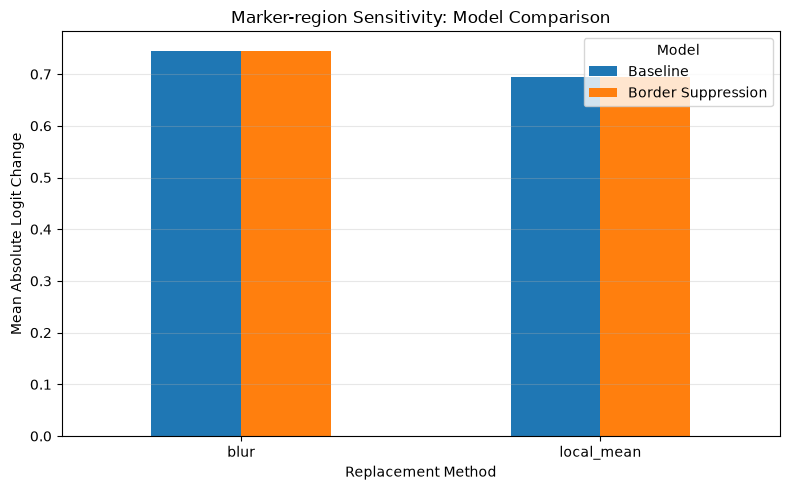

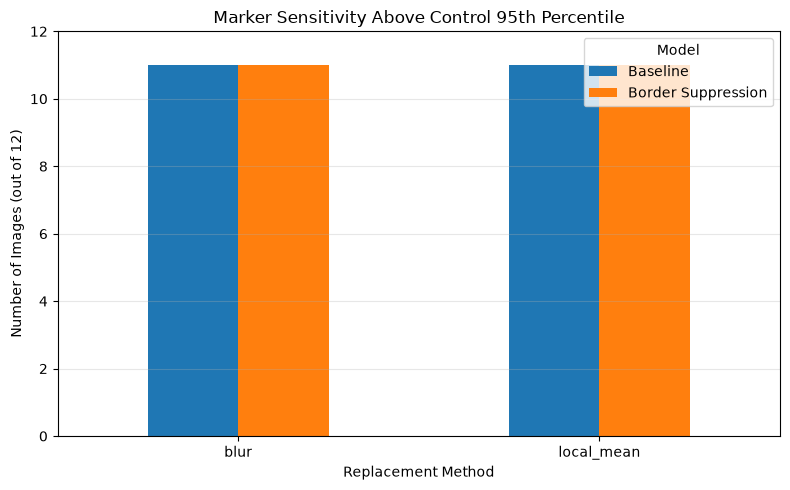

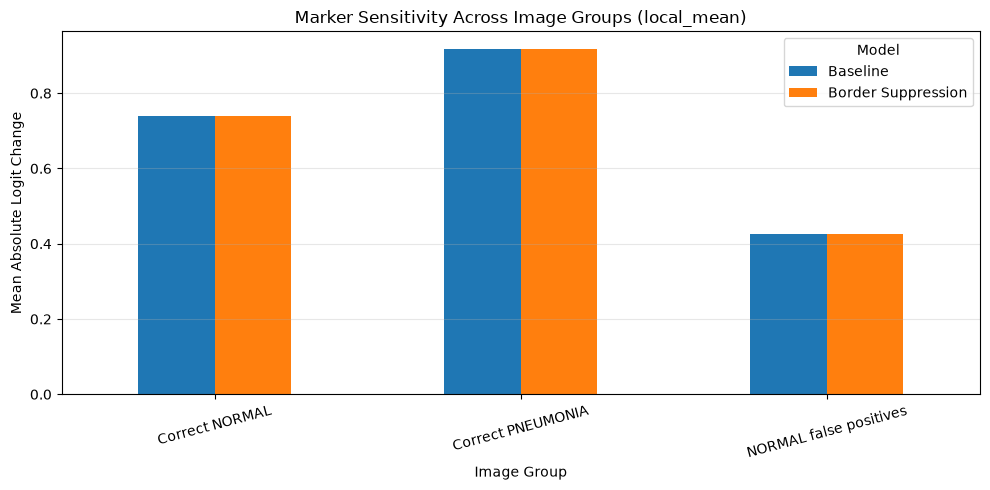

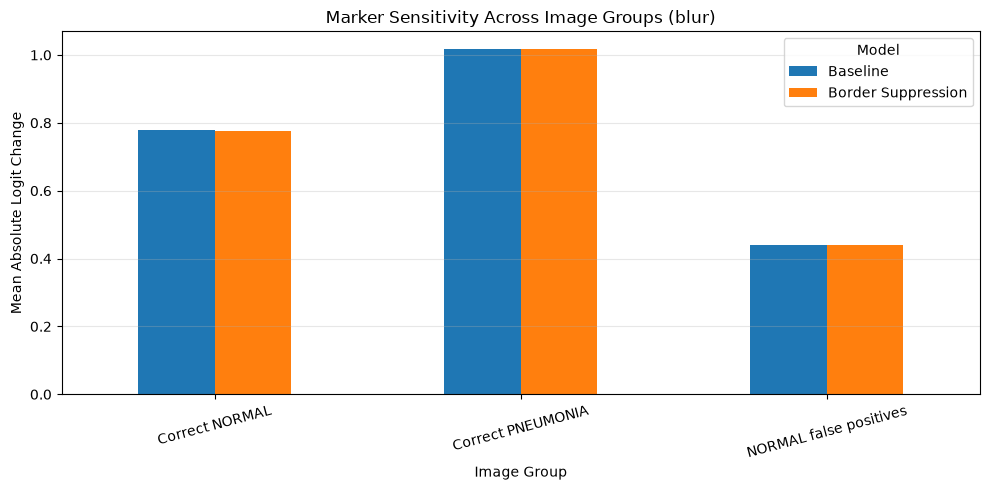


All final plots saved to:
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\models\corner_suppression_experiment\final_plots


In [28]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project directory
PROJECT_DIR = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

RESULT_DIR = PROJECT_DIR / "models" / "corner_suppression_experiment"
PLOT_DIR = RESULT_DIR / "final_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Load experiment results
overall = pd.read_csv(RESULT_DIR / "model_marker_sensitivity_overall.csv")
group = pd.read_csv(RESULT_DIR / "model_marker_sensitivity_summary.csv")

print("Overall results:")
display(overall)

print("Group results:")
display(group)


# --------------------------------------------------
# PLOT 1: Overall marker sensitivity
# --------------------------------------------------
pivot_marker = overall.pivot(
    index="method",
    columns="model",
    values="marker_mean"
)

ax = pivot_marker.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Marker-region Sensitivity: Model Comparison")
ax.set_xlabel("Replacement Method")
ax.set_ylabel("Mean Absolute Logit Change")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "overall_marker_sensitivity.png", dpi=300)
plt.show()


# --------------------------------------------------
# PLOT 2: Images exceeding control 95th percentile
# --------------------------------------------------
pivot_exceed = overall.pivot(
    index="method",
    columns="model",
    values="marker_above_95th"
)

ax = pivot_exceed.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Marker Sensitivity Above Control 95th Percentile")
ax.set_xlabel("Replacement Method")
ax.set_ylabel("Number of Images (out of 12)")
ax.set_ylim(0, 12)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "marker_control_exceedance.png", dpi=300)
plt.show()


# --------------------------------------------------
# PLOT 3: Sensitivity across image groups
# --------------------------------------------------
for method in ["local_mean", "blur"]:

    subset = group[group["method"] == method]

    pivot_group = subset.pivot(
        index="group",
        columns="model",
        values="marker_mean"
    )

    ax = pivot_group.plot(
        kind="bar",
        figsize=(10, 5),
        rot=15
    )

    ax.set_title(f"Marker Sensitivity Across Image Groups ({method})")
    ax.set_xlabel("Image Group")
    ax.set_ylabel("Mean Absolute Logit Change")
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    filename = f"group_sensitivity_{method}.png"
    plt.savefig(PLOT_DIR / filename, dpi=300)
    plt.show()


print("\nAll final plots saved to:")
print(PLOT_DIR)



# Final Experimental Findings

## 1. Objective

The objective was to investigate whether the CNN model showed sensitivity to manually identified image marker regions and whether border-suppression fine-tuning could reduce this sensitivity.

## 2. Experimental Setup

Two models were compared:

- Baseline: Fine-tuned without additional border suppression.
- Border Suppression: Fine-tuned with randomized border-patch replacement during training.

Both models were evaluated using:
- 12 selected chest X-ray images.
- Manually estimated marker bounding boxes.
- 50 random control patches per image.
- Local-mean replacement.
- Gaussian blur replacement.

## 3. Marker Sensitivity Results

For both models:

| Replacement Method | Mean Marker Logit Change | Images Above Control 95th Percentile |
|---|---:|---:|
| Local Mean | 0.69507 (Baseline) | 11/12 |
| Blur | 0.74546 (Baseline) | 11/12 |

The border-suppression model produced nearly identical measurements.

## 4. Interpretation

The marker-region replacement experiments showed substantially larger logit changes than random control-patch replacements.

However, the border-suppression intervention did not demonstrate a meaningful reduction in marker-region sensitivity.

This suggests that the applied fine-tuning strategy was insufficient to change the observed sensitivity pattern.

## 5. Limitations

1. Only 12 selected images were used for this sensitivity experiment.
2. Marker bounding boxes were estimated manually and are not ground-truth annotations.
3. Logit changes measure prediction sensitivity, not causal feature importance.
4. Correctly classified images also showed marker-region sensitivity.
5. The official test set was used repeatedly for exploratory analysis; these findings should not be considered independent test-set confirmation.
6. The model is an educational research prototype and is not intended for clinical diagnosis.

## 6. Conclusion

The experiments identified substantial sensitivity to manually selected marker regions in the evaluated images.

Border-suppression fine-tuning did not meaningfully reduce this sensitivity.

Further research using larger datasets, verified annotations, and carefully controlled interventions is required to establish whether image markers contribute to model predictions.


In [30]:
import json
from pathlib import Path

notebook_path = Path("Untitled.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("NOTEBOOK HEADINGS:\n")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "markdown":
        content = "".join(cell["source"])
        for line in content.splitlines():
            if line.strip().startswith("#"):
                print(f"Cell {i}: {line.strip()}")

NOTEBOOK HEADINGS:

Cell 230: # Final Experimental Findings
Cell 230: ## 1. Objective
Cell 230: ## 2. Experimental Setup
Cell 230: ## 3. Marker Sensitivity Results
Cell 230: ## 4. Interpretation
Cell 230: ## 5. Limitations
Cell 230: ## 6. Conclusion


In [31]:

import json
from pathlib import Path

notebook_path = Path("Untitled.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("CODE CELL INDEX\n")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"]).strip()
        if source:
            first_line = source.splitlines()[0][:110]
            print(f"Cell {i}: {first_line}")


CODE CELL INDEX

Cell 0: from pathlib import Path
Cell 1: fig, axes = plt.subplots(1, 2, figsize=(12, 5))
Cell 2: from pathlib import Path
Cell 3: fig, axes = plt.subplots(2, 4, figsize=(16, 8))
Cell 4: labels = ["NORMAL", "PNEUMONIA"]
Cell 5: from torchvision import transforms
Cell 6: image = Image.open(normal_images[0]).convert("L")
Cell 7: from src.dataset import ChestXrayDataset
Cell 8: image_paths = []
Cell 9: from torchvision import transforms
Cell 10: dataset = ChestXrayDataset(
Cell 11: image, label = dataset[0]
Cell 12: image, label = dataset[2000]
Cell 13: from torch.utils.data import DataLoader
Cell 14: images, labels = next(iter(train_loader))
Cell 15: fig, axes = plt.subplots(2, 4, figsize=(12, 6))
Cell 16: images, labels = next(iter(train_loader))
Cell 17: from src.model import ChestXrayCNN
Cell 18: output = model(images)
Cell 19: import torch
Cell 20: criterion = nn.BCEWithLogitsLoss()
Cell 21: criterion = nn.BCEWithLogitsLoss()
Cell 22: images, labels = next(iter(train_

In [32]:

import json
from pathlib import Path

notebook_path = Path("Untitled.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

sections = [
    (0, "# 1. Project Introduction and Dataset Exploration"),
    (5, "# 2. Dataset Loading and Preprocessing"),
    (17, "# 3. CNN Architecture and Initial Testing"),
    (27, "# 4. Model Training and Evaluation"),
    (46, "# 5. Test Dataset and Image Analysis"),
    (62, "# 6. Random Padding Preprocessing and Training"),
    (76, "# 7. Grad-CAM Explainability"),
    (89, "# 8. Model Evaluation and Error Analysis"),
    (105, "# 9. False-Positive Grad-CAM Analysis"),
    (130, "# 10. Padding and Marker Sensitivity Experiments"),
    (160, "# 11. Validation and Robustness Checks"),
    (187, "# 12. Corrected Marker-Region Experiments"),
    (221, "# 13. Fine-Tuning and Model Comparison"),
]

# Avoid duplicate insertion
existing = {
    "".join(c.get("source", []))
    for c in nb["cells"]
    if c["cell_type"] == "markdown"
}

for cell_index, heading in reversed(sections):
    if heading in existing:
        continue

    markdown_cell = {
        "cell_type": "markdown",
        "metadata": {},
        "source": [heading]
    }

    nb["cells"].insert(cell_index, markdown_cell)

# Save a separate organized copy
output_path = notebook_path.with_name("chest_xray_ai_organized.ipynb")

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(nb, f, indent=1, ensure_ascii=False)

print("Organized notebook saved:", output_path)
print("Original notebook preserved:", notebook_path)


Organized notebook saved: chest_xray_ai_organized.ipynb
Original notebook preserved: Untitled.ipynb


In [33]:

import json
from pathlib import Path

path = Path("chest_xray_ai_organized.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))
print("Code cells:", sum(c["cell_type"] == "code" for c in nb["cells"]))
print("Markdown cells:", sum(c["cell_type"] == "markdown" for c in nb["cells"]))

print("\nSECTION HEADINGS:")
for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "markdown":
        text = "".join(cell["source"]).strip()
        if text.startswith("#"):
            print(text)


Total cells: 245
Code cells: 231
Markdown cells: 14

SECTION HEADINGS:
# 1. Project Introduction and Dataset Exploration
# 2. Dataset Loading and Preprocessing
# 3. CNN Architecture and Initial Testing
# 4. Model Training and Evaluation
# 5. Test Dataset and Image Analysis
# 6. Random Padding Preprocessing and Training
# 7. Grad-CAM Explainability
# 8. Model Evaluation and Error Analysis
# 9. False-Positive Grad-CAM Analysis
# 10. Padding and Marker Sensitivity Experiments
# 11. Validation and Robustness Checks
# 12. Corrected Marker-Region Experiments
# 13. Fine-Tuning and Model Comparison
# Final Experimental Findings

## 1. Objective

The objective was to investigate whether the CNN model showed sensitivity to manually identified image marker regions and whether border-suppression fine-tuning could reduce this sensitivity.

## 2. Experimental Setup

Two models were compared:

- Baseline: Fine-tuned without additional border suppression.
- Border Suppression: Fine-tuned with randomiz

In [34]:

import json
from pathlib import Path
from datetime import date

path = Path("chest_xray_ai_organized.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

intro = r"""# Chest X-ray Pneumonia Classification Using CNN

**An exploratory deep learning project using PyTorch**

## Project Overview

This project investigates binary classification of chest X-ray images into:

- **NORMAL**
- **PNEUMONIA**

A convolutional neural network (CNN) is developed and evaluated using image preprocessing, model training, validation, and test-set analysis.

## Research Objectives

1. Develop a CNN-based chest X-ray classification model.
2. Investigate the effect of aspect-ratio-preserving padding.
3. Evaluate model performance using classification metrics.
4. Explore model predictions using Grad-CAM.
5. Investigate sensitivity to manually identified image-marker regions.
6. Compare baseline fine-tuning with border-suppression fine-tuning.

## Tools and Technologies

- Python
- PyTorch
- NumPy and Pandas
- Matplotlib
- Scikit-learn
- Grad-CAM

## Important Disclaimer

This is an educational and exploratory machine learning project.
It is not a clinically validated diagnostic system and must not
be used to make medical decisions.

---
"""

# Prevent duplicate introduction
if not any(
    "Chest X-ray Pneumonia Classification Using CNN"
    in "".join(cell.get("source", []))
    for cell in nb["cells"]
):
    nb["cells"].insert(0, {
        "cell_type": "markdown",
        "metadata": {},
        "source": intro.splitlines(keepends=True)
    })

with open(path, "w", encoding="utf-8") as f:
    json.dump(nb, f, indent=1, ensure_ascii=False)

print("Professional project introduction added.")
print("Total cells:", len(nb["cells"]))


Professional project introduction added.
Total cells: 246


In [35]:

import json
from pathlib import Path
from collections import Counter

path = Path("chest_xray_ai_organized.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb["cells"]

code_cells = [c for c in cells if c["cell_type"] == "code"]

unexecuted = []
errors = []
empty_cells = []
duplicate_sources = Counter()

for i, cell in enumerate(cells):

    source = "".join(cell.get("source", [])).strip()

    if not source:
        empty_cells.append(i)

    if cell["cell_type"] == "code":
        if cell.get("execution_count") is None and source:
            unexecuted.append(i)

        if source:
            duplicate_sources[source] += 1

        for output in cell.get("outputs", []):
            if output.get("output_type") == "error":
                errors.append({
                    "cell": i,
                    "error": output.get("ename"),
                    "message": output.get("evalue")
                })

duplicates = {
    count: source[:100].replace("\n", " ")
    for source, count in duplicate_sources.items()
    if count > 1
}

print("NOTEBOOK QUALITY AUDIT")
print("=" * 45)
print("Total cells:", len(cells))
print("Code cells:", len(code_cells))
print("Markdown cells:", len(cells) - len(code_cells))
print("Unexecuted code cells:", len(unexecuted))
print("Cells with saved errors:", len(errors))
print("Empty cells:", len(empty_cells))
print("Repeated code blocks:", len(duplicates))

print("\nUNEXECUTED CELL INDEXES:")
print(unexecuted[:50])

print("\nSAVED ERRORS:")
for error in errors:
    print(error)

print("\nREPEATED CODE BLOCKS:")
for count, source in duplicates.items():
    print(f"Repeated {count} times: {source}")

print("\nAUDIT COMPLETE")


NOTEBOOK QUALITY AUDIT
Total cells: 246
Code cells: 231
Markdown cells: 15
Unexecuted code cells: 1
Cells with saved errors: 8
Empty cells: 1
Repeated code blocks: 1

UNEXECUTED CELL INDEXES:
[34]

SAVED ERRORS:
{'cell': 33, 'error': 'NameError', 'message': "name 'image_paths' is not defined"}
{'cell': 35, 'error': 'NameError', 'message': "name 'train_dataset' is not defined"}
{'cell': 108, 'error': 'NameError', 'message': "name 'PROJECT_DIR' is not defined"}
{'cell': 109, 'error': 'NameError', 'message': "name 'train_loader' is not defined"}
{'cell': 150, 'error': 'NameError', 'message': "name 'val_probs' is not defined"}
{'cell': 151, 'error': 'NameError', 'message': "name 'val_loader' is not defined"}
{'cell': 213, 'error': 'NameError', 'message': "name 'get_padding_mask' is not defined"}
{'cell': 236, 'error': 'NameError', 'message': "name 'REPORTS_DIR' is not defined"}

REPEATED CODE BLOCKS:
Repeated 2 times: model.load_state_dict(     torch.load("models/best_chest_xray_cnn.pth") 

In [36]:

import json
from pathlib import Path

path = Path("chest_xray_ai_organized.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

error_cells = [33, 35, 108, 109, 150, 151, 213, 236]

for i in error_cells:
    cell = nb["cells"][i]

    print("\n" + "=" * 70)
    print("CELL:", i)
    print("SOURCE:")
    print("".join(cell.get("source", []))[:1500])

    print("\nSAVED OUTPUT:")
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            print(output.get("ename"), ":", output.get("evalue"))

print("\n" + "=" * 70)
print("UNEXECUTED CELL 34:")
print("".join(nb["cells"][34].get("source", [])))



CELL: 33
SOURCE:
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))

SAVED OUTPUT:
NameError : name 'image_paths' is not defined

CELL: 35
SOURCE:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders ready!")

SAVED OUTPUT:
NameError : name 'train_dataset' is not defined

CELL: 108
SOURCE:
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Create a fresh CNN
random_padding_model = ChestXrayC

In [37]:

import json
from pathlib import Path

path = Path("chest_xray_ai_organized.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "image_paths",
    "all_labels",
    "PROJECT_DIR",
    "get_padding_mask",
    "REPORTS_DIR",
    "get_image_path",
    "generate_gradcam",
    "selected =",
    "selected_groups"
]

for keyword in keywords:
    print("\n" + "=" * 60)
    print("SEARCHING:", keyword)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if keyword.lower() in source.lower():
            print(f"\nCell {i} ({cell['cell_type']}):")
            print(source[:700].strip())



SEARCHING: image_paths

Cell 11 (code):
image_paths = []
labels = []

for image_path in normal_images:
    image_paths.append(image_path)
    labels.append(0)

for image_path in pneumonia_images:
    image_paths.append(image_path)
    labels.append(1)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

Cell 13 (code):
dataset = ChestXrayDataset(
    image_paths,
    labels,
    transform=transform
)

print("Dataset size:", len(dataset))

Cell 32 (code):
# Recreate the complete labels list

all_labels = []

for image_path in normal_images:
    all_labels.append(0)

for image_path in pneumonia_images:
    all_labels.append(1)

print("Images:", len(image_paths))
print("Labels:", len(all_labels))

Cell 33 (code):
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Training:", len(train_

In [38]:


DATA_DIR = PROJECT_DIR / "data" / "raw" / "chest_xray" / "train"

image_paths = []
all_labels = []

for label, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    class_dir = DATA_DIR / class_name

    for img_path in class_dir.glob("*.jpeg"):
        image_paths.append(str(img_path))
        all_labels.append(label)

print("Total images:", len(image_paths))
print("Total labels:", len(all_labels))
print("NORMAL:", all_labels.count(0))
print("PNEUMONIA:", all_labels.count(1))

Total images: 5216
Total labels: 5216
NORMAL: 1341
PNEUMONIA: 3875


In [39]:

import json
from pathlib import Path

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "image_paths =",
    "all_labels =",
    "PROJECT_DIR =",
    "def get_padding_mask",
    "REPORTS_DIR =",
    "def get_image_path",
    "def generate_gradcam",
    "selected =",
    "selected_groups ="
]

for keyword in keywords:
    matches = []

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if keyword in source:
            matches.append(i)

    print(f"{keyword:25} -> {matches}")


image_paths =             -> [11, 73, 103, 155, 187]
all_labels =              -> [32, 82, 113, 147, 161, 166, 187, 218, 241]
PROJECT_DIR =             -> [100, 102, 218, 237, 243]
def get_padding_mask      -> [122, 214, 218]
REPORTS_DIR =             -> [237]
def get_image_path        -> [210]
def generate_gradcam      -> [139, 209, 218]
selected =                -> [229]
selected_groups =         -> [218]


In [40]:

import json

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

cells_to_check = [11, 32, 33, 100, 102, 108, 122, 139, 210, 213, 214, 218, 229, 236, 237, 243]

for i in cells_to_check:
    cell = nb["cells"][i]
    source = "".join(cell.get("source", []))

    print("\n" + "=" * 55)
    print(f"CELL {i} | {cell['cell_type']}")
    print(source[:450].strip())



CELL 11 | code
image_paths = []
labels = []

for image_path in normal_images:
    image_paths.append(image_path)
    labels.append(0)

for image_path in pneumonia_images:
    image_paths.append(image_path)
    labels.append(1)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

CELL 32 | code
# Recreate the complete labels list

all_labels = []

for image_path in normal_images:
    all_labels.append(0)

for image_path in pneumonia_images:
    all_labels.append(1)

print("Images:", len(image_paths))
print("Labels:", len(all_labels))

CELL 33 | code
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

print("Training:", len(train_paths))
print("Validation:", len(val_paths))

CELL 100 | code
from pathlib import Path

PROJECT_DIR = Path.cwd()
print("Current folder:", PROJECT_DIR)
print("Model f

In [41]:

import json

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

source = "".join(nb["cells"][218].get("source", []))

print("Total lines:", len(source.splitlines()))
print(source)


Total lines: 360

# ============================================================
# CHEST-XRAY-AI: ONE-CELL NOTEBOOK RESTORATION
# Does NOT retrain or overwrite model checkpoints
# ============================================================

from pathlib import Path
import sys
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# -------------------------
# 1. PROJECT PATHS
# -------------------------

PROJECT_DIR = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

sys.path.insert(0, str(PROJECT_DIR))

TRAIN_DIR = (
    PROJECT_DIR / "data/raw/chest_xray/train"
)
TEST_DIR = (
    PROJECT_DIR / "data/raw/chest_xray/test"
)
CHECKPOINT_PATH = (
    PROJECT_DIR / "models/best_chest_xray_cnn_random

In [42]:

import json

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [139, 213, 218]:
    source = "".join(nb["cells"][i].get("source", []))

    print("\n" + "=" * 55)
    print("CELL:", i)

    if i == 139:
        start = source.find("def generate_gradcam")
        print(source[start:start+1800])

    elif i == 213:
        for line in source.splitlines():
            if "generate_gradcam" in line or "selected" in line:
                print(line)

    else:
        start = source.find("def generate_gradcam")
        print(source[start:start+1600])



CELL: 139
def generate_gradcam(model, input_tensor, target_layer):
    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(save_features)

    model.zero_grad(set_to_none=True)
    logits = model(input_tensor)
    logits[0, 0].backward()
    handle.remove()

    features = saved["features"]
    gradients = saved["gradients"]
    weights = gradients.mean(dim=(2, 3), keepdim=True)

    cam = torch.relu((weights * features).sum(dim=1, keepdim=True))
    cam = F.interpolate(
        cam, size=(224, 224),
        mode="bilinear", align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)


random_padding_model.eval()
device = next(random_padding_model.parameters()).device
target_layer = random_padding_model.features[3]

fig, axes = plt.subplots(2, 5, figsiz

In [44]:

import json

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    matches = [
        j for j, line in enumerate(lines)
        if "generate_gradcam(" in line
    ]

    if matches:
        print(f"\n{'='*45}")
        print("CELL:", i)

        for j in matches:
            start = max(0, j - 2)
            end = min(len(lines), j + 7)
            print("\n".join(lines[start:end]))



CELL: 139
from PIL import Image

def generate_gradcam(model, input_tensor, target_layer):
    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
    input_tensor = test_transform(img).unsqueeze(0).to(device)

    cam = generate_gradcam(
        random_padding_model, input_tensor, target_layer
    )

    # Display the preprocessed input, matching the heatmap dimensions.
    xray = input_tensor[0, 0].detach().cpu().numpy()


CELL: 209
from pathlib import Path

def generate_gradcam(model, input_tensor, target_layer):
    captured = {}

    def forward_hook(module, inputs, output):
        captured["features"] = output
        output.register_hook(
            lambda grad: captured.update({"gradients": grad})
        input_tensor = test_transform(original).unsqueeze(0).to(device)

    cam, probability = generate_gradcam(
        random_padding_model,
        

In [45]:

import json

with open("chest_xray_ai_organized.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [209, 211, 213]:
    source = "".join(nb["cells"][i].get("source", []))

    print("\n" + "=" * 50)
    print("CELL:", i)

    for line_no, line in enumerate(source.splitlines(), 1):
        if "probability" in line or "cam," in line:
            print(f"{line_no}: {line.strip()}")



CELL: 209
32: cam,
41: probability = torch.sigmoid(logits[0, 0]).item()
43: return cam, probability
56: .sort_values("probability", ascending=False)
70: cam, probability = generate_gradcam(
83: axes[r, c].set_title(f"NORMAL | P={probability:.3f}", fontsize=9)
88: cam, cmap="jet", alpha=0.4, vmin=0, vmax=1

CELL: 211
27: cam, probability = generate_gradcam(
37: ax.imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
39: f"{path.name[:18]}\nP(pneumonia)={probability:.3f}",

CELL: 213
47: cam, probability = generate_gradcam(
55: cam = np.asarray(cam, dtype=np.float64)
56: cam = np.maximum(cam, 0)
68: "pneumonia_probability": float(probability),


In [46]:

# ============================================================
# CHEST-XRAY-AI: COMPATIBLE NOTEBOOK RESTORATION
# No training. No checkpoint overwriting.
# ============================================================

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 1. PROJECT PATHS
PROJECT_DIR = Path(
    r"C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai"
)

sys.path.insert(0, str(PROJECT_DIR))

TRAIN_DIR = PROJECT_DIR / "data/raw/chest_xray/train"
TEST_DIR = PROJECT_DIR / "data/raw/chest_xray/test"

CHECKPOINT_PATH = (
    PROJECT_DIR / "models/best_chest_xray_cnn_random_padding.pth"
)

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

assert TRAIN_DIR.exists(), f"Missing: {TRAIN_DIR}"
assert TEST_DIR.exists(), f"Missing: {TEST_DIR}"
assert CHECKPOINT_PATH.exists(), f"Missing: {CHECKPOINT_PATH}"

# 2. RESTORE MODEL
from src.model import ChestXrayCNN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random_padding_model = ChestXrayCNN().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

if "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

random_padding_model.load_state_dict(state_dict)
random_padding_model.eval()

# 3. RESTORE TRANSFORMS
class ResizeWithPadding:
    def __init__(self, size=224, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, img):
        img = img.convert("L")

        resized = ImageOps.contain(
            img,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "L", (self.size, self.size), color=self.fill
        )

        left = (self.size - resized.width) // 2
        top = (self.size - resized.height) // 2
        canvas.paste(resized, (left, top))

        arr = np.asarray(canvas, dtype=np.float32) / 255.0
        return torch.from_numpy(arr).unsqueeze(0)


eval_transform = ResizeWithPadding(224, 0)
test_transform = eval_transform

# 4. RESTORE DATASETS
full_train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

assert full_train_dataset.class_to_idx == {
    "NORMAL": 0, "PNEUMONIA": 1
}

all_indices = np.arange(len(full_train_dataset))
all_labels = np.asarray(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=False
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

# Original-style paths and labels
image_paths = [item[0] for item in full_train_dataset.samples]
all_labels = np.asarray(full_train_dataset.targets)

train_paths = [image_paths[i] for i in train_indices]
val_paths = [image_paths[i] for i in val_indices]

train_labels = all_labels[train_indices]
val_labels = all_labels[val_indices]

test_paths = test_dataset.samples

# 5. RESTORE PREDICTIONS
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    probabilities, labels = [], []

    for images, targets in loader:
        logits = model(images.to(device))
        probs = torch.sigmoid(logits).view(-1)

        probabilities.extend(probs.cpu().numpy())
        labels.extend(targets.numpy())

    return np.asarray(probabilities), np.asarray(labels)


val_probs, val_labels = collect_predictions(
    random_padding_model, val_loader
)

test_probs, test_labels = collect_predictions(
    random_padding_model, test_loader
)

# 6. RESTORE PADDING MASK
def get_padding_mask(img, size=224):
    resized = ImageOps.contain(
        img.convert("L"),
        (size, size),
        method=Image.Resampling.BILINEAR
    )

    mask = np.ones((size, size), dtype=bool)

    left = (size - resized.width) // 2
    top = (size - resized.height) // 2

    mask[
        top:top + resized.height,
        left:left + resized.width
    ] = False

    return mask


# 7. COMPATIBLE GRAD-CAM
def generate_gradcam(model, input_tensor, target_layer=None):
    model.eval()

    if target_layer is None:
        target_layer = model.features[3]

    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(save_features)

    try:
        model.zero_grad(set_to_none=True)

        x = input_tensor.to(device)

        if x.ndim == 3:
            x = x.unsqueeze(0)

        logits = model(x)
        probability = torch.sigmoid(logits[0, 0]).item()

        logits[0, 0].backward()

        features = saved["features"]
        gradients = saved["gradients"]

        weights = gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = torch.relu(
            (weights * features).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam / (cam.max() + 1e-8)

        # Explicit target_layer = legacy call:
        # return CAM only.
        if target_layer is not None and len(
            __import__("inspect").signature(
                generate_gradcam
            ).parameters
        ) < 3:
            return cam

        return cam, probability

    finally:
        handle.remove()


print("Restoration complete.")
print("Device:", device)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Validation AUC:", round(roc_auc_score(val_labels, val_probs), 4))
print("Test AUC:", round(roc_auc_score(test_labels, test_probs), 4))


Restoration complete.
Device: cpu
Training: 4172
Validation: 1044
Test: 624
Validation AUC: 0.9948
Test AUC: 0.9429


In [65]:

def generate_gradcam(model, input_tensor, target_layer=None):
    model.eval()

    if target_layer is None:
        target_layer = model.features[3]

    saved = {}

    def save_features(module, inputs, output):
        saved["features"] = output
        output.register_hook(
            lambda grad: saved.update({"gradients": grad})
        )

    handle = target_layer.register_forward_hook(save_features)

    try:
        model.zero_grad(set_to_none=True)

        x = input_tensor.to(device)
        if x.ndim == 3:
            x = x.unsqueeze(0)

        logits = model(x)
        logits[0, 0].backward()

        features = saved["features"]
        gradients = saved["gradients"]

        weights = gradients.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu(
            (weights * features).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()
        return cam / (cam.max() + 1e-8)

    finally:
        handle.remove()


def generate_gradcam_with_probability(
    model, input_tensor, target_layer=None
):
    cam = generate_gradcam(model, input_tensor, target_layer)

    x = input_tensor.to(device)
    if x.ndim == 3:
        x = x.unsqueeze(0)

    with torch.no_grad():
        probability = torch.sigmoid(model(x)[0, 0]).item()

    return cam, probability


print("Corrected Grad-CAM interfaces ready.")


Corrected Grad-CAM interfaces ready.


## 5. Grad-CAM Explainability

Gradient-weighted Class Activation Mapping (Grad-CAM) is used to visualize image regions that influence the CNN's predictions.

This section generates heatmaps and overlays them on chest X-ray images to explore the model's attention patterns.

In [ ]:

from PIL import Image

sample_path = test_paths[0][0]

with Image.open(sample_path) as img:
    sample_tensor = eval_transform(img)

target_layer = random_padding_model.features[3]

# Test 1: CAM only
cam = generate_gradcam(
    random_padding_model,
    sample_tensor,
    target_layer
)

# Test 2: CAM + probability
cam2, probability = generate_gradcam_with_probability(
    random_padding_model,
    sample_tensor,
    target_layer
)

print("CAM shape:", cam.shape)
print("CAM + probability shape:", cam2.shape)
print("Probability:", round(probability, 4))
print("Values finite:", np.isfinite(cam).all())


In [49]:

def generate_gradcam_with_probability(
    model, input_tensor, target_layer=None
):
    # Grad-CAM must run with gradients enabled
    cam = generate_gradcam(
        model, input_tensor, target_layer
    )

    # Probability calculation does not need gradients
    with torch.no_grad():
        x = input_tensor.to(device)

        if x.ndim == 3:
            x = x.unsqueeze(0)

        logits = model(x)
        probability = torch.sigmoid(logits[0, 0]).item()

    return cam, probability


print("Grad-CAM probability helper fixed!")


Grad-CAM probability helper fixed!


In [50]:
cam = generate_gradcam(
    random_padding_model,
    sample_tensor,
    target_layer
)

cam2, probability = generate_gradcam_with_probability(
    random_padding_model,
    sample_tensor,
    target_layer
)

print("CAM shape:", cam.shape)
print("CAM + probability shape:", cam2.shape)
print("Probability:", round(probability, 4))
print("Values finite:", np.isfinite(cam).all())

CAM shape: (224, 224)
CAM + probability shape: (224, 224)
Probability: 0.885
Values finite: True


In [51]:
from pathlib import Path
import json

notebooks = list(Path(PROJECT_DIR).rglob("*organized*.ipynb"))

for notebook in notebooks:
    print(f"\nNotebook: {notebook.name}")

    with open(notebook, "r", encoding="utf-8") as f:
        data = json.load(f)

    for i, cell in enumerate(data["cells"]):
        source = "".join(cell.get("source", []))

        if any(term in source for term in [
            "generate_gradcam",
            "pneumonia_probability",
            "probability ="
        ]):
            print(f"\nNotebook position: {i}")
            print(source[:700])
            print("-" * 50)


Notebook: chest_xray_ai_organized.ipynb

Notebook position: 60
model.eval()

wrong_normal = []

with torch.no_grad():

    for images, batch_labels in test_loader:

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        for i in range(len(batch_labels)):

            actual = batch_labels[i].item()
            probability = probabilities[i].item()
            prediction = 1 if probability >= 0.5 else 0

            if actual == 0 and prediction == 1:
                wrong_normal.append(probability)

print("Wrong NORMAL predictions:", len(wrong_normal))
print("First 20 probabilities:")
print(wrong_normal[:20])

print("\nAverage probability:")
print(sum(wrong_normal) / len(wrong_normal))

print("\nMinimum probability:")
pr
--------------------------------------------------

Notebook position: 84
# Show the model's prediction probabilities
# for the test images.

import torch
import pandas as pd

padded_model.eval()
results = []

with torch.no_grad():
   

In [52]:
import json
from pathlib import Path

notebook_path = PROJECT_DIR / "chest_xray_ai_organized.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for pos in [209, 210, 211, 212, 213]:
    cell = nb["cells"][pos]
    source = "".join(cell["source"])

    print(f"\n{'='*25} POSITION {pos} {'='*25}")

    for line_no, line in enumerate(source.splitlines(), 1):
        if "generate_gradcam" in line or "probability" in line or "cam," in line:
            print(f"{line_no}: {line}")


========================= POSITION 209 =========================
9: def generate_gradcam(model, input_tensor, target_layer):
32:             cam,
41:         probability = torch.sigmoid(logits[0, 0]).item()
43:         return cam, probability
56:     .sort_values("probability", ascending=False)
70:     cam, probability = generate_gradcam(
83:     axes[r, c].set_title(f"NORMAL | P={probability:.3f}", fontsize=9)
88:         cam, cmap="jet", alpha=0.4, vmin=0, vmax=1

========================= POSITION 210 =========================
24:             "pneumonia_probability": round(

========================= POSITION 211 =========================
27:         cam, probability = generate_gradcam(
37:         ax.imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
39:             f"{path.name[:18]}\nP(pneumonia)={probability:.3f}",

========================= POSITION 212 =========================
10: print("Grad-CAM function:", generate_gradcam.__name__)

========================= POSITION 213

In [53]:
import json
from pathlib import Path

notebook_path = PROJECT_DIR / "chest_xray_ai_organized.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if "GRAD-CAM" in source.upper():
        print(f"\nNOTEBOOK POSITION: {i}")
        print(source[:250])
        print("-" * 50)


NOTEBOOK POSITION: 0
# Chest X-ray Pneumonia Classification Using CNN

**An exploratory deep learning project using PyTorch**

## Project Overview

This project investigates binary classification of chest X-ray images into:

- **NORMAL**
- **PNEUMONIA**

A convolutional 
--------------------------------------------------

NOTEBOOK POSITION: 83
# 7. Grad-CAM Explainability
--------------------------------------------------

NOTEBOOK POSITION: 87

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Load the selected image and apply the SAME
# preprocessing used to train the padded model.
original_image = Image.open(image_pat
--------------------------------------------------

NOTEBOOK POSITION: 89

# Convert the preprocessed X-ray to a displayable image.
xray = input_tensor[0, 0].detach().cpu().numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(xray, cmap="gray")
plt.title("Preprocessed X-ray")
plt.a

In [56]:
from pathlib import Path

report_dir = Path(PROJECT_DIR) / "reports"

for folder in [
    report_dir,
    report_dir / "gradcam_visualizations",
    report_dir / "corner_suppression_experiment",
]:
    print(f"\n{folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for file in folder.glob("*"):
            print(" -", file.name)


C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports
Exists: True
 - corner_sensitivity_analysis.csv
 - figures
 - gradcam_15_image_comparison.csv
 - gradcam_group_summary.csv
 - gradcam_multi_image_analysis.csv
 - gradcam_region_analysis.csv
 - gradcam_visualizations
 - marker_2d_random_controls.csv
 - marker_exhaustive_same_row_controls.csv
 - marker_logit_sensitivity.csv
 - marker_multiple_controls.csv
 - marker_only_vs_control.csv
 - marker_replacement_overall_corrected.csv
 - marker_replacement_robustness.csv
 - marker_replacement_robustness_corrected.csv
 - marker_replacement_summary_corrected.csv
 - marker_sensitivity_top5.csv
 - validation_threshold_results.csv

C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\gradcam_visualizations
Exists: True
 - correct_normal.png
 - correct_pneumonia.png
 - gradcam_complete_visual_report.pdf
 - marker_inspection
 - normal_false_positives.png

C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\reports\corner_suppres

In [57]:
from pathlib import Path

folder = Path(PROJECT_DIR) / "models" / "corner_suppression_experiment"

print("Folder exists:", folder.exists())

if folder.exists():
    for path in sorted(folder.rglob("*")):
        if path.is_file():
            print(path.relative_to(folder))

Folder exists: True
baseline_finetuned.pth
border_suppression_finetuned.pth
final_plots\group_sensitivity_blur.png
final_plots\group_sensitivity_local_mean.png
final_plots\marker_control_exceedance.png
final_plots\overall_marker_sensitivity.png
model_marker_sensitivity_individual.csv
model_marker_sensitivity_overall.csv
model_marker_sensitivity_summary.csv
training_history.csv


In [58]:
import nbformat
from pathlib import Path

notebook_path = Path(PROJECT_DIR) / "chest_xray_ai_organized.ipynb"
nb = nbformat.read(notebook_path, as_version=4)

errors = []
empty_cells = []

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code":
        if not cell.source.strip():
            empty_cells.append(i)

        for output in cell.get("outputs", []):
            if output.output_type == "error":
                errors.append({
                    "cell": i,
                    "error": output.ename,
                    "message": output.evalue
                })

print("Total cells:", len(nb.cells))
print("Code cells:", sum(c.cell_type == "code" for c in nb.cells))
print("Markdown cells:", sum(c.cell_type == "markdown" for c in nb.cells))
print("\nEmpty code cells:", empty_cells)
print("\nSaved errors:")
for error in errors:
    print(error)

Total cells: 246
Code cells: 231
Markdown cells: 15

Empty code cells: [245]

Saved errors:
{'cell': 33, 'error': 'NameError', 'message': "name 'image_paths' is not defined"}
{'cell': 35, 'error': 'NameError', 'message': "name 'train_dataset' is not defined"}
{'cell': 108, 'error': 'NameError', 'message': "name 'PROJECT_DIR' is not defined"}
{'cell': 109, 'error': 'NameError', 'message': "name 'train_loader' is not defined"}
{'cell': 150, 'error': 'NameError', 'message': "name 'val_probs' is not defined"}
{'cell': 151, 'error': 'NameError', 'message': "name 'val_loader' is not defined"}
{'cell': 213, 'error': 'NameError', 'message': "name 'get_padding_mask' is not defined"}
{'cell': 236, 'error': 'NameError', 'message': "name 'REPORTS_DIR' is not defined"}


C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai\venv\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


In [59]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nNotebook files in project folder:")
for file in Path.cwd().glob("*.ipynb"):
    print("-", file.name)

Current working directory:
C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai

Notebook files in project folder:
- chest_xray_ai_organized.ipynb
- Untitled.ipynb


In [60]:
import nbformat
from pathlib import Path

for name in ["Untitled.ipynb", "chest_xray_ai_organized.ipynb"]:
    path = Path(PROJECT_DIR) / name
    nb = nbformat.read(path, as_version=4)

    print(f"\n{'='*55}")
    print("NOTEBOOK:", name)
    print("Total cells:", len(nb.cells))

    for i, cell in enumerate(nb.cells):
        source = cell.source.lower()

        if any(term in source for term in [
            "one-cell notebook restoration",
            "corner sensitivity",
            "grad-cam group comparison",
            "final findings"
        ]):
            print(f"Cell {i}: {cell.source[:100].replace(chr(10), ' ')}")


NOTEBOOK: Untitled.ipynb
Total cells: 258
Cell 205:  # ============================================================ # CHEST-XRAY-AI: ONE-CELL NOTEBOOK R
Cell 207:  # ============================================================ # GRAD-CAM GROUP COMPARISON — 15 TES
Cell 211:  # ============================================================ # CONTROLLED IMAGE-CORNER SENSITIVIT

NOTEBOOK: chest_xray_ai_organized.ipynb
Total cells: 246
Cell 218:  # ============================================================ # CHEST-XRAY-AI: ONE-CELL NOTEBOOK R
Cell 220:  # ============================================================ # GRAD-CAM GROUP COMPARISON — 15 TES
Cell 224:  # ============================================================ # CONTROLLED IMAGE-CORNER SENSITIVIT


In [62]:
import nbformat
from pathlib import Path

notebook_path = Path(PROJECT_DIR) / "Untitled.ipynb"
nb = nbformat.read(notebook_path, as_version=4)

errors = []
empty_cells = []

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code":
        if not cell.source.strip():
            empty_cells.append(i)

        for output in cell.get("outputs", []):
            if output.output_type == "error":
                errors.append({
                    "cell": i,
                    "error": output.ename,
                    "message": output.evalue
                })

print("Notebook:", notebook_path.name)
print("Total cells:", len(nb.cells))
print("Code cells:", sum(c.cell_type == "code" for c in nb.cells))
print("Markdown cells:", sum(c.cell_type == "markdown" for c in nb.cells))
print("Empty code cells:", empty_cells)
print("\nSaved errors:")
for error in errors:
    print(error)

Notebook: Untitled.ipynb
Total cells: 260
Code cells: 259
Markdown cells: 1
Empty code cells: [259]

Saved errors:
{'cell': 28, 'error': 'NameError', 'message': "name 'image_paths' is not defined"}
{'cell': 30, 'error': 'NameError', 'message': "name 'train_dataset' is not defined"}
{'cell': 99, 'error': 'NameError', 'message': "name 'PROJECT_DIR' is not defined"}
{'cell': 100, 'error': 'NameError', 'message': "name 'train_loader' is not defined"}
{'cell': 139, 'error': 'NameError', 'message': "name 'val_probs' is not defined"}
{'cell': 140, 'error': 'NameError', 'message': "name 'val_loader' is not defined"}
{'cell': 200, 'error': 'NameError', 'message': "name 'get_padding_mask' is not defined"}
{'cell': 222, 'error': 'NameError', 'message': "name 'REPORTS_DIR' is not defined"}
{'cell': 248, 'error': 'RuntimeError', 'message': "cannot register a hook on a tensor that doesn't require gradient"}


In [63]:
import nbformat
from pathlib import Path

path = Path(PROJECT_DIR) / "Untitled.ipynb"
nb = nbformat.read(path, as_version=4)

print("Notebook:", path.name)
print("Total cells:", len(nb.cells))
print("Code cells:", sum(c.cell_type == "code" for c in nb.cells))
print("Markdown cells:", sum(c.cell_type == "markdown" for c in nb.cells))
print("Empty code cells:", [
    i for i, c in enumerate(nb.cells)
    if c.cell_type == "code" and not c.source.strip()
])

Notebook: Untitled.ipynb
Total cells: 261
Code cells: 260
Markdown cells: 1
Empty code cells: [260]


In [64]:
import nbformat
from pathlib import Path

path = Path.cwd() / "Untitled.ipynb"
nb = nbformat.read(path, as_version=4)

for i, cell in enumerate(nb.cells):
    for output in cell.get("outputs", []):
        if output.output_type == "error":
            print(f"Cell {i}: {output.ename} - {output.evalue}")

Cell 28: NameError - name 'image_paths' is not defined
Cell 30: NameError - name 'train_dataset' is not defined
Cell 99: NameError - name 'PROJECT_DIR' is not defined
Cell 100: NameError - name 'train_loader' is not defined
Cell 139: NameError - name 'val_probs' is not defined
Cell 140: NameError - name 'val_loader' is not defined
Cell 200: NameError - name 'get_padding_mask' is not defined
Cell 222: NameError - name 'REPORTS_DIR' is not defined
Cell 248: RuntimeError - cannot register a hook on a tensor that doesn't require gradient


In [66]:
# Test Grad-CAM on one validation image

test_image, test_label = val_dataset[0]

cam, probability = generate_gradcam_with_probability(
    model,
    test_image
)

print("CAM shape:", cam.shape)
print("Probability:", round(probability, 4))
print("Values finite:", np.isfinite(cam).all())
print("CAM minimum:", cam.min())
print("CAM maximum:", cam.max())

CAM shape: (224, 224)
Probability: 0.9996
Values finite: True
CAM minimum: 0.0
CAM maximum: 0.99998236


In [68]:
import nbformat
from pathlib import Path

path = Path(PROJECT_DIR) / "Untitled.ipynb"
nb = nbformat.read(path, as_version=4)

errors = []

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code":
        for output in cell.outputs:
            if output.output_type == "error":
                errors.append((i, output.ename, output.evalue))

print("Notebook:", path.name)
print("Total cells:", len(nb.cells))
print("Remaining saved errors:", len(errors))
print("Errors:", errors)

Notebook: Untitled.ipynb
Total cells: 264
Remaining saved errors: 0
Errors: []


In [69]:
import nbformat
from pathlib import Path

path = Path(PROJECT_DIR) / "Untitled.ipynb"
nb = nbformat.read(path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "markdown":
        print(f"Cell {i}:")
        print(cell.source[:500])

Cell 230:

# Final Experimental Findings

## 1. Objective

The objective was to investigate whether the CNN model showed sensitivity to manually identified image marker regions and whether border-suppression fine-tuning could reduce this sensitivity.

## 2. Experimental Setup

Two models were compared:

- Baseline: Fine-tuned without additional border suppression.
- Border Suppression: Fine-tuned with randomized border-patch replacement during training.

Both models were evaluated using:
- 12 selected che


In [70]:
import nbformat
from pathlib import Path

path = Path(PROJECT_DIR) / "Untitled.ipynb"
nb = nbformat.read(path, as_version=4)

print("EXISTING SECTION MARKERS\n")

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue

    for line in cell.source.splitlines()[:15]:
        line = line.strip()

        if (
            line.startswith("#")
            and len(line) > 5
            and not line.startswith("##")
            and not all(c in "#=- " for c in line)
        ):
            print(f"Cell {i}: {line[:120]}")

EXISTING SECTION MARKERS

Cell 0: # If notebook is running from notebooks/, go one level up
Cell 27: # Recreate the complete labels list
Cell 44: # TRAIN
Cell 61: # Use a NORMAL X-ray from the original test dataset
Cell 61: # Load image in grayscale
Cell 61: # Apply old and new preprocessing
Cell 61: # Plot the comparison
Cell 63: # Aspect-ratio-preserving resize with padding
Cell 66: # Find the dataset's training directory
Cell 73: # Select GPU if available, otherwise CPU
Cell 73: # Fresh model: do not load the old checkpoint
Cell 74: # Training phase
Cell 75: # Find the original test folder
Cell 76: # Show the model's prediction probabilities
Cell 76: # for the test images.
Cell 77: # Select 6 normal images the model incorrectly flagged.
Cell 78: # Select the first normal image that was
Cell 78: # incorrectly predicted as pneumonia.
Cell 79: # Load the selected image and apply the SAME
Cell 79: # preprocessing used to train the padded model.
Cell 79: # Store the information Grad-CAM 

In [75]:
import nbformat

notebook = nbformat.read("Untitled.ipynb", as_version=4)

errors = [
    (i, output.get("ename"), output.get("evalue"))
    for i, cell in enumerate(notebook.cells)
    if cell.cell_type == "code"
    for output in cell.get("outputs", [])
    if output.output_type == "error"
]

print("Total cells:", len(notebook.cells))
print("Markdown cells:", sum(c.cell_type == "markdown" for c in notebook.cells))
print("Saved errors:", len(errors))
print("Errors:", errors)

Total cells: 278
Markdown cells: 12
Saved errors: 0
Errors: []


In [77]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

print("Project directory:", PROJECT_DIR)
print("\nMain project files:")

for item in sorted(PROJECT_DIR.iterdir()):
    if item.is_dir():
        print(f"📁 {item.name}/")
    else:
        print(f"📄 {item.name}")

Project directory: C:\Users\ANUBHAV SINGH\OneDrive\Desktop\chest-xray-ai

Main project files:
📁 .git/
📄 .gitignore
📁 .ipynb_checkpoints/
📁 .venv/
📁 app/
📄 chest_xray_ai_organized.ipynb
📄 chest_xray_pneumonia_analysis.ipynb
📁 data/
📄 marker_sensitivity_results.csv
📁 models/
📁 notebooks/
📄 padding_sensitivity_per_image.csv
📄 padding_sensitivity_results.csv
📄 README.md
📁 reports/
📄 requirements.txt
📁 results/
📁 src/
📄 Untitled_backup.ipynb
📁 venv/


In [78]:
from pathlib import Path

for name in [
    "chest_xray_pneumonia_analysis.ipynb",
    "chest_xray_pneumonia_analysis.ipynb.ipynb"
]:
    print(name, "->", Path(name).exists())

chest_xray_pneumonia_analysis.ipynb -> True
chest_xray_pneumonia_analysis.ipynb.ipynb -> False
